# Causal Bayesian Network trên dữ liệu UCI In-Vehicle Coupon

- Lê Anh Tuấn - 252805005
- Tô Hoàng Đạo - 252805401

**Môn:** IT701100, Mô hình đồ thị có xác suất.

**Câu hỏi.** Nếu *mọi* coupon đều được đặt hạn dùng **2 giờ** thay vì **1 ngày**, tỉ lệ tài xế chấp nhận coupon thay đổi bao nhiêu?

Thực nghiệm trên 3 mô hình

| Mô hình | Directed Acyclic Graph - DAG | CPD của Y | So với B0 |
|---|---|---|---|
| **B0** | Hill Climbing | đếm trong dữ liệu, có làm trơn (BDeu) | mô hình gốc |
| **H1** | DAG của B0 | một neural network nhỏ (MLP) | đổi **cách tính xác suất của Y** |
| **H2** | neural network học DAG (NOTEARS-MLP) | tương tự B0 | đổi **cách tìm DAG** |


## Mục lục

1. [Chuẩn bị](#1)
2. [Bài toán](#2)
3. [Dữ liệu](#3)
4. [Chia dữ liệu](#4)
5. [Tính tay trước](#5)
6. [Ràng buộc DAG](#6)
7. [Khảo sát thuật toán](#7)
8. [B0: DAG truyền thống](#8)
9. [H1: xác suất bằng neural network](#9)
10. [H2: DAG bằng neural network](#10)
11. [Chạy 5 lần](#11)
12. [Bảng A: dự đoán](#12)
13. [Bảng B: intervention](#13)
14. [Bảng C: độ tin cậy và chi phí](#14)
15. [Kết luận](#15)


<a id="1"></a>
## 1. Chuẩn bị

**Cách chạy.**

- *Máy cá nhân:* tạo môi trường Python 3.13 (`python3.13 -m venv .venv313`), cài `pip install -r requirements.txt`, rồi chọn Kernel → Restart & Run All. Lần chạy đầy đủ ngày 13/11/2026 mất khoảng 10 phút rưỡi trên CPU 8 lõi, không cần GPU, trong lúc máy còn chạy việc khác (thời gian từng seed được in ở mục 11). Bản này chậm hơn notebook 04 chủ yếu vì NOTEARS phải học trên 18 nút thay vì 14.
- *Google Colab:* chỉ cần tải file notebook này lên.
- *Chạy thử nhanh (khoảng 1 phút):* đặt biến môi trường `COUPON_QUICK=1` trước khi mở notebook, hoặc sửa `QUICK = True` ở ô cấu hình. Khi đó chỉ chạy 2 seed với rất ít lần lặp, số liệu chỉ để kiểm tra code.

In [1]:
import sys, subprocess, os

# Colab chưa có sẵn pgmpy và dowhy nên phải cài; máy cá nhân đã cài qua requirements.txt thì bỏ qua.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pgmpy>=1.1", "dowhy>=0.12", "torch",
                    "scikit-learn", "networkx>=3.3", "matplotlib", "pandas", "numpy", "scipy"], check=True)
print("Đang chạy trên Colab:", IN_COLAB)

Đang chạy trên Colab: False


In [2]:
# ----- Thư viện có sẵn của Python -----
import json, time, hashlib, itertools, functools, platform, random, warnings, logging, io, zipfile, urllib.request
from dataclasses import dataclass, asdict
from pathlib import Path

# ----- Tính toán, bảng số liệu, vẽ hình -----
import numpy as np                      # mảng số
import pandas as pd                     # bảng dữ liệu (DataFrame)
import networkx as nx                   # đồ thị (nút, cạnh)
import matplotlib.pyplot as plt         # vẽ hình
from matplotlib.colors import LinearSegmentedColormap   # tự tạo dải màu cho bản đồ nhiệt
import scipy.stats as st                # kiểm định thống kê (chi-square)
import torch                            # mạng nơ-ron (dùng cho H1 và H2)
import sklearn, pgmpy, dowhy
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss, log_loss
from IPython.display import display

# ----- pgmpy: mạng Bayes rời rạc -----
from pgmpy.models import DiscreteBayesianNetwork                       # mạng Bayes = DAG + bảng xác suất
from pgmpy.estimators import HillClimbSearch, PC, ExpertKnowledge      # học DAG + khai báo ràng buộc
from pgmpy.estimators import BayesianEstimator                         # học bảng xác suất có làm trơn
from pgmpy.factors.discrete import TabularCPD                          # một bảng xác suất có điều kiện
from pgmpy.inference import VariableElimination                        # tính xác suất trên mạng

# ----- DoWhy: kiểm tra phép can thiệp -----
from dowhy import CausalModel

# Tắt các dòng cảnh báo dài để output gọn, dễ đọc
warnings.filterwarnings("ignore")
logging.getLogger("dowhy").setLevel(logging.ERROR)
logging.getLogger("pgmpy").setLevel(logging.ERROR)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

# ----- Kiểu hình vẽ dùng chung -----
# Mỗi mô hình một màu và một kiểu chấm cố định trong MỌI hình; hai loại hạn coupon cũng vậy.
# (Bộ màu đã được kiểm tra là người mù màu vẫn phân biệt được; kiểu chấm khác nhau là lớp bảo hiểm thứ hai.)
COLOR = {"B0": "#2a78d6", "H1": "#eb6834", "H2": "#1baf7a"}        # xanh dương, cam, xanh ngọc
MARKER = {"B0": "o", "H1": "s", "H2": "D"}                         # tròn, vuông, thoi
ARM_COLOR = {"0": "#6250d6", "1": "#eda100"}                       # hạn 1 ngày: tím; hạn 2 giờ: vàng
ARM_LABEL = {"0": "hạn 1 ngày (T = 0)", "1": "hạn 2 giờ (T = 1)"}
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"             # màu chữ chính, chữ phụ, chữ mờ
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_SOFT, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
                     "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

# Thư mục làm việc: chạy từ thư mục gốc dự án, từ notebooks/ hay trên Colab đều được
if IN_COLAB:
    ROOT = Path("/content/pgm_coupon")
elif Path.cwd().name in ("notebooks", "scripts"):
    ROOT = Path.cwd().parent
else:
    ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw" / "coupon"          # nơi để file dữ liệu gốc
OUT = ROOT / "artifacts" / "coupon_rules_original_habits"          # nơi lưu mọi kết quả của notebook này
RAW_DIR.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# Ghi lại phiên bản thư viện và phần cứng (đề bài yêu cầu báo cáo)
ENV = {"python": sys.version.split()[0], "máy": platform.platform(), "số lõi CPU": os.cpu_count(),
       "GPU (cuda)": torch.cuda.is_available(), "numpy": np.__version__, "pandas": pd.__version__,
       "networkx": nx.__version__, "scikit-learn": sklearn.__version__, "pgmpy": pgmpy.__version__,
       "dowhy": dowhy.__version__, "torch": torch.__version__}
pd.Series(ENV, name="giá trị").to_frame()

/Users/tuanla/workspace/master/probabilistic-graphical-models/.venv313/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


,giá trị
python,3.13.18
máy,macOS-27.0.1-arm64-arm-64bit-Mach-O
số lõi CPU,8
GPU (cuda),False
numpy,2.5.4
pandas,3.1.1
networkx,3.7
scikit-learn,1.9.1
pgmpy,1.1.2
dowhy,0.14


### 1.1 Cấu hình

Centralize configuration

In [3]:
@dataclass(frozen=True) #frozen=True: không cho sửa sau khi tạo
class Config:
    # ----- Dữ liệu -----
    zip_url: str = "https://archive.ics.uci.edu/static/public/603/in+vehicle+coupon+recommendation.zip"
    csv_name: str = "in-vehicle-coupon-recommendation.csv"
    # ----- Chia dữ liệu và số lần chạy -----
    seeds: tuple = (0, 1, 2, 3, 4)          # 5 seed = 5 lần chạy cặp
    split: tuple = (0.70, 0.15, 0.15)       # tỉ lệ TRAIN / VALIDATION / TEST
    # ----- Bảng xác suất (CPD) -----
    ess: float = 5.0                        # độ mạnh làm trơn BDeu (equivalent sample size)
    # ----- B0: Hill Climbing -----
    b0_scores: tuple = ("bic-d", "bdeu", "k2")   # các hàm điểm đem thử
    b0_max_indegree: tuple = (4, 6)              # số cha tối đa của một nút đem thử
    # ----- H1: mạng nơ-ron cho xác suất của Y -----
    h1_hidden: tuple = (32, 16)             # hai lớp ẩn: 32 rồi 16 nơ-ron
    h1_dropout: float = 0.2                 # tắt ngẫu nhiên 20% nơ-ron khi học
    h1_lr: float = 1e-3                     # tốc độ học
    h1_batch: int = 256                     # mỗi bước học dùng 256 dòng
    h1_max_epochs: int = 200                # tối đa 200 lượt duyệt dữ liệu
    h1_patience: int = 10                   # dừng nếu 10 lượt liền VALIDATION không tốt lên
    # ----- H2: NOTEARS-MLP học DAG -----
    h2_hidden: int = 10                     # mỗi nút có một mạng nhỏ với 10 nơ-ron ẩn
    h2_lambda1: float = 0.01                # phạt L1: ép các cạnh yếu về 0 (đồ thị thưa)
    h2_lambda2: float = 0.01                # phạt L2: giữ trọng số nhỏ
    h2_l1_scale_T: float = 0.1              # phạt L1 nhẹ hơn 10 lần cho cạnh đi vào T (giải thích ở mục 10)
    h2_max_outer: int = 20                  # số vòng ngoài tối đa
    h2_inner_steps: int = 100               # số bước tối ưu trong mỗi vòng
    h2_h_tol: float = 1e-5                  # coi là "không còn vòng kín" khi h(A) nhỏ hơn mức này (số thực 32 bit không phân biệt được mức nhỏ hơn)
    h2_rho_max: float = 1e16                # mức phạt vòng kín tối đa
    h2_thresholds: tuple = (0.05, 0.10, 0.15, 0.20, 0.30)   # các ngưỡng giữ cạnh đem thử
    # ----- Độ bất định và kiểm tra -----
    n_boot: int = 100                       # số lần bootstrap để tính khoảng tin cậy 95%
    n_refute: int = 100                     # số lần mô phỏng của mỗi refuter DoWhy
    subset_fraction: float = 0.8            # refuter "data subset" giữ lại 80% dữ liệu
    n_placebo: int = 20                     # số lần xáo trộn T cho placebo tự cài trên chính mô hình


# QUICK = True: chạy thử cực nhanh để kiểm tra code (2 seed, rất ít lần lặp) => smoke test
QUICK = os.environ.get("COUPON_QUICK", "0") == "1"
CFG = Config(seeds=(0, 1), n_boot=5, n_refute=5, n_placebo=3) if QUICK else Config()

# Bốn tầng biến theo thứ tự thời gian (giải thích ở mục 2). Thứ tự trong danh sách này dùng cho mọi bảng và ma trận.
TIERS: dict[str, list[str]] = {
    "respondent": ["Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50", "age_bin", "income_bin", "gender", "has_children"],                    # người trả lời
    "scenario": ["coupon", "destination", "time_bin", "passenger", "weather", "dist", "direction_same"],  # kịch bản lái xe
    "treatment": ["T"],                                                                                  # hạn coupon
    "outcome": ["Y"],                                                                                    # có nhận coupon không
}
NODES: list[str] = [n for tier in TIERS.values() for n in tier]                          # 18 nút của DAG
TIER_OF: dict[str, int] = {n: k for k, tier in enumerate(TIERS.values()) for n in tier}  # nút → số thứ tự tầng (0..3)
RESP, SCEN = TIERS["respondent"], TIERS["scenario"]
COVARIATES: list[str] = RESP + SCEN       # 16 biến nền: mọi thứ biết được TRƯỚC khi coupon hiện ra
print("QUICK =", QUICK, "| số nút:", len(NODES), "| seeds:", CFG.seeds, "| n_boot:", CFG.n_boot)


def set_seed(seed: int) -> np.random.Generator:
    """Cố định mọi nguồn ngẫu nhiên để chạy lại ra đúng kết quả cũ.

    Tham số: seed — một số nguyên bất kỳ.
    Trả về: bộ sinh số ngẫu nhiên của numpy (dùng cho bootstrap và xáo trộn).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    return np.random.default_rng(seed)


def as_int(col: pd.Series) -> np.ndarray:
    """Đổi một cột chữ "0"/"1" thành số 0/1 để tính trung bình và chấm điểm.

    Tham số: col — cột T hoặc Y (đang lưu dạng chữ vì pgmpy coi mọi biến là phân loại).
    Trả về: mảng số nguyên 0/1.
    """
    return col.astype(int).to_numpy()

QUICK = False | số nút: 18 | seeds: (0, 1, 2, 3, 4) | n_boot: 100


<a id="2"></a>
## 2. Bài toán

**Bối cảnh.** Dữ liệu là một khảo sát trên Amazon Mechanical Turk (Wang và cộng sự, 2017). Người tham gia được cho xem các **tình huống lái xe giả định**: đang đi đâu, mấy giờ, thời tiết thế nào, chở ai; rồi một coupon hiện trên màn hình xe (loại quán, hạn dùng). Họ trả lời có dùng coupon đó không. Mỗi dòng dữ liệu là **một lần hỏi**, mỗi người trả lời khoảng 20 lần.

**Hai biến chính.**

- **T (treatment) = hạn coupon:** T = 0 là hạn **1 ngày** (control group), T = 1 là hạn **2 giờ** (treatment group).
- **Y (outcome, kết quả) = có chấp nhận coupon không:** Y {0, 1} ~ {không, có}

**Vì sao chọn T là hạn coupon?** có thể thay đổi + Chi phí rẻ

**Con số cần tìm (estimand).** Hiệu ứng trung bình của việc đổi hạn (ATE, average treatment effect):

$$\text{ATE} = P(Y{=}1 \mid do(T{=}1)) - P(Y{=}1 \mid do(T{=}0))$$

=> Tỉ lệ chấp nhận *nếu ép mọi coupon có hạn 2 giờ* trừ tỉ lệ chấp nhận *nếu ép mọi coupon có hạn 1 ngày*.

**Vì sao không so sánh thẳng hai nhóm coupon là xong?** Vì hai nhóm không giống nhau từ đầu. Ví dụ đời thường: nếu người khoẻ hay tập gym hơn, thì "người tập gym ít ốm hơn" chưa chắc do gym. Ở đây, loại quán và hoàn cảnh lái xe quyết định coupon được gán hạn nào, và cũng quyết định người ta có thích coupon không.

### 2.1 Glossary

| Term | Ý nghĩa | Ví dụ trong bài |
|---|---|---|
| Variable, node | Một cột dữ liệu, trong bài gọi là *biến*. Trong DAG, mỗi biến là một *nút* (node) | `coupon` = loại quán của coupon |
| State | Các giá trị mà một biến có thể nhận | `weather` nhận Sunny, Rainy hoặc Snowy |
| DAG (Directed Acyclic Graph) | Sơ đồ gồm các nút và **mũi tên một chiều**, không có vòng kín. Mũi tên A → B nghĩa là "A ảnh hưởng trực tiếp đến B" | T → Y: hạn coupon ảnh hưởng đến việc chấp nhận |
| Parents, parent set | Các nút có mũi tên trỏ **thẳng** vào một nút; *parent set* là cả nhóm đó | parents của Y có thể là T, `coupon`, `CoffeeHouse` |
| CPD (Conditional Probability Distribution) | Bảng xác suất có điều kiện: với mỗi tổ hợp giá trị của parents, nút nhận từng giá trị với xác suất bao nhiêu | P(Y = 1 khi T = 2 giờ và coupon = Bar) |
| Bayesian Network (BN) | DAG + một CPD cho mỗi nút | cả mô hình B0 |
| Observation vs. intervention, do(·) | *Observation:* nhìn những coupon vốn đã có hạn 2 giờ (dữ liệu như vậy gọi là *observational data*). *Intervention* do(T = 2 giờ): tự tay đặt mọi coupon thành 2 giờ, giữ nguyên mọi thứ khác | hai cách này cho hai con số khác nhau |
| Treatment, control group | *Treatment* là biến ta can thiệp (T). *Treatment group* là nhóm T = 1 (hạn 2 giờ), *control group* là nhóm T = 0 (hạn 1 ngày) | mục 2 |
| Confounder, confounding | *Confounder* là biến ảnh hưởng đến **cả T lẫn Y**; *confounding* là độ lệch mà nó gây ra cho phép so sánh thô | loại quán `coupon` |
| Backdoor path | Đường nối T với Y mà đi vòng qua confounder | T ← coupon → Y |
| Adjustment set | Nhóm biến ta giữ cố định khi so sánh, để chặn mọi backdoor path | so sánh 2 giờ với 1 ngày *trong cùng loại quán* |
| Overlap (positivity) | Trong mỗi nhóm đem so sánh phải có cả coupon 2 giờ lẫn coupon 1 ngày | không có thì không so được |
| Train / validation / test split | Ba phần dữ liệu TRAIN, VALIDATION, TEST: để học, để chọn cấu hình, để chấm điểm cuối | mục 4 |
| Bootstrap, 95% confidence interval (CI 95%) | Lấy mẫu lại dữ liệu nhiều lần để xem kết quả dao động trong khoảng nào; CI 95% là khoảng chứa 95% số kết quả ở giữa | mục 13 |
| Refuter (refutation test) | Phép thử "cố tình phá": làm hỏng dữ liệu một cách có chủ đích rồi xem ước lượng có phản ứng đúng không | mục 14 |
| One-hot encoding | Đổi một biến phân loại thành các cột 0/1 để đưa vào neural network | Sunny → (0, 0, 1) |
| MLP (Multi-Layer Perceptron) | Neural network đơn giản gồm vài lớp nối tiếp | H1 |

### 2.3 Giả định và phạm vi diễn giải
- **G1:** cơ chế gán hạn dựa trên kịch bản, không trực tiếp dựa trên hồ sơ cá nhân.
- **G2:** tập biến điều chỉnh chặn đủ nguyên nhân chung của T và Y.
- **G3:** can thiệp chỉ đổi hạn coupon.
- **G4:** cần cả hai loại hạn trong các hoàn cảnh đem so sánh; ô thiếu một loại hạn đòi hỏi ngoại suy.
- **G5:** Y là ý định khai báo trong khảo sát, không phải hành vi sử dụng thực tế.
- **G6:** các khối liên tiếp cùng hồ sơ được giả định là cùng người.

Đối tượng ước lượng là phân phối **dòng tình huống sau lọc**, chuẩn hóa trên TEST; không đại diện mặc nhiên cho mọi tài xế hay mọi coupon.


<a id="3"></a>
## 3. Dữ liệu

**Mục tiêu.** Tải file gốc từ UCI, xem nó có vấn đề gì, đổi thành 18 biến gọn của bài, và loại các dòng không dùng được.

### 3.1 Download & Metadata

In [4]:
def download_data(folder: Path) -> Path:
    """Tải file zip chính thức của UCI và giải nén file CSV, chỉ khi máy chưa có.

    Tham số: folder — thư mục để file dữ liệu.
    Trả về: đường dẫn tới file CSV.
    """
    csv_path = folder / CFG.csv_name
    if not csv_path.exists():
        print("Đang tải dữ liệu từ UCI ...")
        content = urllib.request.urlopen(CFG.zip_url, timeout=120).read()
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            z.extract(CFG.csv_name, folder)
    return csv_path


RAW_CSV = download_data(RAW_DIR)
# sha256 là "dấu vân tay" của file: file đổi một ký tự thì dãy này đổi, nhờ đó biết chắc đang dùng đúng phiên bản dữ liệu
SOURCE = {"bộ dữ liệu": "In-Vehicle Coupon Recommendation", "UCI ID": 603, "DOI": "10.24432/C5GS4P", "giấy phép": "CC BY 4.0",
          "file": CFG.csv_name, "sha256": hashlib.sha256(RAW_CSV.read_bytes()).hexdigest(), "ngày tải": "2026-11-06",
          "trích dẫn": "Wang, Rudin, Doshi-Velez, Liu, Klampfl, MacNeille (2017). JMLR 18(70):1-37."}
pd.Series(SOURCE, name="giá trị").to_frame()

,giá trị
bộ dữ liệu,In-Vehicle Coupon Recommendation
UCI ID,603
DOI,10.24432/C5GS4P
giấy phép,CC BY 4.0
file,in-vehicle-coupon-recommendation.csv
sha256,d47897367f5a12a31dece0f4e42d7bd9da76d7016b568d...
ngày tải,2026-11-06
trích dẫn,"Wang, Rudin, Doshi-Velez, Liu, Klampfl, MacNei..."


### 3.2 Dataset understanding

Trước khi dùng phải biết dữ liệu có bao nhiêu dòng, cột nào bị thiếu, cột nào vô dụng.

In [5]:
def load_raw(path: Path) -> pd.DataFrame:
    """Đọc file CSV gốc, giữ mọi cột ở dạng chữ đúng như UCI ghi.

    Tham số: path — đường dẫn file CSV.
    Trả về: bảng 12.684 dòng, thêm cột row_id (số thứ tự dòng, để về sau truy lại được từng dòng).
    """
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)     # keep_default_na=False: ô trống giữ là chuỗi rỗng ""
    raw = raw.rename(columns={"passanger": "passenger"})          # file gốc viết sai chính tả tên cột này
    raw.insert(0, "row_id", np.arange(len(raw)))
    return raw


def audit_raw(raw: pd.DataFrame) -> pd.DataFrame:
    """Với mỗi cột của file gốc: có bao nhiêu giá trị khác nhau, bao nhiêu ô trống.

    Tham số: raw — bảng từ load_raw().
    Trả về: bảng mỗi dòng là một cột của file gốc.
    """
    rows = []
    for col in raw.columns:
        if col == "row_id":
            continue
        rows.append({"cột": col, "số giá trị khác nhau": raw[col].nunique(), "số ô trống": int((raw[col] == "").sum())})
    return pd.DataFrame(rows)


raw = load_raw(RAW_CSV)
AUDIT = audit_raw(raw)
n_dup = int(raw.drop(columns="row_id").duplicated().sum())
print(f"File gốc: {len(raw)} dòng, {raw.shape[1] - 1} cột, {n_dup} dòng trùng hoàn toàn với một dòng khác.")
print(f"Tỉ lệ chấp nhận coupon (Y = 1): {(raw['Y'] == '1').mean():.3f} | tỉ lệ coupon hạn 2 giờ: {(raw['expiration'] == '2h').mean():.3f}")
AUDIT.T

File gốc: 12684 dòng, 26 cột, 74 dòng trùng hoàn toàn với một dòng khác.
Tỉ lệ chấp nhận coupon (Y = 1): 0.568 | tỉ lệ coupon hạn 2 giờ: 0.441


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
cột,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
số giá trị khác nhau,3,4,3,3,5,5,2,2,8,5,2,6,25,9,6,6,6,6,6,6,1,2,2,2,2,2
số ô trống,0,0,0,0,0,0,0,0,0,0,0,0,0,0,12576,107,217,151,130,189,0,0,0,0,0,0


**Tiền xử lý.** Bỏ `car` khỏi mô hình vì thiếu nhiều, bỏ cột hằng và cột hướng bổ sung. `temperature` không được dùng trong phiên bản này; việc bỏ/gộp biến có thể làm mất thông tin điều chỉnh.

### 3.3 Mã hóa biến
Giữ riêng 5 cột thói quen gốc: `Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`. Mỗi cột gộp `never/less1 → low`, `1~3 → mid`, `4~8/gt8 → high`, ô trống → `missing`. `missing` chỉ biểu thị chưa khai báo, không có nghĩa là ít đi quán.

`resp_id` là **mã nhóm suy dựng** từ các khối liên tiếp cùng 13 thuộc tính cá nhân.

In [6]:
# 13 cột mô tả người trả lời trong file gốc (dùng để nhận ra "đổi sang người mới")
PERSON_COLS = ["gender", "age", "maritalStatus", "has_children", "education", "occupation", "income", "car",
               "Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]
def make_resp_id(raw: pd.DataFrame) -> pd.Series:
    """Đánh số người trả lời: các dòng liền nhau có cùng 13 cột cá nhân được coi là một người.

    Tham số: raw — bảng gốc.
    Trả về: cột resp_id (0, 1, 2, ...) cùng độ dài với raw.
    """
    key = raw[PERSON_COLS].astype(str).agg("|".join, axis=1)        # ghép 13 cột thành một chuỗi "chữ ký" của người
    is_new_person = key.ne(key.shift(fill_value="__start__"))       # True ở dòng mà chữ ký khác dòng ngay trên
    return (is_new_person.cumsum() - 1).rename("resp_id")           # cộng dồn số lần "đổi người" → mã người


def recode(raw: pd.DataFrame) -> pd.DataFrame:
    """Đổi bảng gốc thành 18 biến của bài, kèm row_id và resp_id.

    Tham số: raw — bảng gốc.
    Trả về: bảng cùng số dòng; năm cột thói quen dùng mức missing cho thông tin thiếu.
    """
    d = pd.DataFrame({"row_id": raw["row_id"].astype(int), "resp_id": make_resp_id(raw).astype(int)})
    # ----- Tầng 2: kịch bản lái xe -----
    d["coupon"] = raw["coupon"]
    d["destination"] = raw["destination"]
    d["time_bin"] = raw["time"].map({"7AM": "morning", "10AM": "morning", "2PM": "afternoon", "6PM": "evening", "10PM": "evening"})
    d["passenger"] = raw["passenger"]
    d["weather"] = raw["weather"]
    # Quãng đường tới quán: file gốc có hai cột cờ (>= 15 phút, >= 25 phút) → gộp thành một biến 3 mức
    d["dist"] = np.select([raw["toCoupon_GEQ25min"] == "1", raw["toCoupon_GEQ15min"] == "1"], ["25+", "15-25"], default="<15")
    d["direction_same"] = raw["direction_same"]
    # ----- Tầng 3 và 4: treatment và outcome -----
    d["T"] = (raw["expiration"] == "2h").astype(int).astype(str)     # hạn 1 ngày → "0", hạn 2 giờ → "1"
    d["Y"] = raw["Y"].astype(str)
    # ----- Tầng 1: người trả lời -----
    habit_map = {"never": "low", "less1": "low", "1~3": "mid", "4~8": "high", "gt8": "high", "": "missing"}
    for col in ["Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]:
        assert raw[col].isin(habit_map).all(), f"Mức thói quen không nhận diện: {col}"
        d[col] = raw[col].map(habit_map)
    d["age_bin"] = raw["age"].map({"below21": "<26", "21": "<26", "26": "26-35", "31": "26-35",
                                   "36": "36-50", "41": "36-50", "46": "36-50", "50plus": "50+"})
    d["income_bin"] = raw["income"].map({"Less than $12500": "<37.5k", "$12500 - $24999": "<37.5k", "$25000 - $37499": "<37.5k",
                                         "$37500 - $49999": "37.5-75k", "$50000 - $62499": "37.5-75k", "$62500 - $74999": "37.5-75k",
                                         "$75000 - $87499": "75k+", "$87500 - $99999": "75k+", "$100000 or More": "75k+"})
    d["gender"] = raw["gender"]
    d["has_children"] = raw["has_children"]
    return d


df_all = recode(raw)
rows_per_person = df_all.groupby("resp_id").size()
print(f"Tìm được {rows_per_person.shape[0]} người trả lời; mỗi người có từ {rows_per_person.min()} đến {rows_per_person.max()} dòng "
      f"(phổ biến nhất: {rows_per_person.mode().iloc[0]} dòng).")
df_all.head(3)

Tìm được 587 người trả lời; mỗi người có từ 6 đến 34 dòng (phổ biến nhất: 22 dòng).


,row_id,resp_id,coupon,destination,time_bin,passenger,weather,dist,direction_same,T,Y,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,age_bin,income_bin,gender,has_children
0,0,0,Restaurant(<20),No Urgent Place,afternoon,Alone,Sunny,<15,0,0,1,low,low,missing,high,mid,<26,37.5-75k,Female,1
1,1,0,Coffee House,No Urgent Place,morning,Friend(s),Sunny,<15,0,1,0,low,low,missing,high,mid,<26,37.5-75k,Female,1
2,2,0,Carry out & Take away,No Urgent Place,morning,Friend(s),Sunny,15-25,0,1,1,low,low,missing,high,mid,<26,37.5-75k,Female,1


### 3.4 Điều kiện phân tích
Loại nhóm Bar × Work vì không có coupon hạn 2 giờ. Giữ các dòng thiếu thói quen bằng mức `missing`; Việc loại nhóm này chưa bảo đảm overlap trong các tập điều chỉnh lớn hơn.

**Kết quả.** File gốc có 12.684 dòng. Nhóm Bar × Work có 487 dòng và không dòng nào có hạn 2 giờ; sau khi loại còn **12.197 dòng của 587 người** (Y = 1: 57,7%; T = 1: 45,9%).

In [7]:
def eligibility(d: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Loại các dòng không dùng được và ghi lại số dòng trước, sau mỗi bước.

    Tham số: d — bảng đã mã hoá từ recode().
    Trả về: (bảng còn lại đã đánh lại chỉ số dòng, bảng tóm tắt các bước loại).
    """
    flow = [{"bước": "file UCI gốc", "số dòng loại": 0, "còn lại": len(d)}]
    keep = pd.Series(True, index=d.index)
    # Bước 1: nhóm Bar × Work không có coupon 2 giờ nào
    bar_work = (d["coupon"] == "Bar") & (d["destination"] == "Work")
    print(f"Nhóm Bar × Work: {int(bar_work.sum())} dòng, trong đó {int((d.loc[bar_work, 'T'] == '1').sum())} dòng hạn 2 giờ.")
    keep &= ~bar_work
    flow.append({"bước": "loại Bar × Work (không có coupon 2 giờ)", "số dòng loại": int(bar_work.sum()), "còn lại": int(keep.sum())})
    out = d.loc[keep].reset_index(drop=True)
    assert out[NODES].isna().sum().sum() == 0, "vẫn còn ô trống trong 18 biến"
    return out, pd.DataFrame(flow)


df, FLOW = eligibility(df_all)
print(f"Dữ liệu dùng cho bài: {len(df)} dòng của {df['resp_id'].nunique()} người. "
      f"Tỉ lệ Y = 1: {as_int(df['Y']).mean():.3f}; tỉ lệ T = 1 (hạn 2 giờ): {as_int(df['T']).mean():.3f}.")
FLOW

Nhóm Bar × Work: 487 dòng, trong đó 0 dòng hạn 2 giờ.
Dữ liệu dùng cho bài: 12197 dòng của 587 người. Tỉ lệ Y = 1: 0.577; tỉ lệ T = 1 (hạn 2 giờ): 0.459.


,bước,số dòng loại,còn lại
0,file UCI gốc,0,12684
1,loại Bar × Work (không có coupon 2 giờ),487,12197


### 3.5 Variable dictionary

"Chứng minh thư" của 18 biến: có những mức nào, mỗi mức bao nhiêu dòng, thuộc tầng nào.

In [8]:
def variable_dictionary(d: pd.DataFrame) -> pd.DataFrame:
    """Lập từ điển biến: số mức, từng mức có bao nhiêu dòng, tầng thời gian và vai trò trong DAG.

    Tham số: d — dữ liệu sau eligibility().
    Trả về: bảng 18 dòng, mỗi dòng một biến.
    """
    tier_name = ["1. người trả lời (trước T)", "2. kịch bản (trước T)", "3. treatment", "4. outcome"]
    role = ["có thể → Y; cấm → T", "có thể → T và → Y", "hạn coupon: 0 = 1 ngày, 1 = 2 giờ", "1 = chấp nhận coupon"]
    rows = []
    for col in NODES:
        counts = d[col].value_counts()
        rows.append({"biến": col, "số mức": len(counts), "mức = số dòng": ", ".join(f"{k} = {v}" for k, v in counts.items()),
                     "tầng": tier_name[TIER_OF[col]], "vai trò": role[TIER_OF[col]]})
    return pd.DataFrame(rows)


VARDICT = variable_dictionary(df)
VARDICT.to_csv(OUT / "variable_dictionary.csv", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(VARDICT)

,biến,số mức,mức = số dòng,tầng,vai trò
0,Bar,4,"low = 8339, mid = 2380, high = 1375, missing = 103",1. người trả lời (trước T),có thể → Y; cấm → T
1,CoffeeHouse,4,"low = 6102, mid = 3107, high = 2778, missing = 210",1. người trả lời (trước T),có thể → Y; cấm → T
2,CarryAway,4,"high = 5630, mid = 4489, low = 1929, missing = 149",1. người trả lời (trước T),có thể → Y; cấm → T
3,RestaurantLessThan20,4,"mid = 5164, high = 4691, low = 2216, missing = 126",1. người trả lời (trước T),có thể → Y; cấm → T
4,Restaurant20To50,4,"low = 7901, mid = 3159, high = 957, missing = 180",1. người trả lời (trước T),có thể → Y; cấm → T
5,age_bin,4,"26-35 = 4420, <26 = 3066, 36-50 = 2985, 50+ = 1726",1. người trả lời (trước T),có thể → Y; cấm → T
6,income_bin,3,"<37.5k = 4681, 37.5-75k = 4166, 75k+ = 3350",1. người trả lời (trước T),có thể → Y; cấm → T
7,gender,2,"Female = 6263, Male = 5934",1. người trả lời (trước T),có thể → Y; cấm → T
8,has_children,2,"0 = 7155, 1 = 5042",1. người trả lời (trước T),có thể → Y; cấm → T
9,coupon,5,"Coffee House = 3996, Restaurant(<20) = 2786, Carry out & Take away = 2393, Bar = 1530, Restaurant(20-50) = 1492",2. kịch bản (trước T),có thể → T và → Y


<a id="4"></a>
## 4. Chia dữ liệu

**Mục tiêu.** Chia dữ liệu thành ba phần, dùng chung cho cả ba mô hình.

**Ý tưởng.** Hình dung việc ôn thi:

| Phần | Tỉ lệ | Giống như | Dùng để |
|---|---|---|---|
| TRAIN | 70% | sách để học | học DAG, học CPD, huấn luyện neural network |
| VALIDATION | 15% | đề thi thử | chọn cấu hình (hàm điểm nào, ngưỡng nào, dừng học lúc nào) |
| TEST | 15% | đề thi thật, chỉ mở **một** lần | chấm điểm cuối cùng |

Hai điểm quan trọng:

- **Chia theo người.** Một người trả lời khoảng 20 dòng và các câu trả lời của họ giống nhau.
- **Chia 5 lần với 5 seed.** Trong một lần chạy, B0, H1, H2 dùng **đúng cùng** ba phần dữ liệu.

In [9]:
def make_split(d: pd.DataFrame, seed: int) -> dict[str, list[int]]:
    """Chia NGƯỜI trả lời thành TRAIN / VALIDATION / TEST rồi trả về row_id của từng phần.

    Tham số: d — dữ liệu đủ điều kiện; seed — hạt giống ngẫu nhiên của lần chia này.
    Trả về: dict {"train": [row_id...], "val": [...], "test": [...]}.
    """
    # 1) Với mỗi người: tỉ lệ chấp nhận coupon của họ. Xếp người thành 3 nhóm (ít nhận, vừa, hay nhận)
    #    để ba phần dữ liệu có tỉ lệ ba kiểu người như nhau (chia "có phân tầng").
    person = d.assign(y=as_int(d["Y"])).groupby("resp_id")["y"].mean().rename("y_rate").to_frame()
    person["group3"] = pd.qcut(person["y_rate"].rank(method="first"), 3, labels=["lo", "mid", "hi"])
    # 2) Chia danh sách NGƯỜI: tách TRAIN trước, phần còn lại chia đôi thành VALIDATION và TEST
    f_train, f_val, f_test = CFG.split
    p_train, p_rest = train_test_split(person.index, test_size=1 - f_train, stratify=person["group3"], random_state=seed)
    p_val, p_test = train_test_split(p_rest, test_size=f_test / (f_val + f_test), stratify=person.loc[p_rest, "group3"], random_state=seed)
    # 3) Đổi danh sách người thành danh sách dòng
    split = {}
    for name, people in (("train", p_train), ("val", p_val), ("test", p_test)):
        split[name] = d.loc[d["resp_id"].isin(people), "row_id"].astype(int).tolist()
    return split


def get_split(d: pd.DataFrame, split: dict[str, list[int]]) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Lấy ba bảng TRAIN, VALIDATION, TEST theo danh sách row_id.

    Tham số: d — dữ liệu đủ điều kiện; split — kết quả của make_split().
    Trả về: (train, val, test), mỗi bảng gồm row_id, resp_id và 18 biến.
    """
    cols = ["row_id", "resp_id"] + NODES
    parts = []
    for name in ("train", "val", "test"):
        parts.append(d[d["row_id"].isin(set(split[name]))][cols].reset_index(drop=True))
    return parts[0], parts[1], parts[2]


SPLITS: dict[int, dict] = {seed: make_split(df, seed) for seed in CFG.seeds}
# Thứ tự các mức của từng biến, cố định cho MỌI mô hình (đề bài: "keep the same coding in every model and split")
STATES: dict[str, list[str]] = {col: sorted(df[col].unique()) for col in NODES}
json.dump({str(s): sp for s, sp in SPLITS.items()}, open(OUT / "splits.json", "w"))
json.dump({"NODES": NODES, "STATES": STATES}, open(OUT / "states.json", "w"), ensure_ascii=False, indent=1)

train0, val0, test0 = get_split(df, SPLITS[0])     # seed 0 dùng cho mọi ví dụ minh hoạ ở các mục 5–10
rows = []
for seed in CFG.seeds:
    tr, va, te = get_split(df, SPLITS[seed])
    rows.append({"seed": seed, "dòng TRAIN": len(tr), "dòng VAL": len(va), "dòng TEST": len(te),
                 "người TRAIN": tr["resp_id"].nunique(), "người VAL": va["resp_id"].nunique(), "người TEST": te["resp_id"].nunique(),
                 "Y=1 TRAIN": as_int(tr["Y"]).mean(), "Y=1 TEST": as_int(te["Y"]).mean()})
pd.DataFrame(rows).round(3)

,seed,dòng TRAIN,dòng VAL,dòng TEST,người TRAIN,người VAL,người TEST,Y=1 TRAIN,Y=1 TEST
0,0,8540,1802,1855,410,88,89,0.576,0.584
1,1,8562,1825,1810,410,88,89,0.576,0.569
2,2,8566,1832,1799,410,88,89,0.574,0.580
3,3,8538,1846,1813,410,88,89,0.574,0.584
4,4,8518,1826,1853,410,88,89,0.576,0.575


**Kết quả.** Mỗi dòng của bảng là một cách chia. Ba cột "người" cộng lại bằng tổng số người, và không người nào xuất hiện ở hai phần. Tỉ lệ Y = 1 của TRAIN và TEST gần nhau nhờ chia có phân tầng.

<a id="5"></a>
## 5. Tính tay trước

**Mục tiêu.** Trước khi dùng mô hình nào, tự tính bằng vài phép đếm để hiểu </br>
(a) vì sao so sánh thô chưa đủ để kết luận nhân quả. </br>
(b) "điều chỉnh" nghĩa là gì.

### 5.1 So sánh thô

Lấy tỉ lệ chấp nhận của các coupon hạn 2 giờ trừ tỉ lệ chấp nhận của các coupon hạn 1 ngày. Đây là điều ai cũng làm đầu tiên, và nó **chưa phải** hiệu ứng nhân quả.

In [10]:
def naive_difference(data: pd.DataFrame) -> dict:
    """So sánh thô: tỉ lệ chấp nhận ở nhóm hạn 2 giờ trừ nhóm hạn 1 ngày, CHƯA điều chỉnh gì.

    Tham số: data — bảng có cột T và Y.
    Trả về: dict gồm risk_1d (tỉ lệ nhận khi hạn 1 ngày), risk_2h (khi hạn 2 giờ) và diff = risk_2h − risk_1d.
    """
    y = as_int(data["Y"])
    is_2h = (data["T"] == "1").to_numpy()
    return {"risk_1d": float(y[~is_2h].mean()), "risk_2h": float(y[is_2h].mean()), "diff": float(y[is_2h].mean() - y[~is_2h].mean())}

NAIVE0 = naive_difference(train0)
print(f"Hạn 1 ngày: {NAIVE0['risk_1d']:.3f} | hạn 2 giờ: {NAIVE0['risk_2h']:.3f} | hiệu: {NAIVE0['diff']:+.3f}")

Hạn 1 ngày: 0.639 | hạn 2 giờ: 0.502 | hiệu: -0.137


**Kết quả.** Trên TRAIN của seed 0, coupon hạn 1 ngày được chấp nhận 63,9%, coupon hạn 2 giờ chỉ 50,2%, thấp hơn 13,7%. Con số này mới là **tương quan**.

### 5.2 Vì sao so sánh thô chưa đủ

Chia dữ liệu theo **loại quán** rồi nhìn hai cột: `p_2h` (trong nhóm này bao nhiêu phần coupon có hạn 2 giờ) và tỉ lệ chấp nhận. Nếu loại quán làm thay đổi **cả hai** thì nó là confounder: hai nhóm coupon 2 giờ và 1 ngày có "thành phần loại quán" khác nhau, nên khác biệt giữa chúng lẫn cả ảnh hưởng của loại quán.

,coupon,n_1d,n_2h,p_2h,acc_1d,acc_2h,diff,share
0,Bar,757,323,0.299,0.420,0.390,-0.030,0.126
1,Carry out & Take away,1046,642,0.380,0.783,0.667,-0.116,0.198
2,Coffee House,1226,1555,0.559,0.579,0.443,-0.136,0.326
3,Restaurant(20-50),668,373,0.358,0.516,0.298,-0.219,0.122
4,Restaurant(<20),935,1015,0.521,0.820,0.599,-0.221,0.228


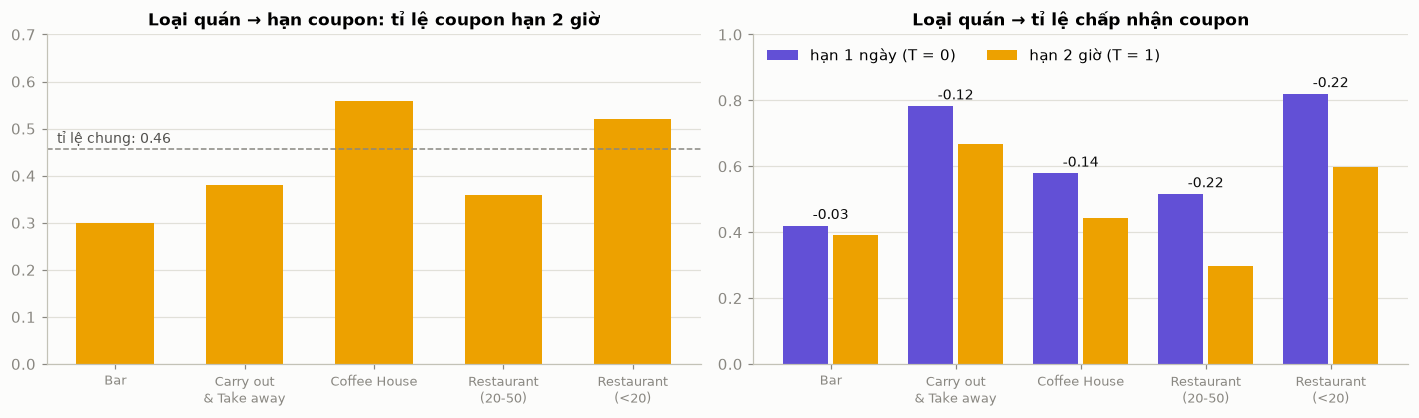

In [11]:
def group_table(data: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    """Chia dữ liệu thành các nhóm theo `by`; trong từng nhóm so sánh coupon 2 giờ với coupon 1 ngày.

    Tham số: data — bảng có cột T, Y và các cột trong `by`; by — danh sách biến dùng để chia nhóm.
    Trả về: bảng mỗi dòng một nhóm, gồm:
        n_1d, n_2h     số dòng hạn 1 ngày, hạn 2 giờ trong nhóm
        p_2h           tỉ lệ coupon hạn 2 giờ trong nhóm
        acc_1d, acc_2h tỉ lệ chấp nhận khi hạn 1 ngày, khi hạn 2 giờ
        diff           acc_2h − acc_1d (hiệu ứng của hạn coupon TRONG nhóm này)
        share          nhóm này chiếm bao nhiêu phần của dữ liệu
    """
    t = data.assign(y=as_int(data["Y"]))
    n = t.groupby(by + ["T"]).size().unstack("T", fill_value=0)       # đếm số dòng theo nhóm × T
    acc = t.groupby(by + ["T"])["y"].mean().unstack("T")              # tỉ lệ chấp nhận theo nhóm × T
    out = pd.DataFrame({"n_1d": n["0"], "n_2h": n["1"]})
    out["p_2h"] = out["n_2h"] / (out["n_1d"] + out["n_2h"])
    out["acc_1d"] = acc["0"]
    out["acc_2h"] = acc["1"]
    out["diff"] = out["acc_2h"] - out["acc_1d"]
    out["share"] = (out["n_1d"] + out["n_2h"]) / len(t)
    return out.reset_index()


def plot_by_coupon(table: pd.DataFrame) -> None:
    """Vẽ bảng theo loại quán thành hai hình cột: (trái) loại quán → hạn coupon, (phải) loại quán → tỉ lệ chấp nhận.

    Tham số: table — kết quả của group_table(data, ["coupon"]).
    """
    labels = [c.replace(" & ", "\n& ").replace("(", "\n(") for c in table["coupon"]]     # xuống dòng cho nhãn dài
    x = np.arange(len(table))
    overall_2h = table["n_2h"].sum() / (table["n_1d"].sum() + table["n_2h"].sum())
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.9))
    # Trái: trong mỗi loại quán, bao nhiêu phần coupon có hạn 2 giờ
    left.bar(x, table["p_2h"], width=0.6, color=ARM_COLOR["1"])
    left.axhline(overall_2h, color=MUTED, linewidth=1, linestyle="--")
    left.text(-0.45, overall_2h + 0.012, f"tỉ lệ chung: {overall_2h:.2f}", color=INK_SOFT, ha="left", fontsize=9)
    left.set_title("Loại quán → hạn coupon: tỉ lệ coupon hạn 2 giờ")
    left.set_ylim(0, 0.7)
    # Phải: tỉ lệ chấp nhận theo loại quán, tách theo hạn; con số trên mỗi cặp cột là chênh lệch (2 giờ − 1 ngày)
    right.bar(x - 0.2, table["acc_1d"], width=0.36, color=ARM_COLOR["0"], label=ARM_LABEL["0"])
    right.bar(x + 0.2, table["acc_2h"], width=0.36, color=ARM_COLOR["1"], label=ARM_LABEL["1"])
    for i, row in table.reset_index(drop=True).iterrows():
        right.text(i, max(row["acc_1d"], row["acc_2h"]) + 0.02, f"{row['diff']:+.2f}", color=INK, ha="center", fontsize=9)
    right.set_title("Loại quán → tỉ lệ chấp nhận coupon")
    right.set_ylim(0, 1.0)
    right.legend(loc="upper left", ncol=2)
    for ax in (left, right):
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=8.5)
        ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(OUT / "confounding_by_coupon.png")


BY_COUPON = group_table(train0, ["coupon"])
plot_by_coupon(BY_COUPON)
BY_COUPON.round(3)

**Kết quả.**

- *Hình trái:* tỉ lệ coupon hạn 2 giờ thay đổi mạnh theo loại quán, từ 30% (Bar) đến 56% (Coffee House). Loại quán có liên hệ thống kê rõ với T.
- *Hình phải:* tỉ lệ chấp nhận cũng thay đổi mạnh theo loại quán. Với hạn 1 ngày: 42% ở Bar, 82% ở Restaurant(<20). Loại quán có liên hệ rõ với Y.
- Loại quán có trước T và liên hệ với cả T lẫn Y, nên là ứng viên **confounder**. Trong DAG, nó tạo ra backdoor path T ← coupon → Y.
- Con số trên mỗi cặp cột là `diff` (2 giờ trừ 1 ngày) **trong cùng một loại quán**. Nó âm ở cả 5 loại quán, từ −0,03 (Bar) đến −0,22 (hai loại nhà hàng).

### 5.3 Điều chỉnh bằng tay

**Ý tưởng.** So sánh 2 giờ với 1 ngày **trong cùng một loại quán**, khi đó loại quán không còn là confounder. Rồi gộp các loại quán lại theo tỉ trọng của chúng (cột `share`):

$$\text{ATE (điều chỉnh theo coupon)} = \sum_{c} P(\text{coupon}=c)\,\big[P(Y{=}1 \mid T{=}1, c) - P(Y{=}1 \mid T{=}0, c)\big]$$

Đây là công thức chuẩn hoá theo nhóm, cũng là dạng đơn giản nhất của **điều chỉnh backdoor**; nó chỉ được đọc là ATE nhân quả khi nhóm biến điều chỉnh đáp ứng các giả định nhận diện (mục 2.3). Ba mô hình B0, H1, H2 làm đúng việc này, chỉ khác là điều chỉnh theo nhiều biến cùng lúc và dùng mô hình để tính xác suất trong từng nhóm.

Thử thêm một bước: điều chỉnh theo cả `coupon` lẫn `destination`. Bảng thứ hai cũng là **kiểm tra overlap**: mỗi nhóm phải có đủ cả coupon 2 giờ lẫn coupon 1 ngày (cột `n_1d`, `n_2h`).

In [12]:
ate_by_coupon = float((BY_COUPON["diff"] * BY_COUPON["share"]).sum())
BY_COUPON_DEST = group_table(train0, ["coupon", "destination"])
ate_by_coupon_dest = float((BY_COUPON_DEST["diff"] * BY_COUPON_DEST["share"]).sum())
smallest_arm = int(BY_COUPON_DEST[["n_1d", "n_2h"]].min().min())
print(f"Hiệu thô:                                   {NAIVE0['diff']:+.4f}")
print(f"Điều chỉnh theo coupon:                     {ate_by_coupon:+.4f}")
print(f"Điều chỉnh theo coupon và destination:      {ate_by_coupon_dest:+.4f}")
print(f"Overlap: {len(BY_COUPON_DEST)} nhóm coupon × destination, nhóm nhỏ nhất của một loại hạn có {smallest_arm} dòng.")
BY_COUPON_DEST.round(3)

Hiệu thô:                                   -0.1368
Điều chỉnh theo coupon:                     -0.1483
Điều chỉnh theo coupon và destination:      -0.1516
Overlap: 14 nhóm coupon × destination, nhóm nhỏ nhất của một loại hạn có 98 dòng.


,coupon,destination,n_1d,n_2h,p_2h,acc_1d,acc_2h,diff,share
0,Bar,Home,250,98,0.282,0.488,0.327,-0.161,0.041
1,Bar,No Urgent Place,507,225,0.307,0.387,0.418,0.031,0.086
2,Carry out & Take away,Home,317,157,0.331,0.811,0.783,-0.027,0.056
3,Carry out & Take away,No Urgent Place,364,299,0.451,0.810,0.686,-0.125,0.078
4,Carry out & Take away,Work,365,186,0.338,0.732,0.538,-0.194,0.065
5,Coffee House,Home,309,347,0.529,0.421,0.297,-0.124,0.077
6,Coffee House,No Urgent Place,681,789,0.537,0.640,0.542,-0.098,0.172
7,Coffee House,Work,236,419,0.640,0.610,0.377,-0.233,0.077
8,Restaurant(20-50),Home,324,133,0.291,0.512,0.241,-0.272,0.054
9,Restaurant(20-50),No Urgent Place,154,135,0.467,0.591,0.422,-0.169,0.034


**Kết quả.**

- Hiệu thô là −0,137. Chuẩn hoá theo loại quán cho −0,148, thêm điểm đến cho −0,152. Hiệu **âm hơn** sau khi điều chỉnh, tức so sánh thô đã đánh giá nhẹ khoảng cách giữa hai loại hạn.
- Overlap **ở mức hai biến này** đạt: cả 14 nhóm loại quán × điểm đến đều có ít nhất 98 dòng cho mỗi loại hạn. Chỉ có 14 nhóm chứ không phải 15 vì nhóm Bar × Work đã bị loại ở mục 3.4. Các mô hình về sau điều chỉnh theo 2–5 biến, nên overlap phải được xem lại ở đó (tỉ lệ dòng TEST rơi vào ô TRAIN trống, mục 15).
- Cột `diff` âm ở 13/14 nhóm; riêng Bar × No Urgent Place hơi dương (+0,031).

Các mô hình ở mục 8–10 sẽ cho ATE từ −0,13 đến −0,15 trên seed này, cùng cỡ với phép tính tay. Đây là một phép kiểm tra chéo hữu ích: mô hình phức tạp không nên cho kết quả khác xa một phép tính đơn giản mà ta hiểu rõ.

### 5.4 Hạn coupon phụ thuộc biến nào?

Khảo sát liên hệ của từng biến với T bằng **kiểm định chi-square**: với từng biến, hỏi "tỉ lệ coupon 2 giờ có khác nhau giữa các mức của biến này không?". Cách đọc: `p-value` nhỏ (dưới 0,05) nghĩa là có liên hệ với T; `biên độ` = chênh lệch lớn nhất của tỉ lệ coupon 2 giờ giữa các mức.

In [13]:
def t_dependence_table(train: pd.DataFrame) -> pd.DataFrame:
    """Với từng biến nền: T (hạn coupon) có liên hệ với biến đó không?

    Tham số: train — tập TRAIN.
    Trả về: bảng mỗi dòng một biến, gồm p-value của kiểm định chi-square và biên độ của P(T = 1) giữa các mức.
    """
    rows = []
    for col in COVARIATES:
        crosstab = pd.crosstab(train[col], train["T"])              # bảng đếm: mức của biến × T
        chi2, p_value, _, _ = st.chi2_contingency(crosstab)
        p_2h = train.assign(t=as_int(train["T"])).groupby(col)["t"].mean()   # tỉ lệ coupon 2 giờ ở từng mức
        rows.append({"biến": col, "tầng": "người trả lời" if col in RESP else "kịch bản", "p-value": p_value,
                     "P(T=1) thấp nhất": p_2h.min(), "P(T=1) cao nhất": p_2h.max(), "biên độ": p_2h.max() - p_2h.min()})
    return pd.DataFrame(rows).sort_values(["tầng", "biên độ"], ascending=[True, False]).reset_index(drop=True)

def format_p_value(p: float) -> str:
    """p-value: rất nhỏ ghi "< 0.001", còn lại ghi 3 chữ số thập phân.

    Tham số: p — p-value.
    Trả về: chuỗi, VD: "< 0.001" hoặc "0.030".
    """
    if p < 0.001:
        return "< 0.001"
    return f"{p:.3f}"


TDEP = t_dependence_table(train0)
TDEP.style.format({"p-value": format_p_value, "P(T=1) thấp nhất": "{:.3f}", "P(T=1) cao nhất": "{:.3f}", "biên độ": "{:.3f}"})

,biến,tầng,p-value,P(T=1) thấp nhất,P(T=1) cao nhất,biên độ
0,coupon,kịch bản,< 0.001,0.299,0.559,0.260
1,weather,kịch bản,< 0.001,0.297,0.534,0.237
2,time_bin,kịch bản,< 0.001,0.354,0.497,0.143
3,passenger,kịch bản,< 0.001,0.420,0.529,0.108
4,dist,kịch bản,< 0.001,0.416,0.511,0.095
5,direction_same,kịch bản,0.001,0.448,0.490,0.042
6,destination,kịch bản,0.012,0.433,0.471,0.038
7,RestaurantLessThan20,người trả lời,0.203,0.443,0.542,0.098
8,CarryAway,người trả lời,0.390,0.443,0.513,0.071
9,CoffeeHouse,người trả lời,0.315,0.447,0.508,0.061


**Kết quả.**

- Cả 7 biến kịch bản đều liên hệ với T (p-value dưới 0,05). Mạnh nhất là loại quán (tỉ lệ coupon 2 giờ chênh nhau tới 0,26 giữa các loại quán), rồi thời tiết (0,24).
- Cả 9 biến của người trả lời, gồm 5 thói quen gốc, đều **không** bị bác bỏ độc lập với T ở mức 0,05 (p-value nhỏ nhất là 0,064, ở `has_children`).
- Biên độ của ba thói quen trông lớn (`RestaurantLessThan20` 0,10; `CarryAway` 0,07; `CoffeeHouse` 0,06) nhưng đến từ mức `missing` rất ít dòng (72 đến 177 dòng TRAIN). Giữa ba mức low / mid / high, tỉ lệ coupon 2 giờ chỉ chênh nhau khoảng 0,02.
- Dữ liệu vì thế **phù hợp** với giả định G1 (hạn coupon được gán theo kịch bản chứ không theo người), và đây là cơ sở của luật 8 ở mục 6. Nhưng phù hợp chưa phải là chứng minh: không bác bỏ được độc lập không có nghĩa là độc lập, và kiểm định chi-square coi các dòng là độc lập trong khi mỗi người trả lời nhiều dòng, nên p-value ở đây chỉ để tham khảo.

<a id="6"></a>
## 6. Ràng buộc DAG

**Mục tiêu.** Viết ra, cho **từng nút**, những nút nào được phép trỏ vào nó (*parents được phép*) và vì sao; mọi mũi tên khác đều bị cấm. Sau đó viết một hàm kiểm tra tự động cho mọi DAG mà thuật toán sinh ra.

Các loại lý do được dùng:

- **Nút gốc:** không biến nào trong bài làm đổi được thời tiết, tuổi hay giới tính.
- **Thứ tự thời gian:** cái có sau không gây ra cái có trước.


In [14]:
# Năm thói quen gốc: tần suất người trả lời đến từng loại quán (mục 3.3)
HABITS: list[str] = ["Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]

# Mỗi luật là một dict: áp cho những nút nào, các nút đó ĐƯỢC PHÉP nhận mũi tên từ đâu, vì sao, và ví dụ cạnh bị cấm.
# Nút nào không có trong "parents" thì bị cấm trỏ vào các nút của luật đó.
RULES: list[dict] = [
    {"luật": 1, "nút": ["weather", "age_bin", "gender"], "parents": [],
     "lý do": "Nút gốc (ngoại sinh): không biến nào trong bài làm đổi được thời tiết, tuổi hay giới tính.",
     "ví dụ cạnh bị cấm": "passenger → weather; has_children → age_bin"},
    {"luật": 2, "nút": ["has_children", "income_bin"], "parents": ["age_bin", "gender", "has_children", "income_bin"],
     "lý do": "Có con và thu nhập có thể phụ thuộc tuổi, giới tính; giữa hai biến này chiều nào cũng có lý nên để thuật toán chọn. "
              "Thói quen đến quán và một tình huống lái xe giả định không làm đổi hoàn cảnh của người trả lời.",
     "ví dụ cạnh bị cấm": "Bar → income_bin; coupon → has_children"},
    {"luật": 3, "nút": ["time_bin", "destination"], "parents": ["weather", "time_bin", "destination", "passenger"],
     "lý do": "Bối cảnh chuyến đi (mấy giờ, đi đâu, chở ai) có trước coupon và có thể phụ thuộc thời tiết. "
              "Coupon và quãng đường tới quán không quyết định ngược lại chuyến đi.",
     "ví dụ cạnh bị cấm": "coupon → time_bin; dist → destination"},
    {"luật": 4, "nút": ["passenger"], "parents": ["weather", "time_bin", "destination", "has_children"],
     "lý do": "Như luật 3, thêm has_children: hành khách là trẻ em (Kid(s)) gần như chỉ xuất hiện ở người có con.",
     "ví dụ cạnh bị cấm": "dist → passenger; gender → passenger"},
    {"luật": 5, "nút": ["coupon"], "parents": ["weather", "time_bin", "destination", "passenger"],
     "lý do": "Coupon hiện ra trong một tình huống đã có sẵn và do bảng hỏi đưa ra, không do người trả lời chọn "
              "và không chọn theo thói quen của người đó.",
     "ví dụ cạnh bị cấm": "Bar → coupon; direction_same → coupon"},
    {"luật": 6, "nút": HABITS, "parents": ["age_bin", "gender", "income_bin", "has_children"] + HABITS,
     "lý do": "Thói quen đến quán là đặc điểm có sẵn của người, có từ trước cuộc khảo sát; nó có thể phụ thuộc tuổi, giới tính, thu nhập, có con. "
              "Giữa 5 thói quen chiều nào cũng có lý nên để thuật toán chọn. Tình huống lái xe và coupon không làm đổi thói quen.",
     "ví dụ cạnh bị cấm": "coupon → CoffeeHouse; weather → Bar"},
    {"luật": 7, "nút": ["dist", "direction_same"], "parents": ["weather", "time_bin", "destination", "coupon", "dist", "direction_same"],
     "lý do": "Quãng đường và hướng tới quán do điểm đến và quán của coupon quyết định; thời tiết và giờ giấc có thể làm đổi thời gian lái xe.",
     "ví dụ cạnh bị cấm": "passenger → dist; Bar → direction_same"},
    {"luật": 8, "nút": ["T"], "parents": SCEN,
     "lý do": "Hạn coupon do bảng hỏi gán theo kịch bản, không theo người trả lời (giả định G1, đã kiểm ở mục 5.4).",
     "ví dụ cạnh bị cấm": "gender → T; CoffeeHouse → T"},
    {"luật": 9, "nút": ["Y"], "parents": COVARIATES + ["T"],
     "lý do": "Câu trả lời đến sau cùng nên mọi biến đều có thể ảnh hưởng đến nó. Y không nằm trong parents của nút nào, nên Y không trỏ đi đâu.",
     "ví dụ cạnh bị cấm": "(không cấm cạnh nào đi vào Y)"},
]
REQUIRED: list[tuple[str, str]] = [("T", "Y")]                       # luật 10: cạnh bắt buộc


def allowed_parents() -> dict[str, list[str]]:
    """Đổi RULES thành dict {nút: các nút được phép trỏ vào nó}.

    Trả về: dict có đủ 18 nút; một nút không bao giờ là parent của chính nó.
    """
    allowed = {}
    for rule in RULES:
        for node in rule["nút"]:
            allowed[node] = [p for p in rule["parents"] if p != node]
    return allowed


def rules_table() -> pd.DataFrame:
    """Lập bảng lý do của bộ luật, mỗi dòng một luật.

    Trả về: bảng gồm số luật, nút áp dụng, parents được phép, số mũi tên bị cấm, ví dụ cạnh bị cấm và lý do.
    """
    rows = []
    for rule in RULES:
        n_banned = 0
        for node in rule["nút"]:                                     # mỗi nút có 17 nút khác; trừ đi số parents được phép
            n_banned += len(NODES) - 1 - len(ALLOWED_PARENTS[node])
        rows.append({"luật": rule["luật"], "áp cho nút": ", ".join(rule["nút"]),
                     "parents được phép": ", ".join(rule["parents"]) if rule["parents"] else "(không có)",
                     "số cạnh bị cấm": n_banned, "ví dụ cạnh bị cấm": rule["ví dụ cạnh bị cấm"], "lý do": rule["lý do"]})
    rows.append({"luật": 10, "áp cho nút": "T, Y", "parents được phép": "bắt buộc có T → Y", "số cạnh bị cấm": 0,
                 "ví dụ cạnh bị cấm": "(DAG thiếu cạnh T → Y)",
                 "lý do": "Câu hỏi của bài là T ảnh hưởng Y bao nhiêu; thiếu cạnh này thì mô hình mặc định hiệu ứng bằng 0."})
    rows.append({"luật": 11, "áp cho nút": "mọi nút", "parents được phép": "không tạo vòng kín", "số cạnh bị cấm": 0,
                 "ví dụ cạnh bị cấm": "time_bin → destination → time_bin", "lý do": "Định nghĩa của DAG."})
    return pd.DataFrame(rows)


ALLOWED_PARENTS: dict[str, list[str]] = allowed_parents()
RULE_OF: dict[str, int] = {node: rule["luật"] for rule in RULES for node in rule["nút"]}       # nút → số của luật quản nút đó
assert sorted(ALLOWED_PARENTS) == sorted(NODES), "mỗi nút phải thuộc đúng một luật"

RULES_TABLE = rules_table()
RULES_TABLE.to_csv(OUT / "rules_table.csv", index=False)
print(f"Tổng số mũi tên bị cấm: {RULES_TABLE['số cạnh bị cấm'].sum()} trên {len(NODES) * (len(NODES) - 1)} mũi tên có thể vẽ giữa {len(NODES)} nút.")
RULES_TABLE.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top"})

Tổng số mũi tên bị cấm: 212 trên 306 mũi tên có thể vẽ giữa 18 nút.


luật,áp cho nút,parents được phép,số cạnh bị cấm,ví dụ cạnh bị cấm,lý do
1,"weather, age_bin, gender",(không có),51,passenger → weather; has_children → age_bin,"Nút gốc (ngoại sinh): không biến nào trong bài làm đổi được thời tiết, tuổi hay giới tính."
2,"has_children, income_bin","age_bin, gender, has_children, income_bin",28,Bar → income_bin; coupon → has_children,"Có con và thu nhập có thể phụ thuộc tuổi, giới tính; giữa hai biến này chiều nào cũng có lý nên để thuật toán chọn. Thói quen đến quán và một tình huống lái xe giả định không làm đổi hoàn cảnh của người trả lời."
3,"time_bin, destination","weather, time_bin, destination, passenger",28,coupon → time_bin; dist → destination,"Bối cảnh chuyến đi (mấy giờ, đi đâu, chở ai) có trước coupon và có thể phụ thuộc thời tiết. Coupon và quãng đường tới quán không quyết định ngược lại chuyến đi."
4,passenger,"weather, time_bin, destination, has_children",13,dist → passenger; gender → passenger,"Như luật 3, thêm has_children: hành khách là trẻ em (Kid(s)) gần như chỉ xuất hiện ở người có con."
5,coupon,"weather, time_bin, destination, passenger",13,Bar → coupon; direction_same → coupon,"Coupon hiện ra trong một tình huống đã có sẵn và do bảng hỏi đưa ra, không do người trả lời chọn và không chọn theo thói quen của người đó."
6,"Bar, CoffeeHouse, CarryAway, RestaurantLessThan20, Restaurant20To50","age_bin, gender, income_bin, has_children, Bar, CoffeeHouse, CarryAway, RestaurantLessThan20, Restaurant20To50",45,coupon → CoffeeHouse; weather → Bar,"Thói quen đến quán là đặc điểm có sẵn của người, có từ trước cuộc khảo sát; nó có thể phụ thuộc tuổi, giới tính, thu nhập, có con. Giữa 5 thói quen chiều nào cũng có lý nên để thuật toán chọn. Tình huống lái xe và coupon không làm đổi thói quen."
7,"dist, direction_same","weather, time_bin, destination, coupon, dist, direction_same",24,passenger → dist; Bar → direction_same,Quãng đường và hướng tới quán do điểm đến và quán của coupon quyết định; thời tiết và giờ giấc có thể làm đổi thời gian lái xe.
8,T,"coupon, destination, time_bin, passenger, weather, dist, direction_same",10,gender → T; CoffeeHouse → T,"Hạn coupon do bảng hỏi gán theo kịch bản, không theo người trả lời (giả định G1, đã kiểm ở mục 5.4)."
9,Y,"Bar, CoffeeHouse, CarryAway, RestaurantLessThan20, Restaurant20To50, age_bin, income_bin, gender, has_children, coupon, destination, time_bin, passenger, weather, dist, direction_same, T",0,(không cấm cạnh nào đi vào Y),"Câu trả lời đến sau cùng nên mọi biến đều có thể ảnh hưởng đến nó. Y không nằm trong parents của nút nào, nên Y không trỏ đi đâu."
10,"T, Y",bắt buộc có T → Y,0,(DAG thiếu cạnh T → Y),Câu hỏi của bài là T ảnh hưởng Y bao nhiêu; thiếu cạnh này thì mô hình mặc định hiệu ứng bằng 0.



Các luật 3 đến 6 dựa vào cách dữ liệu được tạo, nên ô dưới đây kiểm lại bằng số liệu: người trả lời (kể cả thói quen đến quán của họ) có thật sự **không liên hệ** với tình huống và coupon mà bảng hỏi đưa ra không? Thước đo là **Cramér's V**: 0 nghĩa là hai biến độc lập, 1 nghĩa là biết biến này thì biết chắc biến kia.

In [15]:
def cramers_v(data: pd.DataFrame, a: str, b: str) -> float:
    """Độ mạnh liên hệ giữa hai biến phân loại (Cramér's V), tính từ thống kê chi-square.

    Tham số: data — bảng dữ liệu; a, b — tên hai cột.
    Trả về: một số từ 0 (độc lập) đến 1 (biến này quyết định hoàn toàn biến kia).
    """
    crosstab = pd.crosstab(data[a], data[b])                         # bảng đếm: mức của a × mức của b
    chi2 = st.chi2_contingency(crosstab)[0]
    return float(np.sqrt(chi2 / (len(data) * (min(crosstab.shape) - 1))))


def association_table(data: pd.DataFrame, row_vars: list[str], col_vars: list[str]) -> pd.DataFrame:
    """Bảng Cramér's V giữa hai nhóm biến.

    Tham số: data — bảng dữ liệu; row_vars — các biến làm dòng; col_vars — các biến làm cột.
    Trả về: bảng số, ô [r, c] là Cramér's V giữa biến r và biến c.
    """
    table = pd.DataFrame(index=row_vars, columns=col_vars, dtype=float)
    for r in row_vars:
        for c in col_vars:
            table.loc[r, c] = cramers_v(data, r, c)
    return table


print("Cramér's V giữa biến của người trả lời (dòng) và biến kịch bản (cột), trên TRAIN của seed 0:")
display(association_table(train0, RESP, SCEN).round(3))
print("Tỉ lệ từng loại hành khách, tách theo người trả lời có con (1) hay không (0):")
display(pd.crosstab(train0["has_children"], train0["passenger"], normalize="index").round(3))

Cramér's V giữa biến của người trả lời (dòng) và biến kịch bản (cột), trên TRAIN của seed 0:


,coupon,destination,time_bin,passenger,weather,dist,direction_same
Bar,0.016,0.026,0.019,0.057,0.014,0.022,0.020
CoffeeHouse,0.013,0.024,0.015,0.046,0.017,0.009,0.021
CarryAway,0.021,0.028,0.037,0.032,0.048,0.020,0.027
RestaurantLessThan20,0.021,0.036,0.030,0.050,0.034,0.016,0.037
Restaurant20To50,0.015,0.017,0.007,0.038,0.029,0.021,0.006
age_bin,0.017,0.013,0.018,0.084,0.021,0.030,0.016
income_bin,0.017,0.015,0.021,0.078,0.041,0.014,0.012
gender,0.010,0.009,0.006,0.042,0.024,0.007,0.004
has_children,0.028,0.029,0.034,0.364,0.023,0.086,0.027


Tỉ lệ từng loại hành khách, tách theo người trả lời có con (1) hay không (0):


passenger,Alone,Friend(s),Kid(s),Partner
has_children,,,,
0,0.588,0.284,0.002,0.125
1,0.527,0.238,0.196,0.039


**Cách đọc kết quả.**

- Hầu hết các ô dưới 0,06: đặc điểm của người trả lời gần như không liên hệ với tình huống được đưa ra.
- **Cả 5 thói quen gốc gần như độc lập với `coupon`** (0,013 đến 0,021).
- Một ngoại lệ rõ ràng, và bộ luật dành cho nó một cạnh được phép: `has_children` với `passenger` (0,364). Hành khách Kid(s) chiếm 19,6% số dòng của người có con nhưng chỉ 0,2% ở người không có con, nên luật 4 cho phép `has_children → passenger`.
- Vài ô ở mức 0,08–0,09 (`age_bin` và `income_bin` với `passenger`, `has_children` với `dist`) nhỏ hơn hẳn ngoại lệ trên. Bộ luật không cho chúng cạnh trực tiếp, nhưng chúng vẫn có đường gián tiếp đi qua `has_children → passenger`.
- Như ở mục 5.4, chi-square coi các dòng là độc lập trong khi mỗi người trả lời nhiều dòng, nên các con số này chỉ để tham khảo.

Từ `RULES` suy ra ba thứ dùng cho phần còn lại của bài: danh sách cạnh cấm `FORBIDDEN` (cho `pgmpy`), ma trận `MASK` (cho neural network) và hàm kiểm tra `check_dag`.

In [16]:
def forbidden_edges() -> list[tuple[str, str]]:
    """Liệt kê mọi mũi tên bị cấm: u → v bị cấm khi u không nằm trong parents được phép của v (luật 1–9).

    Trả về: danh sách các cặp (u, v) với nghĩa "cấm mũi tên u → v".
    """
    banned = []
    for u in NODES:
        for v in NODES:
            if u != v and u not in ALLOWED_PARENTS[v]:
                banned.append((u, v))
    return banned


FORBIDDEN: list[tuple[str, str]] = forbidden_edges()

# Thứ tự thời gian suy ra từ bộ luật: 8 lớp. Mũi tên được phép chỉ đi từ lớp trước sang lớp sau hoặc nằm trong cùng một lớp.
LAYERS: list[list[str]] = [
    ["age_bin", "gender", "weather"],                # lớp 0: nút gốc
    ["income_bin", "has_children"],                  # lớp 1: hoàn cảnh của người trả lời
    HABITS,                                          # lớp 2: thói quen đến quán của người trả lời
    ["passenger", "destination", "time_bin"],        # lớp 3: bối cảnh chuyến đi do bảng hỏi đưa ra
    ["coupon"],                                      # lớp 4: coupon hiện ra
    ["dist", "direction_same"],                      # lớp 5: quãng đường và hướng tới quán của coupon
    ["T"],                                           # lớp 6: hạn coupon
    ["Y"],                                           # lớp 7: câu trả lời
]
LAYER_OF: dict[str, int] = {n: k for k, layer in enumerate(LAYERS) for n in layer}       # nút → số thứ tự lớp (0..7)
assert sorted(LAYER_OF) == sorted(NODES), "mỗi nút phải thuộc đúng một lớp"
for v in NODES:                                                              # kiểm tra: không luật nào cho phép mũi tên đi ngược lớp
    for p in ALLOWED_PARENTS[v]:
        assert LAYER_OF[p] <= LAYER_OF[v], f"{p} → {v} đi ngược lớp"

# ExpertKnowledge là cách pgmpy nhận "hiểu biết chuyên gia": cạnh cấm, cạnh bắt buộc, thứ tự thời gian
EXPERT = ExpertKnowledge(forbidden_edges=FORBIDDEN, required_edges=REQUIRED, temporal_order=LAYERS)


def allowed_mask() -> np.ndarray:
    """Tạo mask cho H2: ma trận 18 × 18 gồm 0 và 1.

    Quy ước: MASK[i, j] = 1 nếu mũi tên NODES[i] → NODES[j] được phép, = 0 nếu bị cấm (đường chéo luôn = 0).
    Trả về: mảng numpy 18 × 18.
    """
    mask = np.ones((len(NODES), len(NODES)), dtype=np.float32)
    np.fill_diagonal(mask, 0.0)
    position = {n: i for i, n in enumerate(NODES)}
    for u, v in FORBIDDEN:
        mask[position[u], position[v]] = 0.0
    return mask


MASK = allowed_mask()


def check_dag(edges: list[tuple[str, str]]) -> list[str]:
    """Kiểm tra một DAG theo 11 luật ở trên.

    Tham số: edges — danh sách mũi tên (u, v).
    Trả về: danh sách câu mô tả lỗi; danh sách rỗng nghĩa là DAG hợp lệ.
    """
    graph = nx.DiGraph(edges)
    graph.add_nodes_from(NODES)
    problems = []
    for u, v in graph.edges():
        if u not in ALLOWED_PARENTS[v]:                    # luật 1–9: u không được phép trỏ vào v
            problems.append(f"luật {RULE_OF[v]}: {u} → {v} bị cấm ({v} không được nhận mũi tên từ {u})")
    for u, v in REQUIRED:
        if not graph.has_edge(u, v):
            problems.append(f"luật 10: thiếu cạnh bắt buộc {u} → {v}")
    if not nx.is_directed_acyclic_graph(graph):
        problems.append("luật 11: đồ thị có vòng kín")
    return problems


print(f"Có {len(NODES) * (len(NODES) - 1)} mũi tên có thể vẽ giữa {len(NODES)} nút; {len(FORBIDDEN)} bị cấm, còn {int(MASK.sum())} được phép.")
print("Thử một DAG tốt :", check_dag([("weather", "coupon"), ("age_bin", "Bar"), ("coupon", "T"), ("T", "Y"), ("coupon", "Y"), ("CoffeeHouse", "Y")]))
print("Thử một DAG lỗi :")
for problem in check_dag([("passenger", "weather"), ("coupon", "CoffeeHouse"), ("Bar", "coupon"), ("gender", "T"), ("Y", "dist")]):
    print("  -", problem)

Có 306 mũi tên có thể vẽ giữa 18 nút; 212 bị cấm, còn 94 được phép.
Thử một DAG tốt : []
Thử một DAG lỗi :
  - luật 1: passenger → weather bị cấm (weather không được nhận mũi tên từ passenger)
  - luật 6: coupon → CoffeeHouse bị cấm (CoffeeHouse không được nhận mũi tên từ coupon)
  - luật 5: Bar → coupon bị cấm (coupon không được nhận mũi tên từ Bar)
  - luật 8: gender → T bị cấm (T không được nhận mũi tên từ gender)
  - luật 7: Y → dist bị cấm (dist không được nhận mũi tên từ Y)
  - luật 10: thiếu cạnh bắt buộc T → Y


**Kết quả.** DAG tốt trả về danh sách rỗng `[]`. DAG lỗi trả về từng câu mô tả lỗi, kèm số của luật bị vi phạm. Từ đây về sau, mọi DAG phải qua `check_dag` trước khi được dùng.

Hàm vẽ dưới đây đặt các biến của **người trả lời ở nửa trái** và các biến **kịch bản ở nửa phải**; trong mỗi nửa, lớp trước của `LAYERS` nằm trên, lớp sau nằm dưới, và Y nằm dưới cùng. Màu của nút vẫn theo 4 tầng ở mục 1.1. Mũi tên đi vào T hoặc Y được vẽ đậm vì chúng quyết định adjustment set; T → Y tô đỏ; các mũi tên còn lại vẽ nhạt.

In [17]:
# Nhãn hiển thị trên hình: tên biến dài được ngắt dòng cho vừa trong nút
NODE_LABEL: dict[str, str] = {"CoffeeHouse": "Coffee\nHouse", "CarryAway": "Carry\nAway",
                              "RestaurantLessThan20": "Restaurant\n<20", "Restaurant20To50": "Restaurant\n20–50"}

# Toạ độ (x, y) của từng nút: người trả lời ở nửa trái, kịch bản ở nửa phải, Y ở dưới cùng.
# Trong mỗi nửa, lớp trước của LAYERS nằm trên, lớp sau nằm dưới.
NODE_POS: dict[str, tuple[float, float]] = {
    "age_bin": (1.6, 7.2), "gender": (4.2, 7.2),                                             # nút gốc của người
    "income_bin": (0.9, 5.6), "has_children": (4.9, 5.6),                                    # hoàn cảnh của người
    "Bar": (0.0, 3.7), "CoffeeHouse": (1.45, 3.0), "CarryAway": (2.9, 3.7),                  # năm thói quen
    "RestaurantLessThan20": (4.35, 3.0), "Restaurant20To50": (5.8, 3.7),
    "weather": (10.2, 7.2),                                                                  # nút gốc của kịch bản
    "passenger": (8.3, 5.6), "destination": (11.6, 5.0), "time_bin": (13.3, 5.9),            # bối cảnh chuyến đi
    "coupon": (8.6, 3.5), "dist": (10.6, 2.6), "direction_same": (13.0, 2.7),                # coupon và đường tới quán
    "T": (11.2, 0.9), "Y": (6.6, 0.0),
}


def draw_dag(edges: list[tuple[str, str]], title: str) -> None:
    """Vẽ DAG theo toạ độ NODE_POS, tô màu theo 4 tầng; mũi tên vào T hoặc Y tô đậm, T → Y tô đỏ.

    Tham số: edges — danh sách mũi tên; title — tiêu đề hình.
    """
    graph = nx.DiGraph(edges)
    graph.add_nodes_from(NODES)
    tier_colors = ["#cfe2f3", "#fff2cc", "#f9cb9c", "#b6d7a8"]      # xanh: người; vàng: kịch bản; cam: T; lục: Y
    _, ax = plt.subplots(figsize=(15, 10))
    nx.draw_networkx_nodes(graph, NODE_POS, node_color=[tier_colors[TIER_OF[n]] for n in graph.nodes], node_size=2700, edgecolors="#444", ax=ax)
    nx.draw_networkx_labels(graph, NODE_POS, labels={n: NODE_LABEL.get(n, n.replace("_", "\n")) for n in graph.nodes}, font_size=8.5, ax=ax)
    # Mũi tên vào T hoặc Y là phần cần đọc (quyết định tập điều chỉnh) nên vẽ đậm; các mũi tên còn lại vẽ nhạt
    key_edges = [e for e in graph.edges if e[1] in ("T", "Y") and e != ("T", "Y")]
    other_edges = [e for e in graph.edges if e[1] not in ("T", "Y")]
    nx.draw_networkx_edges(graph, NODE_POS, edgelist=other_edges, arrowsize=11, node_size=2700, width=0.9, edge_color="#a09e98",
                           connectionstyle="arc3,rad=0.12", ax=ax)
    nx.draw_networkx_edges(graph, NODE_POS, edgelist=key_edges, arrowsize=16, node_size=2700, width=1.6, edge_color="#333",
                           connectionstyle="arc3,rad=0.12", ax=ax)
    if graph.has_edge("T", "Y"):
        nx.draw_networkx_edges(graph, NODE_POS, edgelist=[("T", "Y")], arrowsize=20, node_size=2700, width=3, edge_color="#e34948", ax=ax)
    ax.set_title(title)
    ax.axis("off")

<a id="7"></a>
## 7. Khảo sát thuật toán

**Mục tiêu.** Xem trong các thư viện phổ biến có những thuật toán nào cho hai việc: </br>
(1) tìm DAG (*học cấu trúc*) </br>
(2) điền CPD (*học tham số*); rồi chọn cái hợp với bài.

### 7.1 Học cấu trúc (tìm DAG)

| Nhóm | Thuật toán | Thư viện | Ý tưởng bằng lời thường | Nhận ràng buộc? | Dùng trong bài |
|---|---|---|---|---|---|
| Dựa trên điểm | Hill Climbing, Tabu | `pgmpy.HillClimbSearch`; bnlearn (R) `hc`, `tabu` | Bắt đầu từ đồ thị rỗng; mỗi bước thử thêm, bớt hoặc đảo một mũi tên, giữ thay đổi làm **điểm** tăng nhiều nhất; dừng khi hết cải thiện | có: `ExpertKnowledge` | **B0** (thử 3 hàm điểm) |
| Dựa trên điểm | GES | `pgmpy.GES`, causal-learn | Thêm cạnh tham lam rồi bớt cạnh tham lam | chưa nhận trong pgmpy 1.1 | không |
| Dựa trên kiểm định | PC | `pgmpy.PC`, causal-learn, bnlearn `pc.stable` | Bắt đầu từ đồ thị đầy đủ; xoá cạnh giữa hai biến nếu kiểm định thấy chúng độc lập (có điều kiện) | có | chạy thử ở mục 8.2 |
| Lai | MMHC | `pgmpy.MmhcEstimator`, bnlearn `mmhc` | Dùng kiểm định để khoanh vùng, rồi Hill Climbing trong vùng đó | hạn chế | không |
| Cây | Chow-Liu, TAN | `pgmpy.TreeSearch` | Chỉ cho phép đồ thị dạng cây | không | không (quá đơn giản) |
| Neural network | NOTEARS (tuyến tính, MLP), DAG-GNN, GOLEM, DAGMA | mã nguồn `xunzheng/notears`, `fishmoon1234/DAG-GNN`; hoặc tự cài bằng PyTorch | Biến bài toán "thử từng mũi tên" thành bài toán tối ưu liên tục: học trọng số, kèm một hình phạt bắt đồ thị không có vòng | qua mask | **H2** (NOTEARS-MLP) |

**Hàm điểm** DAG khớp dữ liệu thì điểm cao, nhưng DAG nhiều mũi tên bị trừ điểm.
- BIC -> DAG thưa
- BDeu và K2 -> DAG dày

=> để VALIDATION quyết định.

### 7.2 Học tham số (điền CPD)

| Phương pháp | Thư viện | Công thức cho một ô | Nhận xét |
|---|---|---|---|
| Maximum Likelihood (MLE) | `pgmpy.MaximumLikelihoodEstimator`; bnlearn `bn.fit(method="mle")` | số dòng có Y = 1 trong ô ÷ số dòng của ô | Ô có 3 dòng mà cả 3 đều nhận coupon thì cho xác suất 100%: quá tự tin. Ô không có dòng nào thì không tính được |
| Bayes có làm trơn: BDeu, K2, Dirichlet | `pgmpy.BayesianEstimator`; bnlearn `method="bayes"` | (số dòng Y = 1 + α) ÷ (số dòng của ô + 2α) | Cộng thêm α "dòng ảo" cho mỗi kết quả vào mỗi ô trước khi chia. Ô nhiều dữ liệu gần như không đổi; ô trống nhận xác suất 50% thay vì không tính được. **Dùng cho B0 và H2** |
| EM | `pgmpy.ExpectationMaximization` | lặp: đoán giá trị thiếu → ước lượng lại | Chỉ cần khi dữ liệu có ô trống; bài này không còn ô trống |
| Neural network | PyTorch, Keras | mạng nhận giá trị của parents, trả ra xác suất | Các ô "na ná nhau" chia sẻ thông tin cho nhau. **Dùng cho H1** |

Với BDeu, α = ESS ÷ (số mức của nút × số tổ hợp giá trị của parents). ESS (*equivalent sample size*) là tổng số dòng ảo chia đều cho cả bảng; ESS=5
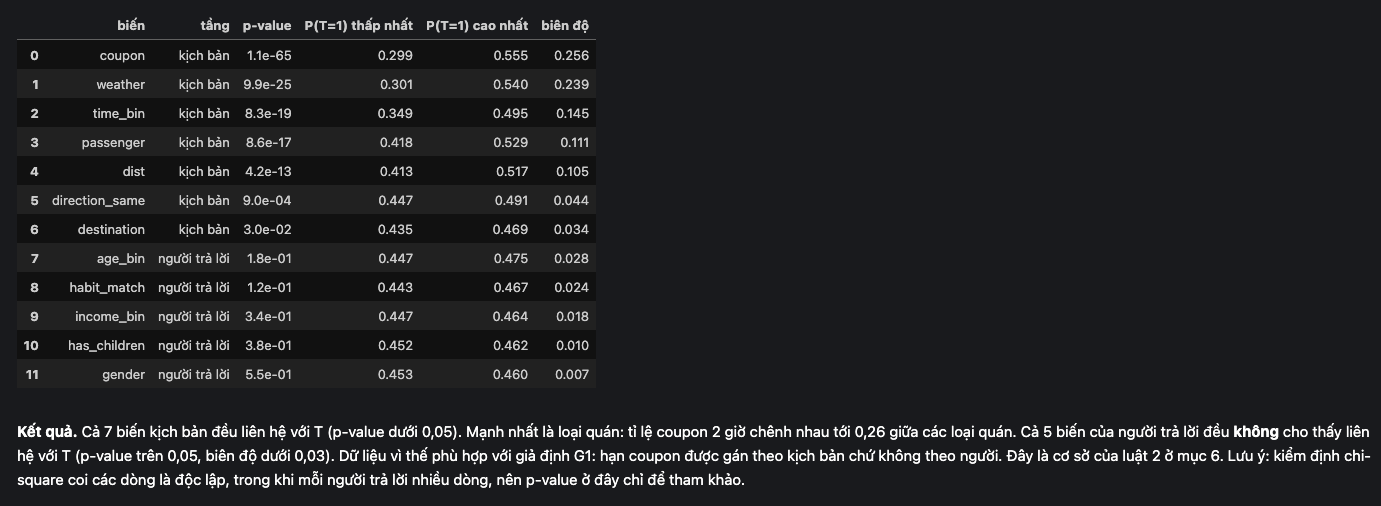

In [18]:
def fit_bn(edges: list[tuple[str, str]], data: pd.DataFrame) -> DiscreteBayesianNetwork:
    """Tạo mạng Bayes từ một DAG và điền mọi bảng xác suất bằng BDeu.

    Tham số: edges — các mũi tên của DAG; data — dữ liệu để đếm (luôn là TRAIN).
    Trả về: mạng Bayes đã có đủ bảng xác suất cho 18 nút, đã qua check_model() của pgmpy.
    """
    bn = DiscreteBayesianNetwork(edges)
    bn.add_nodes_from(NODES)                                  # nút không có mũi tên nào vẫn phải nằm trong mạng
    estimator = BayesianEstimator(bn, data[NODES], state_names=STATES)
    bn.add_cpds(*estimator.get_parameters(prior_type="BDeu", equivalent_sample_size=CFG.ess))
    assert bn.check_model()                                   # pgmpy tự kiểm: mỗi cột của mỗi bảng cộng lại bằng 1
    return bn


def cpd_to_frame(cpd: TabularCPD) -> pd.DataFrame:
    """Đổi một bảng xác suất của pgmpy thành bảng pandas dễ đọc.

    Tham số: cpd — bảng xác suất của một nút.
    Trả về: bảng mỗi dòng là một tổ hợp (giá trị của nút, giá trị của các cha), cột p là xác suất.
    """
    cols = list(cpd.variables)                                # nút đứng đầu, sau đó là các cha
    combos = list(itertools.product(*[cpd.state_names[v] for v in cols]))
    out = pd.DataFrame(combos, columns=cols)
    out["p"] = np.asarray(cpd.values, dtype=float).reshape(-1)
    return out


def cpd_to_y_table(cpd: TabularCPD) -> pd.DataFrame:
    """Rút gọn bảng xác suất của Y: chỉ giữ dòng Y = 1 (vì P(Y = 0) = 1 − P(Y = 1)).

    Tham số: cpd — bảng xác suất của nút Y.
    Trả về: "bảng Y": mỗi dòng là một tổ hợp giá trị của các cha của Y, cột p1 = xác suất chấp nhận coupon.
    """
    frame = cpd_to_frame(cpd)
    frame = frame[frame["Y"] == "1"].drop(columns="Y").rename(columns={"p": "p1"})
    return frame.reset_index(drop=True)


def y_table_of(bn: DiscreteBayesianNetwork) -> pd.DataFrame:
    """Lấy "bảng Y" = P(Y = 1 | cha của Y) của một mạng Bayes đã fit.

    Tham số: bn — mạng đã fit.
    Trả về: bảng gồm các cột cha của Y và cột p1.
    """
    return cpd_to_y_table(bn.get_cpds("Y"))


def cpd_by_hand(data: pd.DataFrame, parents: list[str]) -> pd.DataFrame:
    """Tự tính bảng P(Y = 1 | parents) bằng phép đếm, theo hai cách MLE và BDeu.

    Tham số: data — dữ liệu để đếm; parents — danh sách cha của Y.
    Trả về: bảng mỗi dòng là một ô (một tổ hợp giá trị của cha): n = số dòng, n1 = số dòng Y = 1, mle, bdeu.
    """
    cells = pd.DataFrame(list(itertools.product(*[STATES[p] for p in parents])), columns=parents)   # mọi ô có thể có
    counts = data.assign(y=as_int(data["Y"])).groupby(parents)["y"].agg(n="size", n1="sum").reset_index()
    out = cells.merge(counts, on=parents, how="left").fillna({"n": 0, "n1": 0})
    alpha = CFG.ess / (2 * len(cells))                        # số dòng ảo mỗi ô = ESS ÷ (2 mức của Y × số ô)
    out["mle"] = out["n1"] / out["n"]                         # ô trống → 0 ÷ 0 → NaN (không tính được)
    out["bdeu"] = (out["n1"] + alpha) / (out["n"] + 2 * alpha)
    return out


# Ví dụ 1: Y chỉ có 2 cha → 10 ô, ô nào cũng nhiều dữ liệu → MLE và BDeu gần như trùng nhau
HAND_SMALL = cpd_by_hand(train0, ["T", "coupon"])
bn_small = fit_bn([("T", "Y"), ("coupon", "Y")], train0)
check = HAND_SMALL.merge(y_table_of(bn_small), on=["T", "coupon"])
assert np.allclose(check["bdeu"], check["p1"]), "tính tay khác pgmpy"
print("Tính tay BDeu trùng khớp với pgmpy trên cả 10 ô.")
display(HAND_SMALL.round(4))

# Ví dụ 2: Y có 5 cha → 270 ô. Bảng hỏi không dùng mọi tổ hợp kịch bản, nên rất nhiều ô KHÔNG có dòng nào
HAND_BIG = cpd_by_hand(train0, ["T", "coupon", "destination", "time_bin", "weather"])
print(f"Với 5 cha: {len(HAND_BIG)} ô, trong đó {int((HAND_BIG['n'] == 0).sum())} ô trống và "
      f"{int(((HAND_BIG['n'] > 0) & (HAND_BIG['n'] < 20)).sum())} ô có dưới 20 dòng. Ba ô trống và năm ô ít dữ liệu nhất:")
pd.concat([HAND_BIG[HAND_BIG["n"] == 0].head(3), HAND_BIG[HAND_BIG["n"] > 0].sort_values("n").head(5)]).round(3)

Tính tay BDeu trùng khớp với pgmpy trên cả 10 ô.


,T,coupon,n,n1,mle,bdeu
0,0,Bar,757,318,0.4201,0.4201
1,0,Carry out & Take away,1046,819,0.7830,0.7828
2,0,Coffee House,1226,710,0.5791,0.5791
3,0,Restaurant(20-50),668,345,0.5165,0.5165
4,0,Restaurant(<20),935,767,0.8203,0.8201
5,1,Bar,323,126,0.3901,0.3903
6,1,Carry out & Take away,642,428,0.6667,0.6665
7,1,Coffee House,1555,689,0.4431,0.4431
8,1,Restaurant(20-50),373,111,0.2976,0.2979
9,1,Restaurant(<20),1015,608,0.5990,0.5990


Với 5 cha: 270 ô, trong đó 189 ô trống và 7 ô có dưới 20 dòng. Ba ô trống và năm ô ít dữ liệu nhất:


,T,coupon,destination,time_bin,weather,n,n1,mle,bdeu
0,0,Bar,Home,afternoon,Rainy,0.0,0.0,NaN,0.500
1,0,Bar,Home,afternoon,Snowy,0.0,0.0,NaN,0.500
2,0,Bar,Home,afternoon,Sunny,0.0,0.0,NaN,0.500
269,1,Restaurant(<20),Work,morning,Sunny,3.0,1.0,0.333,0.334
39,0,Carry out & Take away,No Urgent Place,evening,Rainy,8.0,7.0,0.875,0.874
255,1,Restaurant(<20),No Urgent Place,evening,Rainy,11.0,8.0,0.727,0.727
105,0,Restaurant(20-50),Work,morning,Rainy,13.0,5.0,0.385,0.385
252,1,Restaurant(<20),No Urgent Place,afternoon,Rainy,16.0,7.0,0.438,0.438


**Cách đọc kết quả.**

- *Bảng 10 ô (Y theo T và `coupon`):* `mle` và `bdeu` chỉ khác nhau ở chữ số thứ tư. Khi dữ liệu nhiều, làm trơn gần như không có tác dụng.
- *Bảng 270 ô (5 parents):* 189 ô không có dòng TRAIN nào và 7 ô có dưới 20 dòng. Ở ô trống, MLE là `NaN` (chia 0 cho 0) còn BDeu trả về 0,5. Con số 0,5 là **quy ước làm trơn**, không phải bằng chứng quan sát. Ở ô ít dữ liệu, hai cách vẫn gần nhau vì ESS = 5 là mức làm trơn rất nhẹ.
- *Bài học:* cho Y càng nhiều parents thì bảng càng nhiều ô, mỗi ô càng ít dữ liệu. Điều này quan trọng hơn ở bản 18 biến: thuật toán có nhiều ứng viên parents hơn, và mục 10 sẽ cho thấy H2 trả giá khi cho Y một bảng to hơn của B0. Đây cũng là lý do H1 thử một neural network: mạng học quy luật chung nên đoán được cho cả những ô chưa từng thấy (mục 9).

<a id="8"></a>
## 8. B0: DAG truyền thống

**Mục tiêu.** Xây mô hình gốc B0 và đi qua **toàn bộ** quy trình một lần, thật chậm, trên seed 0. H1 và H2 về sau dùng lại đúng các bước này.

| Bước | Việc | Câu hỏi được trả lời |
|---|---|---|
| 8.1 | Hill Climbing đề xuất vài DAG, VALIDATION chọn một | sơ đồ nhân quả trông thế nào? |
| 8.2 | Điền CPD | trong từng hoàn cảnh, xác suất chấp nhận coupon là bao nhiêu? |
| 8.3 | Hỏi DoWhy | với sơ đồ này, có tính được hiệu ứng nhân quả không, và phải điều chỉnh theo biến nào? |
| 8.4 | Dự đoán Y trên TEST | mô hình đoán giỏi đến đâu? (Bảng A) |
| 8.5 | Intervention do(T) | đổi hạn coupon thì tỉ lệ chấp nhận đổi bao nhiêu? (Bảng B) |

### 8.1 Học DAG

**Ý tưởng.** Hill Climbing giống như leo đồi trong sương mù: đứng ở một DAG, thử mọi thay đổi nhỏ (thêm, bớt, đảo một mũi tên), bước sang DAG có **điểm** cao nhất, lặp lại đến khi không còn bước nào đi lên. Ràng buộc ở mục 6 được truyền vào qua `expert_knowledge`, nên thuật toán không bao giờ thử các mũi tên bị cấm.

Ta chưa biết hàm điểm nào và giới hạn số parents nào hợp với dữ liệu, nên cho chạy 6 cấu hình (3 hàm điểm × 2 giới hạn số parents) và để **VALIDATION** chọn:

1. tiêu chí chính: **log-loss của Y** trên VALIDATION (DAG nào cho Y parent set dự đoán Y tốt nhất);
2. nếu hoà: **log-likelihood của cả mạng** trên VALIDATION.


In [19]:
def log_likelihood(bn: DiscreteBayesianNetwork, data: pd.DataFrame) -> float:
    """Độ khớp của CẢ mạng với dữ liệu: trung bình mỗi dòng của log(xác suất mạng gán cho dòng đó).

    Tham số: bn — mạng đã fit; data — dữ liệu để chấm.
    Trả về: một số âm; càng gần 0 thì mạng mô tả dữ liệu càng tốt.
    """
    total = 0.0
    for node in NODES:                                     # xác suất của một dòng = tích xác suất của từng nút → log thì thành tổng
        frame = cpd_to_frame(bn.get_cpds(node))
        cols = [c for c in frame.columns if c != "p"]      # nút đó và các cha của nó
        p = data[cols].merge(frame, on=cols, how="left")["p"].to_numpy()     # tra bảng xác suất cho từng dòng
        total += np.log(np.clip(p, 1e-12, None)).sum()
    return float(total / len(data))


def predict_y(y_table: pd.DataFrame, data: pd.DataFrame) -> np.ndarray:
    """Dự đoán P(Y = 1) cho từng dòng bằng cách TRA "bảng Y".

    Tham số: y_table — bảng gồm các cột cha của Y và cột p1; data — bảng có đủ các cột cha của Y.
    Trả về: mảng xác suất, mỗi dòng của data một số.
    """
    parents = [c for c in y_table.columns if c != "p1"]
    merged = data[parents].merge(y_table, on=parents, how="left")       # ghép theo giá trị của các cha
    assert merged["p1"].notna().all(), "có tổ hợp giá trị của cha không có trong bảng"
    return merged["p1"].to_numpy()


def hc_candidates(train: pd.DataFrame) -> dict[str, list[tuple[str, str]]]:
    """Chạy Hill Climbing với từng cặp (hàm điểm, số cha tối đa) trong Config.

    Tham số: train — tập TRAIN.
    Trả về: dict {tên cấu hình: danh sách mũi tên của DAG tìm được}.
    """
    candidates = {}
    for score in CFG.b0_scores:
        for max_parents in CFG.b0_max_indegree:
            dag = HillClimbSearch(train[NODES]).estimate(scoring_method=score, max_indegree=max_parents,
                                                         expert_knowledge=EXPERT, show_progress=False)
            candidates[f"HC {score}, tối đa {max_parents} cha"] = sorted(dag.edges())
    return candidates


def pc_candidate(train: pd.DataFrame) -> list[tuple[str, str]]:
    """Chạy thuật toán PC (dựa trên kiểm định độc lập) với cùng bộ ràng buộc, để so sánh với Hill Climbing.

    Tham số: train — tập TRAIN.
    Trả về: danh sách mũi tên; T → Y được thêm vào nếu PC không tự tìm ra (luật 10).
    """
    dag = PC(train[NODES]).estimate(ci_test="chi_square", return_type="dag", max_cond_vars=2, significance_level=0.01, expert_knowledge=EXPERT,
                                    enforce_expert_knowledge=True, show_progress=False, n_jobs=1)
    edges = set(dag.edges())
    edges.add(("T", "Y"))
    return sorted(edges)


def score_candidates(candidates: dict[str, list[tuple[str, str]]], train: pd.DataFrame, val: pd.DataFrame) -> pd.DataFrame:
    """Chấm từng DAG ứng viên trên VALIDATION rồi xếp hạng (dùng chung cho B0 và H2).

    Tham số: candidates — dict {tên: danh sách mũi tên}; train — để điền bảng xác suất; val — để chấm.
    Trả về: bảng xếp hạng; DÒNG ĐẦU là DAG được chọn.
            Thứ tự ưu tiên: DAG hợp lệ → log-loss của Y thấp nhất → log-likelihood cả mạng cao nhất.
    """
    y_val = as_int(val["Y"])
    rows = []
    for name, edges in candidates.items():
        bn = fit_bn(edges, train)
        rows.append({"ứng viên": name, "hợp lệ": len(check_dag(edges)) == 0, "số cạnh": len(edges),
                     "cha của Y": ", ".join(sorted(bn.get_parents("Y"))), "cha của T": ", ".join(sorted(bn.get_parents("T"))),
                     "val log-loss Y": log_loss(y_val, predict_y(y_table_of(bn), val)), "val LL cả mạng": log_likelihood(bn, val)})
    ranking = pd.DataFrame(rows)
    ranking["key"] = ranking["val log-loss Y"].round(6)          # làm tròn để hai DAG có cùng bộ cha của Y được coi là hoà
    ranking = ranking.sort_values(["hợp lệ", "key", "val LL cả mạng"], ascending=[False, True, False], kind="stable")
    return ranking.drop(columns="key").reset_index(drop=True)


start = time.time()
CAND0 = hc_candidates(train0)
t_hc = time.time() - start
start = time.time()
CAND0_WITH_PC = dict(CAND0)
CAND0_WITH_PC["PC chi-square, mức 0,01"] = pc_candidate(train0)
t_pc = time.time() - start
RANK0 = score_candidates(CAND0_WITH_PC, train0, val0)
print(f"Thời gian: 6 lần Hill Climbing {t_hc:.1f} giây; 1 lần PC {t_pc:.1f} giây.")
with pd.option_context("display.max_colwidth", 90):
    display(RANK0.round(4))

Thời gian: 6 lần Hill Climbing 3.6 giây; 1 lần PC 1.4 giây.


,ứng viên,hợp lệ,số cạnh,cha của Y,cha của T,val log-loss Y,val LL cả mạng
0,"HC k2, tối đa 6 cha",True,62,"CoffeeHouse, T, coupon, destination, direction_same","coupon, destination, dist, passenger, time_bin, weather",0.5983,-20.0296
1,"HC k2, tối đa 4 cha",True,51,"CoffeeHouse, T, coupon, destination","coupon, destination, dist, weather",0.6015,-18.1553
2,"HC bdeu, tối đa 4 cha",True,50,"CoffeeHouse, T, coupon","coupon, destination, dist, weather",0.6195,-17.4865
3,"HC bic-d, tối đa 4 cha",True,48,"CoffeeHouse, T, coupon","coupon, destination, dist, weather",0.6195,-17.5469
4,"HC bic-d, tối đa 6 cha",True,48,"CoffeeHouse, T, coupon","coupon, destination, dist, weather",0.6195,-17.5469
5,"HC bdeu, tối đa 6 cha",True,60,"CoffeeHouse, T, coupon","coupon, destination, dist, passenger, time_bin, weather",0.6195,-20.0559
6,"PC chi-square, mức 0,01",True,16,T,,0.6724,-16.2454


**Kết quả.** Mỗi dòng là một DAG ứng viên, dòng đầu là DAG tốt nhất theo VALIDATION. Nhìn cột `cha của Y`: các hàm điểm khác nhau cho Y số parents khác nhau, và điều đó quyết định `val log-loss Y`. PC được chạy một lần ở đây để so sánh giữa hai họ thuật toán. Trong 5 lần chạy chính (mục 11) chỉ dùng 6 cấu hình Hill Climbing.

**Kết quả ở seed 0.** VALIDATION chọn Hill Climbing với hàm điểm K2, tối đa 6 parents: 62 cạnh, log-loss của Y trên VALIDATION là 0,598. Y có 4 parents ngoài T: `coupon`, `destination`, `direction_same` và `CoffeeHouse`. <br/>
Trong 5 thói quen gốc, `CoffeeHouse` là thói quen **duy nhất** được nối vào Y, ở cả 6 ứng viên Hill Climbing. PC chỉ giữ 16 cạnh và chỉ cho Y một parent là T nên có log-loss kém nhất (0,672).

Mỗi mô hình sẽ được gói trong một Class `Model`. Điểm đáng nhớ: sau khi học xong, **mọi phép tính về Y chỉ cần `y_table`**, tức bảng P(Y = 1 | parents của Y).


DAG được chọn: HC k2, tối đa 6 cha | 62 cạnh | lỗi ràng buộc: []
Cha của Y: CoffeeHouse, T, coupon, destination, direction_same
Cha của T: coupon, destination, dist, passenger, time_bin, weather


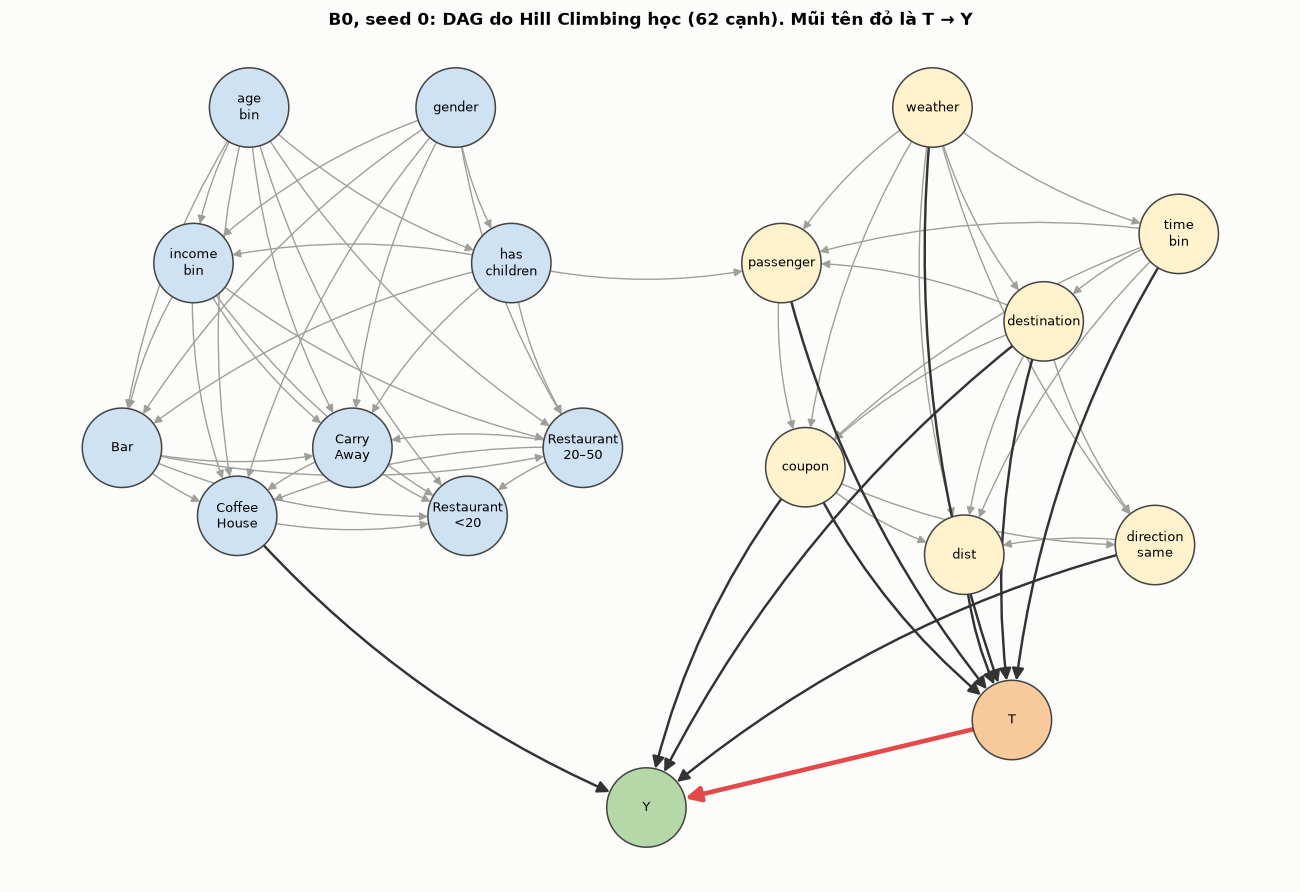

In [20]:
@dataclass
class Model:
    """Chứa dữ liệu mô hình đã học xong (B0, H1 hoặc H2)."""
    name: str                       # "B0", "H1" hoặc "H2"
    edges: list                     # các mũi tên của DAG
    bn: DiscreteBayesianNetwork     # mạng Bayes đầy đủ: DAG + 18 bảng xác suất
    y_parents: list                 # các cha của Y
    y_table: pd.DataFrame           # "bảng Y": P(Y = 1 | cha của Y), dùng cho cả dự đoán lẫn can thiệp
    fit_seconds: float              # thời gian học (giây)
    info: dict                      # thông tin phụ: bảng xếp hạng ứng viên, lịch sử học, ma trận kề...


def build_b0(train: pd.DataFrame, val: pd.DataFrame) -> Model:
    """Xây B0: Hill Climbing đề xuất DAG → VALIDATION chọn → điền bảng xác suất bằng BDeu.

    Tham số: train, val — tập TRAIN và VALIDATION của một seed.
    Trả về: Model tên "B0".
    """
    start = time.time()
    candidates = hc_candidates(train)
    ranking = score_candidates(candidates, train, val)
    chosen = ranking.iloc[0]["ứng viên"]
    edges = candidates[chosen]
    assert check_dag(edges) == [], check_dag(edges)          # DAG được chọn phải qua đủ 11 luật của mục 6
    bn = fit_bn(edges, train)
    table = y_table_of(bn)
    parents = [c for c in table.columns if c != "p1"]
    return Model("B0", edges, bn, parents, table, time.time() - start, {"ranking": ranking, "chosen": chosen})


B0_0 = build_b0(train0, val0)
print(f"DAG được chọn: {B0_0.info['chosen']} | {len(B0_0.edges)} cạnh | lỗi ràng buộc: {check_dag(B0_0.edges)}")
print("Cha của Y:", ", ".join(sorted(B0_0.y_parents)))
print("Cha của T:", ", ".join(sorted(B0_0.bn.get_parents("T"))))
draw_dag(B0_0.edges, f"B0, seed 0: DAG do Hill Climbing học ({len(B0_0.edges)} cạnh). Mũi tên đỏ là T → Y")
plt.savefig(OUT / "dag_b0_seed0.png")

**Cách đọc hình.** Nửa trái là 9 biến của người trả lời (xanh), nửa phải là 7 biến kịch bản (vàng), T (cam) ở góc dưới bên phải và Y (lục) ở dưới cùng. Trong mỗi nửa, nút thuộc lớp trước của `LAYERS` nằm trên; các nút cùng lớp được xếp so le cho dễ đọc nhãn. Mũi tên nối hai lớp khác nhau luôn đi xuống, riêng `has_children → passenger` đi ngang từ nửa trái sang nửa phải. Hai điều cần nhìn: **mũi tên nào đi vào T** (cái gì quyết định hạn coupon) và **mũi tên nào đi vào Y** (cái gì quyết định việc chấp nhận). Biến nào trỏ vào cả hai thì là confounder. Các mũi tên đó được vẽ đậm; phần còn lại vẽ nhạt.

**Lưu ý khi đọc DAG này.** DAG có 62 cạnh: 32 cạnh nối các biến của người trả lời với nhau (17 cạnh nhân khẩu học → thói quen, 10 cạnh giữa các thói quen, 5 cạnh giữa các biến nhân khẩu học), 18 cạnh nối các biến kịch bản với nhau, 6 cạnh vào T, 5 cạnh vào Y, và **một** cạnh bắc cầu từ nửa trái sang nửa phải: `has_children → passenger` (luật 4).

### 8.2 CPD của Y

`fit_bn` đã điền 18 CPD bằng BDeu (mục 7.2). Vẽ lại bảng:
- mỗi dòng là một **hoàn cảnh** (một tổ hợp giá trị của parents khác T)
- hai cột là xác suất chấp nhận khi hạn 1 ngày và khi hạn 2 giờ.

In [21]:
def effect_by_cell(y_table: pd.DataFrame) -> pd.DataFrame:
    """Xoay "bảng Y": mỗi dòng là một hoàn cảnh, đặt cạnh nhau xác suất chấp nhận khi hạn 1 ngày và khi hạn 2 giờ.

    Tham số: y_table — bảng gồm các cột cha của Y và cột p1.
    Trả về: bảng gồm các cha khác T, p_1d, p_2h và diff = p_2h − p_1d (hiệu ứng của hạn coupon trong hoàn cảnh đó).
    """
    others = [c for c in y_table.columns if c not in ("T", "p1")]
    one_day = y_table[y_table["T"] == "0"].drop(columns="T").rename(columns={"p1": "p_1d"})
    two_hours = y_table[y_table["T"] == "1"].drop(columns="T").rename(columns={"p1": "p_2h"})
    wide = one_day.merge(two_hours, on=others) if others else one_day.merge(two_hours, how="cross")
    wide["diff"] = wide["p_2h"] - wide["p_1d"]
    return wide


def cells_with_counts(y_table: pd.DataFrame, train: pd.DataFrame) -> pd.DataFrame:
    """Ghép bảng hoàn cảnh với số dòng TRAIN của từng hoàn cảnh, để biết con số nào đáng tin.

    Tham số: y_table — "bảng Y" của mô hình; train — tập TRAIN.
    Trả về: bảng của effect_by_cell() thêm cột n_1d, n_2h (số dòng TRAIN hạn 1 ngày, hạn 2 giờ), xếp từ hoàn cảnh nhiều dữ liệu nhất.
    """
    others = [c for c in y_table.columns if c not in ("T", "p1")]
    counts = group_table(train, others)[others + ["n_1d", "n_2h"]]
    cells = effect_by_cell(y_table).merge(counts, on=others, how="left").fillna({"n_1d": 0, "n_2h": 0})
    cells[["n_1d", "n_2h"]] = cells[["n_1d", "n_2h"]].astype(int)
    cells["n"] = cells["n_1d"] + cells["n_2h"]
    return cells.sort_values("n", ascending=False).drop(columns="n").reset_index(drop=True)


CELLS_B0 = cells_with_counts(B0_0.y_table, train0)
both_arms = CELLS_B0[(CELLS_B0["n_1d"] > 0) & (CELLS_B0["n_2h"] > 0)]         # hoàn cảnh có dữ liệu cho CẢ hai loại hạn
n_empty = int((CELLS_B0["n_1d"] == 0).sum() + (CELLS_B0["n_2h"] == 0).sum())
print(f"Bảng Y của B0 có {len(B0_0.y_table)} ô = {len(CELLS_B0)} hoàn cảnh × 2 loại hạn; {n_empty} ô không có dòng TRAIN nào (BDeu cho 0,5).")
print(f"{len(both_arms)} hoàn cảnh có dữ liệu cho cả hai loại hạn; trong đó {int((both_arms['diff'] < 0).sum())} hoàn cảnh "
      f"có xác suất chấp nhận khi hạn 2 giờ THẤP hơn khi hạn 1 ngày.")
print("Sáu hoàn cảnh nhiều dữ liệu nhất, rồi bốn hoàn cảnh ít dữ liệu nhất (trong số có đủ hai loại hạn):")
pd.concat([both_arms.head(6), both_arms.tail(4)]).round(3)

Bảng Y của B0 có 240 ô = 120 hoàn cảnh × 2 loại hạn; 71 ô không có dòng TRAIN nào (BDeu cho 0,5).
78 hoàn cảnh có dữ liệu cho cả hai loại hạn; trong đó 64 hoàn cảnh có xác suất chấp nhận khi hạn 2 giờ THẤP hơn khi hạn 1 ngày.
Sáu hoàn cảnh nhiều dữ liệu nhất, rồi bốn hoàn cảnh ít dữ liệu nhất (trong số có đủ hai loại hạn):


,CoffeeHouse,coupon,destination,direction_same,p_1d,p_2h,diff,n_1d,n_2h
0,low,Coffee House,No Urgent Place,0,0.475,0.370,-0.105,320,362
1,low,Restaurant(<20),No Urgent Place,0,0.824,0.662,-0.162,278,290
2,mid,Coffee House,No Urgent Place,0,0.799,0.759,-0.040,184,228
3,low,Bar,No Urgent Place,0,0.340,0.389,0.049,244,108
4,high,Coffee House,No Urgent Place,0,0.787,0.615,-0.172,164,174
5,mid,Restaurant(<20),No Urgent Place,0,0.923,0.799,-0.124,169,159
80,missing,Carry out & Take away,Home,1,0.500,0.997,0.497,2,3
81,missing,Restaurant(20-50),Work,0,0.003,0.010,0.008,4,1
82,missing,Coffee House,Work,1,0.995,0.995,0.000,2,2
86,missing,Carry out & Take away,Work,1,0.990,0.995,0.005,1,2


**Kết quả.** Mỗi dòng là một hoàn cảnh. `p_1d` và `p_2h` là xác suất chấp nhận coupon theo bảng Y khi hạn 1 ngày và khi hạn 2 giờ; `diff = p_2h − p_1d` là hiệu ứng của hạn 2 giờ **trong riêng hoàn cảnh đó**; `n_1d`, `n_2h` là số dòng TRAIN mà bảng dựa vào.

- Bảng Y có 240 ô (120 hoàn cảnh × 2 loại T), trong đó 71 ô không có dòng TRAIN nào. Bảng đếm chỉ đáng tin ở những ô có dữ liệu, và đây chính là chỗ H1 (mục 9) sẽ thử làm tốt hơn. Các ô trống ít khi được dùng: chỉ 2,9% dòng TEST của seed 0 cần tới một ô trống khi can thiệp (bảng ở mục 15).
- Trong 78 hoàn cảnh có dữ liệu cho cả hai loại hạn, 64 hoàn cảnh có `diff` âm. Hạn 2 giờ đi kèm tỉ lệ chấp nhận thấp hơn ở **phần lớn** hoàn cảnh chứ không chỉ ở vài hoàn cảnh cá biệt.
- Bốn dòng cuối cho thấy mặt trái: hoàn cảnh chỉ có vài dòng thì `diff` nhảy rất mạnh (tới +0,50). Cả bốn đều thuộc mức `CoffeeHouse = missing`, mức chỉ có 177 dòng TRAIN chia cho hàng chục hoàn cảnh. Vì vậy ta không đọc từng ô riêng lẻ mà lấy **trung bình trên cả nhóm TEST** (mục 8.5).

### 8.3 DoWhy: tính được hiệu ứng không?

**Ý tưởng.** Có DAG rồi vẫn phải hỏi: *từ observational data, có tính được P(Y | do(T)) không?* <br/>
Bước này gọi là **nhận diện** (identification) và chỉ dựa vào hình dạng của DAG, chưa đụng đến con số nào.<br/>
 DoWhy trả lời tự động: nó tìm một **backdoor adjustment set**, tức nhóm biến mà khi giữ cố định sẽ chặn mọi backdoor path T ← ... → Y.

Mô hình điều chỉnh theo **parents của Y (trừ T)**. Lý do: Y không trỏ đi đâu, nên mọi backdoor path đều phải đi **vào** Y qua một parent của Y; Hàm `backdoor_ok` kiểm tra lại điều này bằng `networkx` cho cả hai tập (tập của DoWhy và tập của mô hình).

In [22]:
def to_dowhy_frame(data: pd.DataFrame) -> pd.DataFrame:
    """Đổi dữ liệu sang dạng DoWhy cần: T và Y là số 0/1, các biến còn lại là kiểu phân loại (category).

    Tham số: data — bảng có 18 biến ở dạng chữ.
    Trả về: bảng 18 cột.
    """
    out = data[NODES].copy()
    out["T"] = as_int(data["T"])
    out["Y"] = as_int(data["Y"])
    for col in COVARIATES:
        out[col] = pd.Categorical(out[col], categories=STATES[col])
    return out


def dowhy_identify(edges: list[tuple[str, str]], data: pd.DataFrame) -> tuple:
    """Đưa DAG cho DoWhy và hỏi: hiệu ứng của T lên Y có nhận diện được không?

    Tham số: edges — các mũi tên của DAG; data — dữ liệu (DoWhy cần để biết tên cột).
    Trả về: (mô hình nhân quả của DoWhy, estimand = công thức nhận diện kèm tập điều chỉnh backdoor).
            DoWhy báo lỗi nếu không nhận diện được.
    """
    dot = "digraph { " + "; ".join(f'"{u}" -> "{v}"' for u, v in edges) + "; }"     # DAG viết theo cú pháp DOT
    model = CausalModel(data=to_dowhy_frame(data), treatment="T", outcome="Y", graph=dot)
    estimand = model.identify_effect(proceed_when_unidentifiable=False)
    return model, estimand


def backdoor_ok(edges: list[tuple[str, str]], adjust: list[str]) -> bool:
    """Tự kiểm tra tiêu chuẩn backdoor cho một tập điều chỉnh bằng networkx.

    Hai điều kiện: (1) không biến nào trong `adjust` là hậu quả của T;
                   (2) xoá các mũi tên đi RA từ T, rồi giữ cố định `adjust`, thì T và Y bị tách rời (d-separated).
    Tham số: edges — các mũi tên của DAG; adjust — tập điều chỉnh cần kiểm tra.
    Trả về: True nếu `adjust` chặn được mọi đường cửa sau.
    """
    graph = nx.DiGraph(edges)
    graph.add_nodes_from(NODES)
    after_T = nx.descendants(graph, "T")
    for z in adjust:
        if z in after_T:
            return False
    graph.remove_edges_from(list(graph.out_edges("T")))        # bỏ đường nhân quả T → ..., chỉ còn lại đường cửa sau
    return bool(nx.is_d_separator(graph, {"T"}, {"Y"}, set(adjust)))


_, ESTIMAND_B0 = dowhy_identify(B0_0.edges, train0)
adjust_dowhy = sorted(ESTIMAND_B0.get_backdoor_variables())
adjust_model = sorted(p for p in B0_0.y_parents if p != "T")
print("Tập điều chỉnh DoWhy chọn       :", adjust_dowhy, "| chặn hết cửa sau:", backdoor_ok(B0_0.edges, adjust_dowhy))
print("Tập điều chỉnh mô hình dùng     :", adjust_model, "| chặn hết cửa sau:", backdoor_ok(B0_0.edges, adjust_model))
print("Không điều chỉnh gì (so sánh thô):", [], "| chặn hết cửa sau:", backdoor_ok(B0_0.edges, []))
print()
print(str(ESTIMAND_B0))

Tập điều chỉnh DoWhy chọn       : ['coupon', 'destination', 'direction_same', 'has_children'] | chặn hết cửa sau: True
Tập điều chỉnh mô hình dùng     : ['CoffeeHouse', 'coupon', 'destination', 'direction_same'] | chặn hết cửa sau: True
Không điều chỉnh gì (so sánh thô): [] | chặn hết cửa sau: False

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
 d                                                       
────(E[Y|coupon,direction_same,has_children,destination])
d[T]                                                     
Estimand assumption 1, Unconfoundedness: If U→{T} and U→Y then P(Y|T,coupon,direction_same,has_children,destination,U) = P(Y|T,coupon,direction_same,has_children,destination)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
 d                                

- Tập của DoWhy  :{`coupon`, `destination`, `direction_same`, `has_children`}
- Tập của mô hình:{`coupon`, `destination`, `direction_same`, `CoffeeHouse`}

=> Khác nhau ở một biến vì cùng chặn một backdoor path: T ← `passenger` ← `has_children` → (các thói quen) → `CoffeeHouse` → Y. Chặn ở `has_children` hay ở `CoffeeHouse` đều được.

### 8.4 Dự đoán Y

**Ý tưởng.** Với mỗi dòng của TEST, tra bảng Y theo giá trị thật của parents → được xác suất chấp nhận coupon. So với câu trả lời thật bằng 4 chỉ số của Bảng A:

| Chỉ số | Đo cái gì | Tốt khi |
|---|---|---|
| AUROC | Lấy ngẫu nhiên một dòng "có nhận" và một dòng "không nhận": mô hình cho dòng "có nhận" xác suất cao hơn trong bao nhiêu phần trăm trường hợp? 0,5 = đoán mò, 1 = hoàn hảo | cao |
| macro-F1 | Đổi xác suất thành nhãn có/không bằng một ngưỡng, rồi chấm độ đúng cho cả hai nhãn, lấy trung bình. Ngưỡng được chọn trên **VALIDATION** | cao |
| Brier | Trung bình của (xác suất dự đoán − kết quả thật)². Đo xác suất có "đúng cỡ" không | thấp |
| Log loss | Giống Brier nhưng phạt rất nặng khi tự tin mà sai | thấp |

In [23]:
def best_f1_threshold(y: np.ndarray, p: np.ndarray) -> float:
    """Tìm ngưỡng đổi xác suất thành nhãn 0/1 cho macro-F1 cao nhất (chỉ gọi trên VALIDATION).

    Tham số: y — nhãn thật 0/1; p — xác suất dự đoán.
    Trả về: ngưỡng trong khoảng 0,05 đến 0,95.
    """
    grid = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y, (p >= thr).astype(int), average="macro") for thr in grid]
    return float(grid[int(np.argmax(scores))])


def prediction_metrics(y: np.ndarray, p: np.ndarray, threshold: float) -> dict:
    """Bốn chỉ số dự đoán của Bảng A.

    Tham số: y — nhãn thật 0/1; p — xác suất dự đoán; threshold — ngưỡng đã chọn trên VALIDATION.
    Trả về: dict gồm auroc, macro_f1, brier, log_loss.
    """
    return {"auroc": roc_auc_score(y, p), "macro_f1": f1_score(y, (p >= threshold).astype(int), average="macro"),
            "brier": brier_score_loss(y, p), "log_loss": log_loss(y, p)}


def evaluate_prediction(model: Model, val: pd.DataFrame, test: pd.DataFrame) -> dict:
    """Chấm khả năng dự đoán Y của một mô hình trên TEST.

    Tham số: model — mô hình đã học; val — để chọn ngưỡng F1; test — để chấm.
    Trả về: dict 4 chỉ số và ngưỡng đã dùng.
    """
    threshold = best_f1_threshold(as_int(val["Y"]), predict_y(model.y_table, val))
    metrics = prediction_metrics(as_int(test["Y"]), predict_y(model.y_table, test), threshold)
    metrics["threshold"] = threshold
    return metrics


PRED_B0 = evaluate_prediction(B0_0, val0, test0)
base_rate = as_int(train0["Y"]).mean()
print(f"Mốc so sánh: nếu luôn đoán bằng tỉ lệ chung {base_rate:.3f} thì AUROC = 0,5 và Brier = {brier_score_loss(as_int(test0['Y']), np.full(len(test0), base_rate)):.4f}.")
pd.DataFrame([PRED_B0], index=["B0, seed 0"]).round(4)

Mốc so sánh: nếu luôn đoán bằng tỉ lệ chung 0.576 thì AUROC = 0,5 và Brier = 0.2430.


,auroc,macro_f1,brier,log_loss,threshold
"B0, seed 0",0.7339,0.6688,0.2045,0.601,0.59


**Cách đọc kết quả.** So với mốc "luôn đoán bằng tỉ lệ chung" in ở dòng đầu: AUROC của B0 là 0,734 (mốc 0,5) và Brier là 0,205 (mốc 0,243), tức mô hình có học được quy luật nhưng còn xa mức hoàn hảo. Điều này hợp lý: quyết định nhận coupon còn phụ thuộc nhiều thứ không có trong dữ liệu. Cột `threshold` là ngưỡng đổi xác suất thành nhãn có/không, được chọn trên VALIDATION rồi mới áp vào TEST, nên macro-F1 không bị "nhìn trộm" đáp án.

Note: các chỉ số này đo khả năng dự đoán Y quan sát được; dự đoán tốt **không** xác nhận ATE đúng. Bảng A (dự đoán) và Bảng B (intervention) trả lời hai câu hỏi khác nhau.

### 8.5 Intervention do(T)

**Ý tưởng.** Làm theo 3 bước:

1. Lấy từng dòng của TEST, **giữ nguyên hoàn cảnh** (loại quán, điểm đến, thói quen...), chỉ **ép** T = 1 ngày rồi tra bảng Y → `q0`. Ép T = 2 giờ rồi tra bảng → `q1`.
2. Lấy trung bình trên mọi dòng TEST: `risk_1d` = trung bình của `q0`, `risk_2h` = trung bình của `q1`.
3. **ATE = risk_2h − risk_1d.**

Vì sao "ép T rồi tra bảng" lại đúng là intervention? Trong DAG, intervention do(T = t) nghĩa là **xoá mọi mũi tên đi vào T** (T không còn do kịch bản quyết định mà do ta đặt) rồi cho T = t. Bảng của Y không đổi, và mọi biến khác đều có trước T nên cũng không đổi. Ô code kiểm tra điều này bằng `pgmpy`: `bn.do(["T"])` tạo mạng đã xoá mũi tên vào T, rồi `VariableElimination` tính xác suất trên mạng đó.

In [24]:
def do_query(y_table: pd.DataFrame, cohort: pd.DataFrame) -> pd.DataFrame:
    """Với từng dòng của cohort, tính xác suất chấp nhận nếu ÉP hạn 1 ngày (q0) và nếu ÉP hạn 2 giờ (q1).

    Tham số: y_table — "bảng Y" của mô hình; cohort — các dòng cần hỏi (chỉ dùng các cột hoàn cảnh, không dùng Y).
    Trả về: bảng 2 cột q0, q1, cùng số dòng với cohort.
    """
    others = [c for c in y_table.columns if c not in ("T", "p1")]
    out = pd.DataFrame(index=cohort.index)
    for t in ("0", "1"):
        what_if = cohort[others].copy()        # giữ nguyên hoàn cảnh của từng dòng
        what_if["T"] = t                       # ... nhưng ép hạn coupon = t cho MỌI dòng
        out[f"q{t}"] = predict_y(y_table, what_if)
    return out


def ate_from_table(y_table: pd.DataFrame, cohort: pd.DataFrame) -> dict:
    """Tính hiệu ứng trung bình của hạn coupon trên một nhóm dòng.

    Tham số: y_table — "bảng Y" của mô hình; cohort — nhóm dòng lấy làm chuẩn (TEST).
    Trả về: dict gồm risk_1d = P(Y=1 | do(T=0)), risk_2h = P(Y=1 | do(T=1)) và ate = risk_2h − risk_1d.
    """
    q = do_query(y_table, cohort)
    return {"risk_1d": float(q["q0"].mean()), "risk_2h": float(q["q1"].mean()), "ate": float((q["q1"] - q["q0"]).mean())}


def check_do_with_pgmpy(model: Model, cohort: pd.DataFrame, n_rows: int = 3) -> pd.DataFrame:
    """Đối chiếu "tra bảng" với phép can thiệp chính thức của pgmpy trên vài dòng đầu của cohort.

    Tham số: model — mô hình cần kiểm; cohort — TEST; n_rows — số dòng đem kiểm.
    Trả về: bảng so sánh, mỗi dòng là một (dòng TEST, giá trị ép cho T); cột `lệch` phải xấp xỉ 0.
    """
    network_after_do = model.bn.do(["T"])                    # pgmpy xoá mọi mũi tên đi vào T
    engine = VariableElimination(network_after_do)           # bộ máy tính xác suất chính xác trên mạng
    lookup = do_query(model.y_table, cohort)
    rows = []
    for i in range(n_rows):
        for t in ("0", "1"):
            evidence = {c: cohort.iloc[i][c] for c in COVARIATES}      # hoàn cảnh đầy đủ của dòng i
            evidence["T"] = t                                          # hạn coupon do ta đặt
            answer = engine.query(["Y"], evidence=evidence, show_progress=False)
            p_pgmpy = float(answer.values[answer.state_names["Y"].index("1")])
            p_lookup = float(lookup[f"q{t}"].iloc[i])
            rows.append({"dòng TEST": i, "ép T": ARM_LABEL[t], "pgmpy do()": p_pgmpy, "tra bảng": p_lookup, "lệch": abs(p_pgmpy - p_lookup)})
    return pd.DataFrame(rows)


Q_B0 = do_query(B0_0.y_table, test0)
ATE_B0 = ate_from_table(B0_0.y_table, test0)
print("Năm dòng TEST đầu tiên: hoàn cảnh của dòng, rồi xác suất chấp nhận nếu ép từng loại hạn")
display(pd.concat([test0[[p for p in B0_0.y_parents if p != "T"]], Q_B0], axis=1).head(5).round(3))
print(f"B0, seed 0: nếu mọi coupon hạn 1 ngày → {ATE_B0['risk_1d']:.3f}; nếu mọi coupon hạn 2 giờ → {ATE_B0['risk_2h']:.3f}; ATE = {ATE_B0['ate']:+.4f}")
print(f"So sánh: hiệu thô trên TRAIN = {NAIVE0['diff']:+.4f}; tính tay điều chỉnh theo coupon và destination = {ate_by_coupon_dest:+.4f}")
print()
print("Đối chiếu với phép can thiệp của pgmpy:")
CHECK_B0 = check_do_with_pgmpy(B0_0, test0)
display(CHECK_B0.round(6))
assert CHECK_B0["lệch"].max() < 1e-9

Năm dòng TEST đầu tiên: hoàn cảnh của dòng, rồi xác suất chấp nhận nếu ép từng loại hạn


,CoffeeHouse,coupon,destination,direction_same,q0,q1
0,low,Restaurant(<20),No Urgent Place,0,0.824,0.662
1,low,Coffee House,No Urgent Place,0,0.475,0.370
2,low,Bar,No Urgent Place,0,0.340,0.389
3,low,Carry out & Take away,No Urgent Place,0,0.855,0.746
4,low,Coffee House,No Urgent Place,0,0.475,0.370


B0, seed 0: nếu mọi coupon hạn 1 ngày → 0.636; nếu mọi coupon hạn 2 giờ → 0.487; ATE = -0.1488
So sánh: hiệu thô trên TRAIN = -0.1368; tính tay điều chỉnh theo coupon và destination = -0.1516

Đối chiếu với phép can thiệp của pgmpy:


,dòng TEST,ép T,pgmpy do(),tra bảng,lệch
0,0,hạn 1 ngày (T = 0),0.823717,0.823717,0.0
1,0,hạn 2 giờ (T = 1),0.662057,0.662057,0.0
2,1,hạn 1 ngày (T = 0),0.475002,0.475002,0.0
3,1,hạn 2 giờ (T = 1),0.370173,0.370173,0.0
4,2,hạn 1 ngày (T = 0),0.340178,0.340178,0.0
5,2,hạn 2 giờ (T = 1),0.388910,0.388910,0.0


**Cách đọc kết quả.**

- Bảng đầu: mỗi dòng TEST có hai con số, `q0` (nếu ép hạn 1 ngày) và `q1` (nếu ép hạn 2 giờ). Hai dòng có cùng hoàn cảnh thì có cùng `q0`, `q1`.
- ATE là trung bình của `q1 − q0`. Dấu âm nghĩa là hạn 2 giờ làm **giảm** tỉ lệ chấp nhận.
- Ở seed 0: nếu mọi coupon có hạn 1 ngày thì 63,6% được chấp nhận, nếu mọi coupon có hạn 2 giờ thì 48,7%, tức ATE = −0,149. Con số này âm hơn hiệu thô (−0,137) và sát với phép tính tay ở mục 5.3 (−0,152).
- Bảng đối chiếu: cột `lệch` bằng 0, tức "ép T rồi tra bảng" cho đúng kết quả của phép intervention chính thức trên mạng đã xoá mũi tên vào T.

<a id="9"></a>
## 9. H1: xác suất bằng neural network

**Mục tiêu.** Giữ **nguyên DAG của B0**, chỉ thay cách tính bảng Y: thay vì đếm trong từng ô, dùng một neural network nhỏ.

**Ý tưởng.** Bảng đếm coi mỗi ô là một thế giới riêng: ô "Bar, về nhà, buổi tối" không học được gì từ ô "Bar, về nhà, buổi sáng". Ô ít dữ liệu thì con số kém tin cậy, ô trống thì chỉ biết trả về 0,5 (mục 8.2). Neural network học **một công thức chung** cho mọi ô, nên các ô na ná nhau chia sẻ thông tin cho nhau.

Các bước:

1. **One-hot:** mạng chỉ nhận số, nên mỗi biến phân loại được đổi thành các cột 0/1. Ví dụ `time_bin` có 3 mức thì thành 3 cột; "morning" là (0, 0, 1).
2. **MLP:** đầu vào → 32 nơ-ron → 16 nơ-ron → 1 số. Số cuối đi qua hàm sigmoid để nằm trong khoảng 0 đến 1, đó là P(Y = 1).
3. **Huấn luyện:** cho mạng xem TRAIN nhiều lượt (*epoch*), mỗi bước chỉnh trọng số để log loss giảm. Sau mỗi lượt, chấm trên VALIDATION. Nếu 10 lượt liền VALIDATION không tốt lên thì dừng và lấy lại mạng ở lượt tốt nhất (*early stopping*).
4. **Đổi lại thành bảng:** hỏi mạng xác suất cho **mọi** ô, được một bảng Y mới, rồi đặt bảng đó vào Bayesian Network thay cho bảng cũ. Nhờ vậy H1 vẫn là một Bayesian Network bình thường, và mọi hàm ở mục 8 (dự đoán, intervention, đối chiếu pgmpy) dùng lại được y nguyên.

In [25]:
def onehot(data: pd.DataFrame, cols: list[str]) -> np.ndarray:
    """Đổi các cột phân loại thành ma trận 0/1: mỗi mức của mỗi cột thành một cột riêng.

    Tham số: data — bảng dữ liệu; cols — các cột cần đổi.
    Trả về: ma trận (số dòng × tổng số mức), kiểu float32. Thứ tự cột theo STATES nên cố định cho mọi lần gọi.
    """
    columns = []
    for col in cols:
        values = data[col].to_numpy()
        for state in STATES[col]:
            columns.append((values == state).astype(np.float32))
    return np.stack(columns, axis=1)


def build_mlp(n_inputs: int) -> torch.nn.Sequential:
    """Tạo MLP: n_inputs → 32 → 16 → 1 (kích thước lớp ẩn lấy từ Config).

    Tham số: n_inputs — số cột one-hot đầu vào.
    Trả về: mạng trả ra một số thực (logit); đưa qua sigmoid sẽ thành xác suất.
    """
    layers = []
    size = n_inputs
    for hidden in CFG.h1_hidden:
        layers += [torch.nn.Linear(size, hidden),       # lớp tuyến tính: tổ hợp có trọng số của đầu vào
                   torch.nn.ReLU(),                     # hàm kích hoạt: giữ số dương, số âm thành 0 (tạo tính phi tuyến)
                   torch.nn.Dropout(CFG.h1_dropout)]    # khi học, tắt ngẫu nhiên một phần nơ-ron để chống học vẹt
        size = hidden
    layers.append(torch.nn.Linear(size, 1))
    return torch.nn.Sequential(*layers)


def train_mlp(X_train: np.ndarray, y_train: np.ndarray, X_val: np.ndarray, y_val: np.ndarray, seed: int) -> tuple[torch.nn.Sequential, pd.DataFrame]:
    """Huấn luyện MLP dự đoán Y, dừng sớm theo VALIDATION.

    Tham số: X_train, y_train — one-hot của các cha của Y và nhãn Y trên TRAIN; X_val, y_val — tương tự trên VALIDATION; seed — hạt giống.
    Trả về: (mạng ở lượt có loss VALIDATION thấp nhất, bảng lịch sử loss theo từng lượt).
    """
    torch.manual_seed(seed)
    net = build_mlp(X_train.shape[1])
    optimizer = torch.optim.Adam(net.parameters(), lr=CFG.h1_lr)
    loss_fn = torch.nn.BCEWithLogitsLoss()                  # chính là log loss, tính trực tiếp từ logit
    Xt, yt = torch.tensor(X_train), torch.tensor(y_train, dtype=torch.float32)
    Xv, yv = torch.tensor(X_val), torch.tensor(y_val, dtype=torch.float32)
    best_loss, best_weights, bad_epochs, history = np.inf, None, 0, []
    for epoch in range(CFG.h1_max_epochs):
        # ----- Một lượt học: xáo trộn TRAIN, chia thành từng lô nhỏ, mỗi lô chỉnh trọng số một lần -----
        net.train()
        order = torch.randperm(len(Xt))
        for start in range(0, len(Xt), CFG.h1_batch):
            batch = order[start:start + CFG.h1_batch]
            optimizer.zero_grad()
            loss = loss_fn(net(Xt[batch]).squeeze(1), yt[batch])
            loss.backward()                                 # tính hướng cần chỉnh cho từng trọng số
            optimizer.step()                                # chỉnh trọng số một bước nhỏ theo hướng đó
        # ----- Chấm sau lượt học (tắt dropout bằng net.eval()) -----
        net.eval()
        with torch.no_grad():
            train_loss = loss_fn(net(Xt).squeeze(1), yt).item()
            val_loss = loss_fn(net(Xv).squeeze(1), yv).item()
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
        # ----- Early stopping -----
        if val_loss < best_loss - 1e-5:
            best_loss, bad_epochs = val_loss, 0
            best_weights = {name: w.clone() for name, w in net.state_dict().items()}     # chụp lại mạng tốt nhất
        else:
            bad_epochs += 1
            if bad_epochs >= CFG.h1_patience:
                break
    net.load_state_dict(best_weights)
    net.eval()
    return net, pd.DataFrame(history)


def mlp_y_table(net: torch.nn.Sequential, parents: list[str]) -> pd.DataFrame:
    """Hỏi MLP xác suất P(Y = 1) cho MỌI tổ hợp giá trị của các cha → "bảng Y" cùng dạng với B0.

    Tham số: net — mạng đã huấn luyện; parents — các cha của Y (đúng thứ tự đã dùng khi huấn luyện).
    Trả về: bảng gồm các cột cha và cột p1.
    """
    cells = pd.DataFrame(list(itertools.product(*[STATES[p] for p in parents])), columns=parents)
    with torch.no_grad():
        p1 = torch.sigmoid(net(torch.tensor(onehot(cells, parents))).squeeze(1)).numpy().astype(float)
    cells["p1"] = np.clip(p1, 1e-6, 1 - 1e-6)              # tránh đúng 0 hoặc đúng 1 (log loss sẽ vô cực)
    return cells


def y_table_to_cpd(y_table: pd.DataFrame) -> TabularCPD:
    """Gói "bảng Y" thành bảng xác suất hợp lệ của pgmpy, để đặt vào mạng Bayes.

    Tham số: y_table — bảng từ mlp_y_table() (các ô xếp đúng thứ tự itertools.product).
    Trả về: TabularCPD của nút Y.
    """
    parents = [c for c in y_table.columns if c != "p1"]
    p1 = y_table["p1"].to_numpy()
    state_names = {"Y": STATES["Y"]}
    for p in parents:
        state_names[p] = STATES[p]
    return TabularCPD("Y", 2, np.vstack([1 - p1, p1]), evidence=parents, evidence_card=[len(STATES[p]) for p in parents], state_names=state_names)


def build_h1(b0: Model, train: pd.DataFrame, val: pd.DataFrame, seed: int) -> Model:
    """Xây H1: giữ DAG và mọi bảng xác suất của B0, chỉ thay bảng của Y bằng bảng do MLP sinh ra.

    Tham số: b0 — mô hình B0 của cùng seed; train, val — dữ liệu; seed — hạt giống của MLP.
    Trả về: Model tên "H1" (fit_seconds chỉ tính thời gian huấn luyện MLP).
    """
    start = time.time()
    parents = b0.y_parents
    net, history = train_mlp(onehot(train, parents), as_int(train["Y"]), onehot(val, parents), as_int(val["Y"]), seed)
    table = mlp_y_table(net, parents)
    bn = b0.bn.copy()                         # bản sao của B0, để B0 gốc không bị đổi
    bn.remove_cpds("Y")                       # bỏ bảng Y do đếm
    bn.add_cpds(y_table_to_cpd(table))        # đặt bảng Y do MLP sinh
    assert bn.check_model()
    n_params = sum(w.numel() for w in net.parameters())
    return Model("H1", b0.edges, bn, parents, table, time.time() - start, {"net": net, "history": history, "n_params": n_params})


def summary_row(model: Model, val: pd.DataFrame, test: pd.DataFrame) -> dict:
    """Tóm tắt một mô hình thành một dòng: cấu trúc, 4 chỉ số dự đoán và ATE trên TEST.

    Tham số: model — mô hình đã học; val, test — dữ liệu của cùng seed.
    Trả về: dict một dòng của bảng so sánh.
    """
    row = {"mô hình": model.name, "số cạnh": len(model.edges), "số cha của Y": len(model.y_parents), "số ô bảng Y": len(model.y_table)}
    row.update(evaluate_prediction(model, val, test))
    row.update(ate_from_table(model.y_table, test))
    return row


H1_0 = build_h1(B0_0, train0, val0, seed=0)
history = H1_0.info["history"]
print(f"MLP có {H1_0.info['n_params']} trọng số; học {len(history)} lượt trong {H1_0.fit_seconds:.1f} giây; "
      f"giữ mạng ở lượt {int(history['val_loss'].idxmin())} (loss VALIDATION = {history['val_loss'].min():.4f}).")
print("Đối chiếu can thiệp với pgmpy cho H1: lệch lớn nhất =", f"{check_do_with_pgmpy(H1_0, test0)['lệch'].max():.1e}")
pd.DataFrame([summary_row(B0_0, val0, test0), summary_row(H1_0, val0, test0)]).set_index("mô hình").round(4)

MLP có 1089 trọng số; học 79 lượt trong 4.2 giây; giữ mạng ở lượt 68 (loss VALIDATION = 0.5963).
Đối chiếu can thiệp với pgmpy cho H1: lệch lớn nhất = 0.0e+00


,số cạnh,số cha của Y,số ô bảng Y,auroc,macro_f1,brier,log_loss,threshold,risk_1d,risk_2h,ate
mô hình,,,,,,,,,,,
B0,62,5,240,0.7339,0.6688,0.2045,0.6010,0.59,0.6363,0.4874,-0.1488
H1,62,5,240,0.7376,0.6658,0.2029,0.5922,0.59,0.6374,0.4871,-0.1503


**Kết quả ở seed 0.** Mạng có 1.089 trọng số, học 79 epoch trong khoảng 4 giây và giữ lại mạng của epoch 68 (log loss trên VALIDATION là 0,596). Trên TEST, H1 nhỉnh hơn B0 một chút về dự đoán (AUROC 0,738 so với 0,734; log loss 0,592 so với 0,601) và cho ATE gần như trùng B0 (−0,150 so với −0,149). "Ép T rồi tra bảng" vẫn trùng với `do()` của pgmpy.

Hình dưới cho thấy H1 học thế nào và bảng Y của nó khác B0 ở đâu.

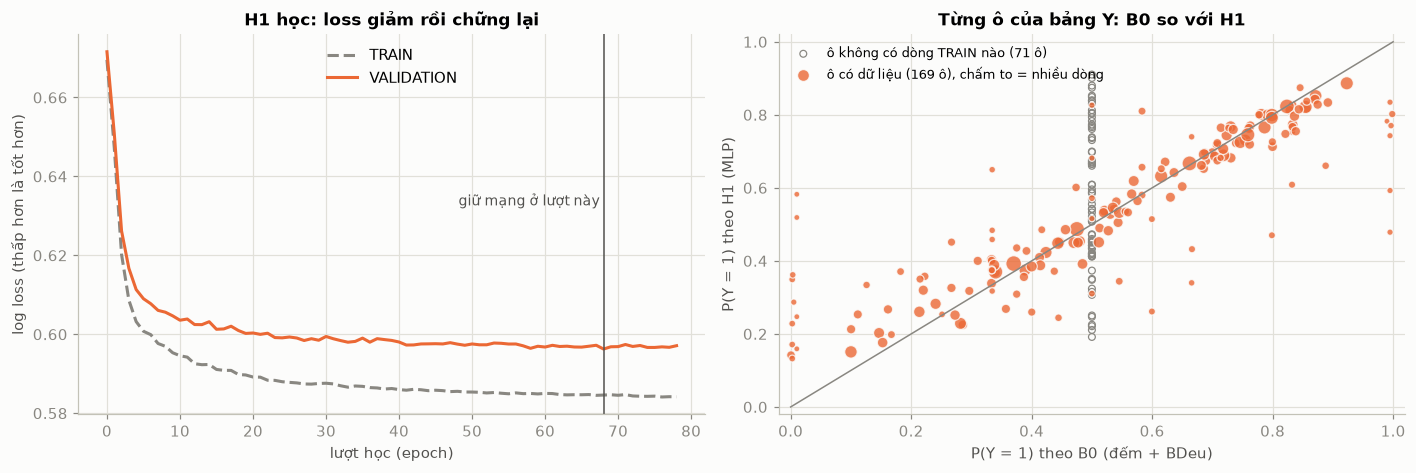

In [26]:
def plot_h1(h1: Model, b0: Model, train: pd.DataFrame) -> None:
    """Vẽ hai hình cho H1: (trái) loss theo từng lượt học; (phải) so từng ô của bảng Y giữa B0 và H1.

    Tham số: h1, b0 — hai mô hình của cùng seed; train — TRAIN (để đếm số dòng của từng ô).
    """
    history = h1.info["history"]
    best_epoch = int(history["val_loss"].idxmin())
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.4))
    # ----- Trái: đường học -----
    left.plot(history["epoch"], history["train_loss"], color=MUTED, linestyle="--", label="TRAIN")
    left.plot(history["epoch"], history["val_loss"], color=COLOR["H1"], label="VALIDATION")
    left.axvline(best_epoch, color=INK_SOFT, linewidth=1)
    left.text(best_epoch, 0.55, "giữ mạng ở lượt này ", transform=left.get_xaxis_transform(), color=INK_SOFT, ha="right", fontsize=9)
    left.set_xlabel("lượt học (epoch)")
    left.set_ylabel("log loss (thấp hơn là tốt hơn)")
    left.set_title("H1 học: loss giảm rồi chững lại")
    left.legend(loc="upper center")
    # ----- Phải: mỗi chấm là một ô của bảng Y -----
    parents = b0.y_parents
    counts = train.groupby(parents).size().rename("n").reset_index()
    both = b0.y_table.rename(columns={"p1": "b0"}).merge(h1.y_table.rename(columns={"p1": "h1"}), on=parents)
    both = both.merge(counts, on=parents, how="left").fillna({"n": 0})
    seen, empty = both[both["n"] > 0], both[both["n"] == 0]
    right.plot([0, 1], [0, 1], color=MUTED, linewidth=1)                 # đường chéo: hai mô hình cho cùng xác suất
    right.scatter(empty["b0"], empty["h1"], s=20, facecolors="none", edgecolors=MUTED, linewidths=0.8,
                  label=f"ô không có dòng TRAIN nào ({len(empty)} ô)")
    right.scatter(seen["b0"], seen["h1"], s=10 + 5 * np.sqrt(seen["n"]), color=COLOR["H1"], alpha=0.8, edgecolors="#fcfcfb", linewidths=0.8,
                  label=f"ô có dữ liệu ({len(seen)} ô), chấm to = nhiều dòng")
    right.set_xlabel("P(Y = 1) theo B0 (đếm + BDeu)")
    right.set_ylabel("P(Y = 1) theo H1 (MLP)")
    right.set_title("Từng ô của bảng Y: B0 so với H1")
    right.set_xlim(-0.02, 1.02)
    right.set_ylim(-0.02, 1.02)
    right.legend(loc="upper left", fontsize=8.5)
    fig.tight_layout()
    fig.savefig(OUT / "h1_seed0.png")


plot_h1(H1_0, B0_0, train0)

**Cách đọc hình.**

- *Trái:* hai đường cùng giảm nghĩa là mạng đang cải thiện độ khớp dự đoán. Khi đường VALIDATION (cam) thôi giảm trong lúc đường TRAIN (xám) vẫn giảm, mạng bắt đầu học vẹt, và early stopping dừng tại đó.
- *Phải:* chấm nằm trên đường chéo là ô mà hai mô hình cho cùng xác suất. Chấm to (ô nhiều dữ liệu) nằm sát đường chéo: ở đâu có đủ dữ liệu thì đếm và MLP đồng ý với nhau. Các vòng tròn rỗng xếp thành một cột dọc tại 0,5: đó là các ô trống, B0 chỉ biết trả về 0,5 còn H1 đưa ra một dự đoán dựa trên các ô tương tự.

<a id="10"></a>
## 10. H2: DAG bằng neural network

**Mục tiêu.** Tìm DAG bằng neural network (NOTEARS-MLP) thay cho Hill Climbing. Mọi thứ khác giữ như B0

**Ý tưởng.** Hill Climbing thử từng mũi tên một. NOTEARS đổi bài toán thành "vặn núm liên tục":

1. **Mỗi nút có một mạng nhỏ** đoán nút đó từ 17 nút còn lại. Nếu mạng của nút *j* dựa nhiều vào nút *i* (các trọng số nối từ *i* lớn) thì coi như có mũi tên *i → j*. Gom lại được ma trận A, với A[i, j] = **độ mạnh** của mũi tên i → j.
2. **Phạt thưa (L1):** nếu để tự do, mạng nào cũng dùng tất cả các nút khác. Phạt L1 ép các trọng số không cần thiết về 0, chỉ để lại cạnh thật sự hữu ích.
3. **Phạt vòng kín:** có một hàm h(A) bằng 0 **đúng khi** đồ thị không có vòng kín, và càng lớn khi vòng càng nhiều, càng mạnh. Thuật toán tối ưu "độ khớp dữ liệu + phạt" và tăng dần mức phạt vòng kín (nhân 10 mỗi khi h giảm chậm) cho đến khi h gần 0.
4. **Ràng buộc mục 6:** trọng số của các cạnh bị cấm được nhân với 0 (ma trận `MASK`), nên chúng không bao giờ xuất hiện.
5. **Cắt ngưỡng:** giữ mũi tên có độ mạnh lớn hơn một ngưỡng. Thử 5 ngưỡng và để VALIDATION chọn, theo **đúng quy tắc** đã dùng cho B0 (hàm `score_candidates`).

**Một lựa chọn cần nói rõ.** Hạn coupon T chỉ phụ thuộc yếu vào kịch bản (phần lớn là ngẫu nhiên), nên các cạnh "kịch bản → T" yếu hơn hẳn các cạnh khác. Với mức phạt L1 chung, NOTEARS hay xoá sạch parents của T, tức xoá luôn cấu trúc confounding mà bài toán cần mô tả. Vì vậy phạt L1 cho các cạnh **đi vào T** được giảm 10 lần (`h2_l1_scale_T = 0.1`). Con số này lấy từ bản đầy đủ trước đó (notebook 03), nơi ba mức 1,0 / 0,3 / 0,1 được so trên VALIDATION: mức 0,1 được chọn ở 4/5 seed, còn mức 1,0 làm T mất hết parents ở 3/5 seed. Trong bản đó, lựa chọn này không làm đổi parent set của Y nên không làm đổi ATE của H2. **Giới hạn:** con số 0,1 được dùng lại nguyên như vậy, chưa dò lại trên bộ 18 biến của notebook này.

In [27]:
def notears_init(seed: int) -> dict:
    """Tạo trọng số ban đầu cho 18 mạng nhỏ (mỗi nút một mạng) và các ma trận phụ trợ.

    Tham số: seed — hạt giống cho trọng số ngẫu nhiên ban đầu.
    Trả về: dict gồm
        W1  (18, hidden, D)  lớp 1 của mạng từng nút; D = tổng số cột one-hot của 18 nút
        b1  (18, hidden)     hệ số tự do của lớp 1
        W2, b2               lớp ra của từng nút (danh sách 18 phần tử vì mỗi nút có số mức khác nhau)
        mask (18, 18)        mask[i, j] = 1 nếu mũi tên i → j được phép
        col_mask (18, D)     col_mask[j, c] = 1 nếu nút chứa cột one-hot c được phép làm cha của nút j
        col_to_node (D, 14)  cột one-hot c thuộc nút nào (để gom các cột của cùng một nút)
        l1_weight (18,)      hệ số nhân phạt L1 theo nút đích (T nhận mức nhẹ hơn)
    """
    torch.manual_seed(seed)
    sizes = [len(STATES[n]) for n in NODES]                           # số mức của từng nút
    d, D, hidden = len(NODES), sum(sizes), CFG.h2_hidden
    node_of_col = torch.tensor(np.repeat(np.arange(d), sizes))        # cột one-hot thứ c thuộc nút nào
    mask = torch.tensor(MASK)
    l1_weight = torch.ones(d)
    l1_weight[NODES.index("T")] = CFG.h2_l1_scale_T
    return {"W1": (torch.randn(d, hidden, D) * 0.1).requires_grad_(True),
            "b1": torch.zeros(d, hidden, requires_grad=True),
            "W2": [(torch.randn(k, hidden) * 0.1).requires_grad_(True) for k in sizes],
            "b2": [torch.zeros(k, requires_grad=True) for k in sizes],
            "mask": mask, "col_mask": mask[node_of_col, :].T.contiguous(),
            "col_to_node": torch.nn.functional.one_hot(node_of_col, d).float(), "l1_weight": l1_weight}


def notears_adjacency(p: dict) -> torch.Tensor:
    """Tính ma trận độ mạnh A từ trọng số lớp 1: A[i, j] lớn nghĩa là mạng của nút j dựa nhiều vào nút i.

    Tham số: p — dict từ notears_init().
    Trả về: tensor 18 × 18; ô của cạnh bị cấm luôn bằng 0.
    """
    w = p["W1"] * p["col_mask"][:, None, :]            # chặn các cột đầu vào không được phép
    per_col = (w ** 2).sum(dim=1)                      # (18, D): với nút đích j, tổng bình phương trọng số của từng cột đầu vào
    per_node = per_col @ p["col_to_node"]              # (18, 18): gom các cột one-hot của cùng một nút nguồn → [j, i]
    return torch.sqrt(per_node.T + 1e-12) * p["mask"]  # chuyển vị để chỉ số là [i, j] = i → j


def notears_data_loss(p: dict, X: torch.Tensor, idx: torch.Tensor) -> torch.Tensor:
    """Độ khớp dữ liệu: tổng log loss của 18 mạng, mỗi mạng đoán một nút từ các nút còn lại.

    Tham số: p — trọng số; X — one-hot của cả 18 nút (n × D); idx — số thứ tự mức của từng nút ở từng dòng (n × 14).
    Trả về: một số (tensor vô hướng); càng nhỏ là càng khớp.
    """
    total = torch.zeros(())
    for j in range(len(NODES)):
        w1 = p["W1"][j] * p["col_mask"][j]                             # mạng của nút j chỉ được nhìn các nút được phép làm cha
        hidden = torch.relu(X @ w1.T + p["b1"][j])                     # lớp ẩn
        logits = hidden @ p["W2"][j].T + p["b2"][j]                    # điểm cho từng mức của nút j
        total = total + torch.nn.functional.cross_entropy(logits, idx[:, j])
    return total


def notears_cycle(A: torch.Tensor) -> torch.Tensor:
    """Độ "có vòng kín" của đồ thị: h(A) = trace(exp(A ∘ A)) − số nút. Bằng 0 đúng khi không có vòng kín nào.

    Tham số: A — ma trận độ mạnh.
    Trả về: một số không âm (tensor vô hướng).
    """
    return torch.trace(torch.matrix_exp(A * A)) - A.shape[0]


def notears_closure(optimizer: torch.optim.Optimizer, p: dict, X: torch.Tensor, idx: torch.Tensor, rho: float, alpha: float) -> torch.Tensor:
    """Hàm mục tiêu cho một bước tối ưu = độ khớp dữ liệu + phạt vòng kín + phạt thưa (L1) + phạt trọng số lớn (L2).

    Tham số: optimizer — bộ tối ưu LBFGS; p — trọng số; X, idx — dữ liệu; rho, alpha — mức phạt vòng kín hiện tại.
    Trả về: giá trị hàm mục tiêu (đã tính gradient). LBFGS gọi hàm này nhiều lần trong một bước.
    """
    optimizer.zero_grad()
    h = notears_cycle(notears_adjacency(p))
    l1 = (p["l1_weight"][:, None, None] * p["W1"] * p["col_mask"][:, None, :]).abs().sum()
    l2 = (p["W1"] ** 2).sum()
    for w2 in p["W2"]:
        l2 = l2 + (w2 ** 2).sum()
    objective = notears_data_loss(p, X, idx) + 0.5 * rho * h * h + alpha * h + CFG.h2_lambda1 * l1 + 0.5 * CFG.h2_lambda2 * l2
    objective.backward()
    return objective


def notears_learn(train: pd.DataFrame, seed: int, verbose: bool = False) -> tuple[np.ndarray, pd.DataFrame]:
    """Chạy NOTEARS-MLP có mask trên TRAIN.

    Tham số: train — tập TRAIN; seed — hạt giống; verbose — True thì in tiến trình từng vòng.
    Trả về: (ma trận độ mạnh A 18 × 18 với A[i, j] = độ mạnh của NODES[i] → NODES[j], bảng nhật ký từng vòng).
    """
    p = notears_init(seed)
    X = torch.tensor(onehot(train, NODES))
    index_columns = []
    for node in NODES:                                   # đổi mỗi giá trị thành số thứ tự của nó trong STATES
        position = {state: k for k, state in enumerate(STATES[node])}
        index_columns.append(train[node].map(position).to_numpy().astype(np.int64))
    idx = torch.tensor(np.stack(index_columns, axis=1))
    trainable = [p["W1"], p["b1"]] + p["W2"] + p["b2"]
    rho, alpha, h = 1.0, 0.0, np.inf                     # rho, alpha: mức phạt vòng kín; h: độ có vòng hiện tại
    log = []
    for step in range(CFG.h2_max_outer):
        # Tối ưu với mức phạt hiện tại. Nếu vòng kín chưa giảm xuống dưới 1/4 lần trước thì nhân mức phạt lên 10 và làm lại.
        while rho < CFG.h2_rho_max:
            optimizer = torch.optim.LBFGS(trainable, lr=1.0, max_iter=CFG.h2_inner_steps, line_search_fn="strong_wolfe")
            # LBFGS cần một hàm không tham số; functools.partial "điền sẵn" các tham số thay cho việc viết hàm lồng
            optimizer.step(functools.partial(notears_closure, optimizer, p, X, idx, rho, alpha))
            with torch.no_grad():
                h_new = float(notears_cycle(notears_adjacency(p)))
            if h_new > 0.25 * h:
                rho *= 10
            else:
                break
        h = h_new
        alpha += rho * h
        with torch.no_grad():
            fit = float(notears_data_loss(p, X, idx))
        log.append({"vòng": step, "h (độ có vòng)": h, "rho (mức phạt)": rho, "độ khớp": fit})
        if verbose:
            print(f"  vòng {step:2d}: h = {h:.2e} | mức phạt rho = {rho:.0e} | độ khớp = {fit:.4f}")
        if h <= CFG.h2_h_tol or rho >= CFG.h2_rho_max:
            break
    with torch.no_grad():
        A = notears_adjacency(p).numpy()
    assert np.all(A[MASK == 0] == 0), "cạnh bị cấm phải có độ mạnh bằng 0"
    return A, pd.DataFrame(log)


def threshold_dag(A: np.ndarray, threshold: float) -> list[tuple[str, str]]:
    """Đổi ma trận độ mạnh thành DAG: giữ cạnh mạnh hơn ngưỡng, phá vòng kín nếu còn, thêm cạnh bắt buộc.

    Tham số: A — ma trận độ mạnh; threshold — ngưỡng giữ cạnh.
    Trả về: danh sách mũi tên của một DAG.
    """
    graph = nx.DiGraph()
    graph.add_nodes_from(NODES)
    for i, u in enumerate(NODES):
        for j, v in enumerate(NODES):
            if A[i, j] > threshold:
                graph.add_edge(u, v, weight=float(A[i, j]))
    while not nx.is_directed_acyclic_graph(graph):          # nếu còn vòng kín: bỏ cạnh yếu nhất của vòng đó
        cycle = list(nx.find_cycle(graph))
        weights = [graph.edges[edge]["weight"] for edge in cycle]
        graph.remove_edge(*cycle[int(np.argmin(weights))])
    for u, v in REQUIRED:                                   # luật 10: T → Y phải có
        if not graph.has_edge(u, v):
            graph.add_edge(u, v)
    return sorted(graph.edges())


def build_h2(train: pd.DataFrame, val: pd.DataFrame, seed: int, verbose: bool = False) -> Model:
    """Xây H2: NOTEARS-MLP học ma trận độ mạnh → thử 5 ngưỡng → VALIDATION chọn DAG → điền bảng xác suất bằng BDeu.

    Tham số: train, val — dữ liệu của một seed; seed — hạt giống của NOTEARS; verbose — in tiến trình.
    Trả về: Model tên "H2".
    """
    start = time.time()
    A, log = notears_learn(train, seed, verbose)
    candidates, threshold_of = {}, {}
    for threshold in CFG.h2_thresholds:
        name = f"ngưỡng {threshold:.2f}"
        candidates[name] = threshold_dag(A, threshold)
        threshold_of[name] = threshold
    ranking = score_candidates(candidates, train, val)       # cùng quy tắc chọn với B0
    chosen = ranking.iloc[0]["ứng viên"]
    edges = candidates[chosen]
    assert check_dag(edges) == [], check_dag(edges)
    bn = fit_bn(edges, train)
    table = y_table_of(bn)
    parents = [c for c in table.columns if c != "p1"]
    found_TY = bool(A[NODES.index("T"), NODES.index("Y")] > threshold_of[chosen])      # NOTEARS có tự tìm ra T → Y không?
    info = {"A": A, "log": log, "ranking": ranking, "chosen": chosen, "threshold": threshold_of[chosen], "found_TY": found_TY}
    return Model("H2", edges, bn, parents, table, time.time() - start, info)


H2_0 = build_h2(train0, val0, seed=0, verbose=True)
print(f"NOTEARS chạy {len(H2_0.info['log'])} vòng; tổng thời gian H2: {H2_0.fit_seconds:.0f} giây.")
with pd.option_context("display.max_colwidth", 90):
    display(H2_0.info["ranking"].round(4))

  vòng  0: h = 3.54e-01 | mức phạt rho = 1e+00 | độ khớp = 14.5102


  vòng  1: h = 4.04e-02 | mức phạt rho = 1e+02 | độ khớp = 14.9128


  vòng  2: h = 7.56e-03 | mức phạt rho = 1e+03 | độ khớp = 15.0894


  vòng  3: h = 1.11e-03 | mức phạt rho = 1e+04 | độ khớp = 15.1852


  vòng  4: h = 2.23e-04 | mức phạt rho = 1e+05 | độ khớp = 15.2147


  vòng  5: h = 1.53e-05 | mức phạt rho = 1e+07 | độ khớp = 15.2322


  vòng  6: h = 3.81e-06 | mức phạt rho = 1e+09 | độ khớp = 15.2363


NOTEARS chạy 7 vòng; tổng thời gian H2: 82 giây.


,ứng viên,hợp lệ,số cạnh,cha của Y,cha của T,val log-loss Y,val LL cả mạng
0,ngưỡng 0.15,True,40,"CoffeeHouse, T, coupon, destination, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather",0.6010,-15.9235
1,ngưỡng 0.10,True,46,"CoffeeHouse, T, coupon, destination, passenger, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather",0.6193,-18.0327
2,ngưỡng 0.20,True,27,"T, coupon","coupon, direction_same, dist, passenger, time_bin, weather",0.6376,-14.4987
3,ngưỡng 0.30,True,23,"T, coupon","coupon, direction_same, dist, passenger, time_bin, weather",0.6376,-14.5495
4,ngưỡng 0.05,True,59,"CoffeeHouse, Restaurant20To50, T, age_bin, coupon, destination, direction_same, dist, ...","coupon, destination, direction_same, dist, passenger, time_bin, weather",1.4513,-20.1251


**Cách đọc kết quả.**

- *Nhật ký:* `h` giảm dần về 0 nghĩa là các vòng kín đang bị loại; `rho` tăng là mức phạt được siết lại. `độ khớp` tăng nhẹ là cái giá của việc bỏ bớt cạnh.
- *Bảng ngưỡng:* ngưỡng thấp giữ nhiều cạnh, ngưỡng cao giữ ít. Dòng đầu là DAG được chọn. Cột `cha của T` cho biết H2 có tìm lại được các mũi tên kịch bản → T không.

**Kết quả ở seed 0.** NOTEARS dừng sau 7 vòng, khi h còn khoảng 3,8 × 10⁻⁶, mất khoảng 80 giây ở lần chạy này (máy đang bận việc khác; trong vòng lặp ở mục 11, H2 mất 15–35 giây mỗi seed). VALIDATION chọn ngưỡng 0,15: 40 cạnh, log-loss của Y trên VALIDATION là 0,601, tốt hơn rõ so với ngưỡng 0,10 (0,619) và 0,20 (0,638). T nhận đủ 7 biến kịch bản làm parents. Y có parents `T`, `coupon`, `destination`, `weather` và `CoffeeHouse`. Cạnh T → Y vượt ngưỡng, tức NOTEARS **tự tìm ra** nó, không cần luật 10 ép vào. Ở ngưỡng 0,05, Y nhận 9 parents ngoài T và log-loss vọt lên 1,45: bảng Y quá to so với dữ liệu.

**Ghi chú về `h2_h_tol`.** Notebook 05 dừng NOTEARS khi h < 10⁻⁸. Với bộ luật chặt, notebook 06 gặp lỗi số học (NaN) ở ngưỡng đó nên dùng 10⁻⁵; bản này dùng 10⁻⁵ cho giống notebook 06. Mọi DAG sau khi cắt ngưỡng vẫn được `check_dag` kiểm tra là không có vòng kín.

Hình dưới là ma trận độ mạnh A: hàng là nút **đi**, cột là nút **đến**. Ô xám là cạnh bị cấm (luôn bằng 0). Ô có ghi số là cạnh được giữ lại ở ngưỡng đã chọn.

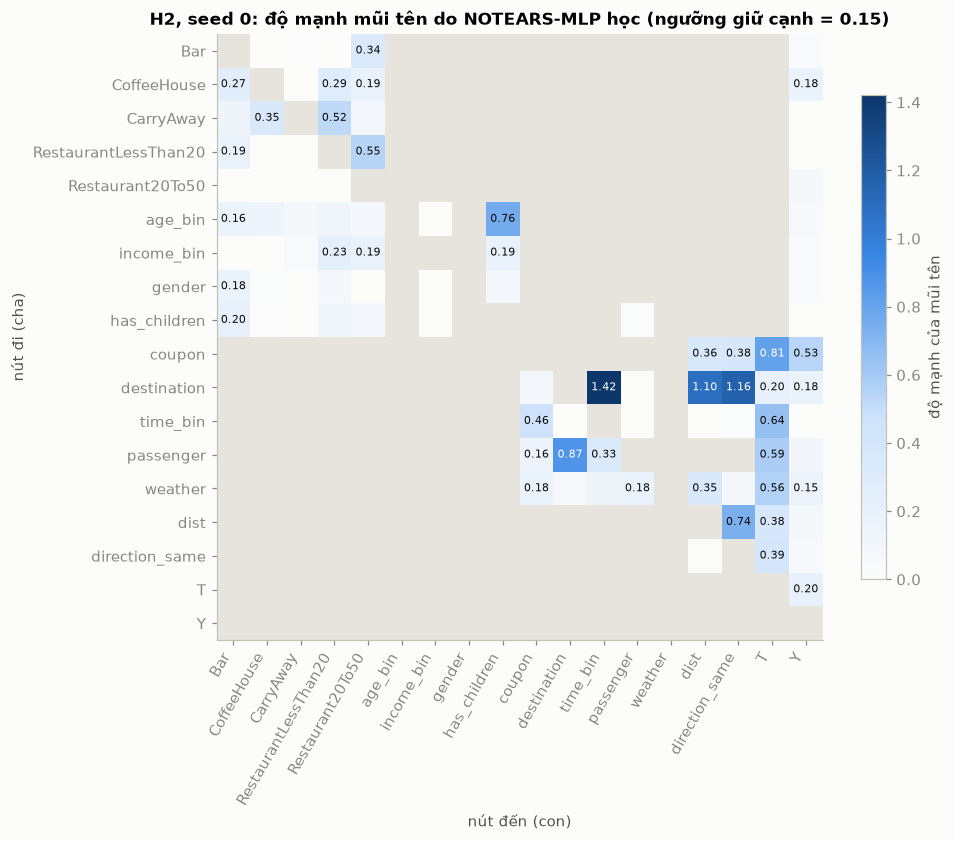

In [28]:
def plot_adjacency(A: np.ndarray, threshold: float, title: str) -> None:
    """Vẽ ma trận độ mạnh của H2 dạng bản đồ nhiệt; ô bị cấm tô xám; ghi số cho các ô vượt ngưỡng.

    Tham số: A — ma trận độ mạnh 18 × 18; threshold — ngưỡng đã chọn; title — tiêu đề.
    """
    cmap = LinearSegmentedColormap.from_list("blue", ["#fcfcfb", "#cde2fb", "#3987e5", "#0d366b"])   # một màu, nhạt → đậm
    cmap.set_bad("#e6e4dd")                                    # màu cho ô bị cấm
    fig, ax = plt.subplots(figsize=(9.2, 7.6))
    image = ax.imshow(np.ma.masked_where(MASK == 0, A), cmap=cmap, vmin=0, vmax=float(A.max()))
    for i in range(len(NODES)):
        for j in range(len(NODES)):
            if MASK[i, j] == 1 and A[i, j] > threshold:
                ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="#ffffff" if A[i, j] > 0.55 * A.max() else INK)
    ax.set_xticks(range(len(NODES)))
    ax.set_xticklabels(NODES, rotation=60, ha="right")
    ax.set_yticks(range(len(NODES)))
    ax.set_yticklabels(NODES)
    ax.set_xlabel("nút đến (con)")
    ax.set_ylabel("nút đi (cha)")
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.8, label="độ mạnh của mũi tên")
    fig.tight_layout()
    fig.savefig(OUT / "h2_adjacency_seed0.png")


plot_adjacency(H2_0.info["A"], H2_0.info["threshold"], f"H2, seed 0: độ mạnh mũi tên do NOTEARS-MLP học (ngưỡng giữ cạnh = {H2_0.info['threshold']:.2f})")

DAG của H2: 40 cạnh | lỗi ràng buộc: [] | NOTEARS tự tìm ra T → Y: True
Cha của Y: CoffeeHouse, T, coupon, destination, weather
Cha của T: coupon, destination, direction_same, dist, passenger, time_bin, weather
So với B0: 29 cạnh chung, 33 cạnh chỉ B0 có, 11 cạnh chỉ H2 có.


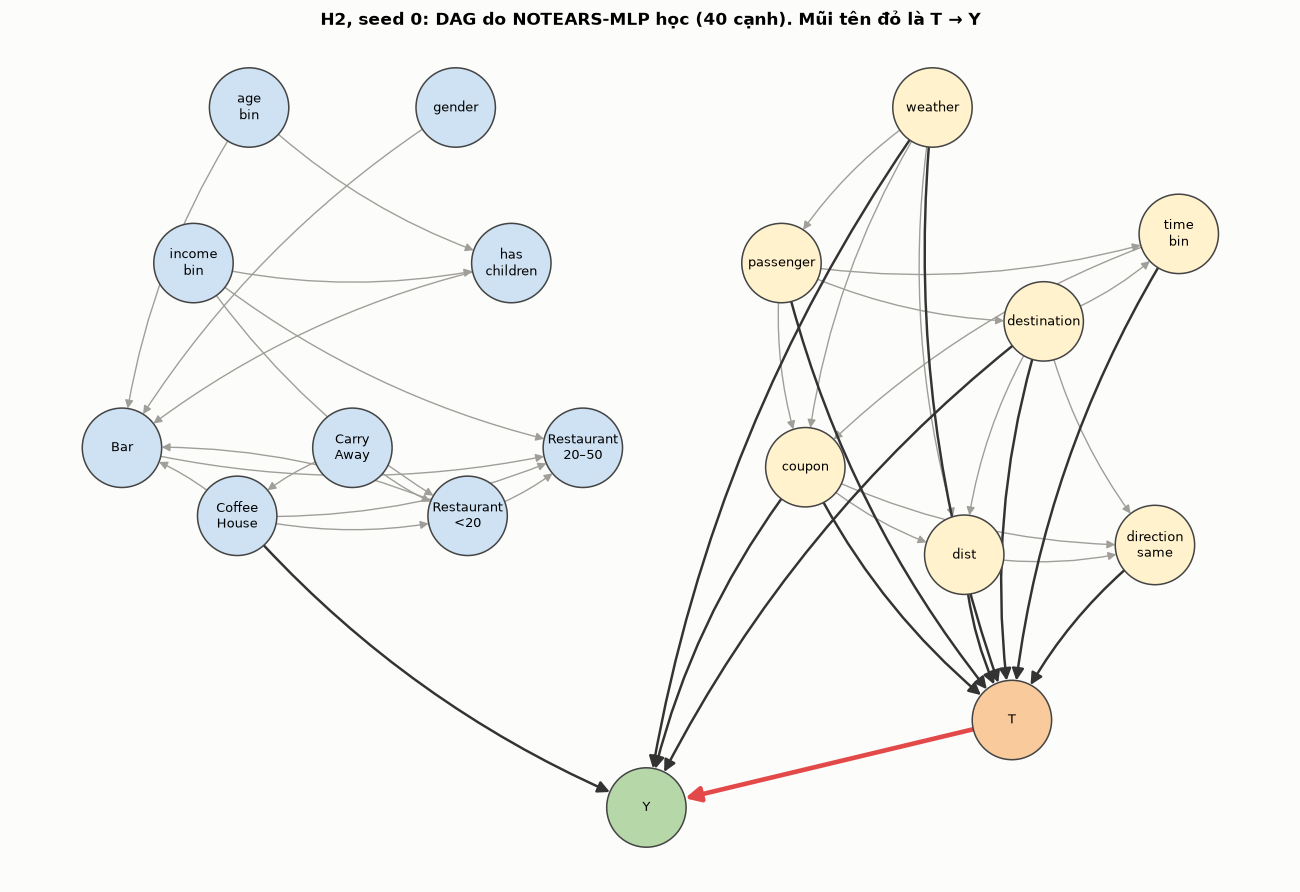

In [29]:
print(f"DAG của H2: {len(H2_0.edges)} cạnh | lỗi ràng buộc: {check_dag(H2_0.edges)} | NOTEARS tự tìm ra T → Y: {H2_0.info['found_TY']}")
print("Cha của Y:", ", ".join(sorted(H2_0.y_parents)))
print("Cha của T:", ", ".join(sorted(H2_0.bn.get_parents("T"))))
edges_b0, edges_h2 = set(B0_0.edges), set(H2_0.edges)
print(f"So với B0: {len(edges_b0 & edges_h2)} cạnh chung, {len(edges_b0 - edges_h2)} cạnh chỉ B0 có, {len(edges_h2 - edges_b0)} cạnh chỉ H2 có.")
draw_dag(H2_0.edges, f"H2, seed 0: DAG do NOTEARS-MLP học ({len(H2_0.edges)} cạnh). Mũi tên đỏ là T → Y")
plt.savefig(OUT / "dag_h2_seed0.png")

**So với DAG của B0.** H2 có 40 cạnh, B0 có 62: 29 cạnh chung, 33 cạnh chỉ B0 có, 11 cạnh chỉ H2 có. Hai cách học khác nhau nhiều ở phần nối các đặc điểm của người trả lời với nhau (B0 có 32 cạnh loại này, H2 có 15), nhưng giống nhau ở phần mà câu hỏi của bài cần: các biến kịch bản trỏ vào T, còn `coupon`, `destination`, `CoffeeHouse` và T trỏ vào Y. Trong 5 thói quen gốc, H2 cũng chỉ nối `CoffeeHouse` vào Y. Ở seed này H2 không giữ cạnh `has_children → passenger`, nên trong DAG của H2 nhóm người trả lời và nhóm kịch bản chỉ gặp nhau ở Y.

DAG đã khác B0 nên phải **nhận diện lại** bằng DoWhy

In [30]:
_, ESTIMAND_H2 = dowhy_identify(H2_0.edges, train0)
adjust_dowhy_h2 = sorted(ESTIMAND_H2.get_backdoor_variables())
adjust_model_h2 = sorted(p for p in H2_0.y_parents if p != "T")
print("H2, tập điều chỉnh DoWhy chọn  :", adjust_dowhy_h2, "| chặn hết cửa sau:", backdoor_ok(H2_0.edges, adjust_dowhy_h2))
print("H2, tập điều chỉnh mô hình dùng:", adjust_model_h2, "| chặn hết cửa sau:", backdoor_ok(H2_0.edges, adjust_model_h2))
print("B0, tập điều chỉnh (để so sánh) :", adjust_model)
print("Đối chiếu can thiệp với pgmpy cho H2: lệch lớn nhất =", f"{check_do_with_pgmpy(H2_0, test0)['lệch'].max():.1e}")
pd.DataFrame([summary_row(m, val0, test0) for m in (B0_0, H1_0, H2_0)]).set_index("mô hình").round(4)

H2, tập điều chỉnh DoWhy chọn  : ['coupon', 'destination', 'weather'] | chặn hết cửa sau: True
H2, tập điều chỉnh mô hình dùng: ['CoffeeHouse', 'coupon', 'destination', 'weather'] | chặn hết cửa sau: True
B0, tập điều chỉnh (để so sánh) : ['CoffeeHouse', 'coupon', 'destination', 'direction_same']
Đối chiếu can thiệp với pgmpy cho H2: lệch lớn nhất = 0.0e+00


,số cạnh,số cha của Y,số ô bảng Y,auroc,macro_f1,brier,log_loss,threshold,risk_1d,risk_2h,ate
mô hình,,,,,,,,,,,
B0,62,5,240,0.7339,0.6688,0.2045,0.6010,0.59,0.6363,0.4874,-0.1488
H1,62,5,240,0.7376,0.6658,0.2029,0.5922,0.59,0.6374,0.4871,-0.1503
H2,40,5,360,0.7286,0.6717,0.2072,0.6165,0.53,0.6311,0.4963,-0.1348


**Kết quả**

- DoWhy nhận diện lại được hiệu ứng trên DAG của H2. Tập của DoWhy là {`coupon`, `destination`, `weather`}, tập của mô hình là {`CoffeeHouse`, `coupon`, `destination`, `weather`}; cả hai đều chặn hết backdoor path. DoWhy không cần `CoffeeHouse` vì trong DAG này không có đường nào nối thói quen với T ngoài đường đi qua Y. Mô hình vẫn giữ `CoffeeHouse` vì nó là parent của Y.
- Y có 4 parents ngoài T nên bảng Y của H2 có 360 ô, gấp rưỡi bảng 240 ô của B0 (ở notebook 05, H2 chọn thêm `passenger` và bảng lên tới 1.440 ô). Dự đoán kém B0 một chút: AUROC 0,729 so với 0,734, log loss 0,617 so với 0,601.
- ATE của H2 là −0,135, gần 0 hơn B0 (−0,149) và H1 (−0,150). Ở seed này 13,5% dòng TEST phải dùng ít nhất một ô TRAIN trống khi can thiệp (B0: 2,9%): `weather` có hai mức ít dòng (Rainy, Snowy) nên nhiều tổ hợp không có dữ liệu. Ô trống có giá trị 0,5 ở cả hai loại hạn nên kéo hiệu về 0. Con số −0,135 vì thế cần đọc thận trọng hơn hai mô hình kia.

**Cách đọc kết quả.** Bảng cuối đặt ba mô hình cạnh nhau trên seed 0. Đây mới là **một** cách chia dữ liệu, nên chưa kết luận được mô hình nào hơn: chênh lệch nhỏ có thể chỉ do may rủi của lần chia. Mục 11 lặp lại toàn bộ cho 5 seed để xem chênh lệch nào **lặp lại** được.

<a id="11"></a>
## 11. Chạy 5 lần

**Mục tiêu.** Lặp lại quy trình của mục 8–10 cho cả 5 seed và thu mọi con số cần cho ba bảng kết quả.

Với mỗi seed (một cách chia dữ liệu), hàm `run_seed` làm 6 việc:

| Việc | Hàm | Dùng cho |
|---|---|---|
| 1. Học B0, H1, H2 trên TRAIN và VALIDATION | `build_b0`, `build_h1`, `build_h2` | mọi bảng |
| 2. Chấm dự đoán Y trên TEST | `evaluate_prediction` | Bảng A |
| 3. Tính ATE trên nhóm TEST | `ate_from_table` | Bảng B |
| 4. Bootstrap để có CI 95% của ATE | `bootstrap_ate` | Bảng B |
| 5. DoWhy: nhận diện, ước lượng tham chiếu, 2 refuter | `dowhy_report` | Bảng B, C |
| 6. Thử placebo trên chính mô hình | `placebo_ate` | Bảng C |

**Bootstrap là gì?** Ta chỉ có một bộ dữ liệu. Nếu làm lại khảo sát với nhóm người khác thì ATE sẽ khác đi một chút, nhưng khác bao nhiêu? Bootstrap giả lập việc "làm lại khảo sát": rút ngẫu nhiên **có hoàn lại** đúng bằng số người của TRAIN (có người được rút hai lần, có người không được rút), học lại bảng Y trên mẫu đó, tính lại ATE. Lặp 100 lần được 100 con số ATE. Khoảng chứa 95% số ở giữa (từ phân vị 2,5% đến 97,5%) là **95% confidence interval (CI 95%)**. Theo đề bài: rút theo **người** (vì các dòng của một người không độc lập, giả định G6), **giữ nguyên DAG** và **giữ nguyên nhóm TEST**. CI này vì thế đo độ bất định của CPD, không đo độ bất định của việc tìm DAG.

**Refuter là gì?** Là phép thử "cố tình phá" để xem ước lượng có phản ứng đúng không. Đề bài yêu cầu ít nhất hai phép thử của DoWhy:

- **Placebo treatment:** thay cột T thật bằng một cột T **bị xáo trộn ngẫu nhiên** (không còn liên quan gì đến Y). Hiệu ứng tính lại phải **xấp xỉ 0**. Nếu vẫn ra hiệu ứng lớn thì phương pháp đang "bịa" ra hiệu ứng.
- **Data subset:** bỏ ngẫu nhiên 20% dữ liệu rồi ước lượng lại. Hiệu ứng phải **gần như không đổi**. Nếu đổi nhiều thì kết quả phụ thuộc vào vài dòng cá biệt.

Hai phép thử của DoWhy chạy trên **ước lượng của DoWhy** (hồi quy tuyến tính của Y theo T và adjustment set mà DoWhy tìm được trên DAG đó). Để thử trực tiếp ba mô hình của ta, `placebo_ate` làm phép thử placebo tương tự bằng chính bảng Y của từng mô hình.

**Ghi chú kỹ thuật.** Ô chạy chính đặt `torch.set_num_threads(1)`: các mạng ở đây rất nhỏ nên một luồng là đủ, và tránh được chi phí điều phối nhiều luồng.

In [31]:
def refit_y_table(model: Model, data: pd.DataFrame, val: pd.DataFrame, seed: int) -> pd.DataFrame:
    """Học lại RIÊNG bảng Y của một mô hình trên một bộ dữ liệu khác, giữ nguyên DAG (dùng cho bootstrap và placebo).

    Tham số: model — mô hình gốc; data — bộ dữ liệu thay cho TRAIN; val — VALIDATION (H1 cần để dừng sớm); seed — hạt giống của MLP.
    Trả về: "bảng Y" mới, cùng dạng với model.y_table.
    """
    if model.name == "H1":                                   # H1: huấn luyện lại MLP
        net, _ = train_mlp(onehot(data, model.y_parents), as_int(data["Y"]), onehot(val, model.y_parents), as_int(val["Y"]), seed)
        return mlp_y_table(net, model.y_parents)
    estimator = BayesianEstimator(model.bn, data[NODES], state_names=STATES)     # B0 và H2: đếm lại + BDeu
    return cpd_to_y_table(estimator.estimate_cpd("Y", prior_type="BDeu", equivalent_sample_size=CFG.ess))


def bootstrap_ate(model: Model, train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame, seed: int) -> np.ndarray:
    """Bootstrap theo người: rút lại người của TRAIN, học lại bảng Y, tính lại ATE trên TEST.

    Tham số: model — mô hình gốc (DAG giữ nguyên); train, val, test — dữ liệu của seed; seed — hạt giống.
    Trả về: mảng CFG.n_boot giá trị ATE. Ba mô hình của cùng seed nhận đúng cùng các mẫu bootstrap.
    """
    rng = np.random.default_rng(seed)
    people = train["resp_id"].unique()
    rows_of = train.groupby("resp_id").indices             # mã người → vị trí các dòng của người đó trong TRAIN
    ates = []
    for _ in range(CFG.n_boot):
        drawn = rng.choice(people, size=len(people), replace=True)               # rút người, có hoàn lại
        boot = train.iloc[np.concatenate([rows_of[person] for person in drawn])].reset_index(drop=True)
        ates.append(ate_from_table(refit_y_table(model, boot, val, seed), test)["ate"])
    return np.array(ates)


def placebo_ate(model: Model, train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame, seed: int) -> np.ndarray:
    """Placebo trên chính mô hình: xáo trộn cột T của TRAIN, học lại bảng Y, tính lại ATE (kỳ vọng xấp xỉ 0).

    Tham số: như bootstrap_ate().
    Trả về: mảng CFG.n_placebo giá trị ATE giả.
    """
    rng = np.random.default_rng(1000 + seed)
    ates = []
    for _ in range(CFG.n_placebo):
        fake = train.copy()
        fake["T"] = rng.permutation(fake["T"].to_numpy())  # T giả: giữ đủ số coupon 2 giờ nhưng gán bừa cho các dòng
        fake_val = val.copy()
        fake_val["T"] = rng.permutation(fake_val["T"].to_numpy())
        ates.append(ate_from_table(refit_y_table(model, fake, fake_val, seed), test)["ate"])
    return np.array(ates)


def dowhy_report(edges: list[tuple[str, str]], train: pd.DataFrame, seed: int) -> dict:
    """Chạy trọn bộ DoWhy cho một DAG: nhận diện → ước lượng tham chiếu → hai refuter.

    Tham số: edges — các mũi tên của DAG; train — TRAIN; seed — hạt giống của refuter.
    Trả về: dict gồm tập điều chỉnh, văn bản nhận diện, ATE tham chiếu và kết quả hai refuter (hiệu ứng mới, p-value).
    """
    model, estimand = dowhy_identify(edges, train)
    # Ước lượng tham chiếu: hồi quy tuyến tính của Y theo T và tập điều chỉnh; hệ số của T chính là ATE.
    # need_conditional_estimates=False: tắt một nhánh tính phụ của DoWhy bị lỗi với pandas 3.
    estimate = model.estimate_effect(estimand, method_name="backdoor.linear_regression", control_value=0, treatment_value=1,
                                     target_units="ate", method_params={"need_conditional_estimates": False})
    placebo = model.refute_estimate(estimand, estimate, method_name="placebo_treatment_refuter", placebo_type="permute",
                                    num_simulations=CFG.n_refute, random_seed=seed)
    subset = model.refute_estimate(estimand, estimate, method_name="data_subset_refuter", subset_fraction=CFG.subset_fraction,
                                   num_simulations=CFG.n_refute, random_seed=seed)
    return {"adjust": sorted(estimand.get_backdoor_variables()), "text": str(estimand), "ate": float(estimate.value),
            "placebo_effect": float(placebo.new_effect), "placebo_p": float(placebo.refutation_result["p_value"]),
            "subset_effect": float(subset.new_effect), "subset_p": float(subset.refutation_result["p_value"])}


def save_artifacts(seed: int, models: list[Model], reports: dict) -> None:
    """Lưu mọi thứ đề bài yêu cầu cho một seed: cạnh DAG, bảng Y, checkpoint MLP, ma trận độ mạnh, văn bản nhận diện.

    Tham số: seed — seed vừa chạy; models — [B0, H1, H2]; reports — kết quả dowhy_report() theo tên mô hình.
    """
    for model in models:
        tag = f"{model.name.lower()}_seed{seed}"
        json.dump([list(edge) for edge in model.edges], open(OUT / f"edges_{tag}.json", "w"))
        model.y_table.to_csv(OUT / f"cpd_y_{tag}.csv", index=False)
        if model.name == "B0":
            model.info["ranking"].to_csv(OUT / f"b0_candidates_seed{seed}.csv", index=False)
        if model.name == "H1":
            torch.save(model.info["net"].state_dict(), OUT / f"h1_seed{seed}.pt")
        if model.name == "H2":
            pd.DataFrame(model.info["A"], index=NODES, columns=NODES).to_csv(OUT / f"h2_adjacency_seed{seed}.csv")
            model.info["ranking"].to_csv(OUT / f"h2_thresholds_seed{seed}.csv", index=False)
        if model.name != "H1":                               # H1 dùng chung DAG với B0 nên dùng chung văn bản nhận diện
            (OUT / f"identification_{tag}.txt").write_text(reports[model.name]["text"], encoding="utf-8")


def run_seed(seed: int) -> list[dict]:
    """Chạy toàn bộ quy trình cho một seed.

    Tham số: seed — một seed trong CFG.seeds.
    Trả về: 3 dict (B0, H1, H2), mỗi dict là một dòng của bảng kết quả thô RUNS.
    """
    set_seed(seed)
    train, val, test = get_split(df, SPLITS[seed])
    # ----- 1. Học ba mô hình trên CÙNG dữ liệu -----
    b0 = build_b0(train, val)
    h1 = build_h1(b0, train, val, seed)
    h2 = build_h2(train, val, seed)
    notes = {"B0": b0.info["chosen"], "H1": f"MLP {h1.info['n_params']} trọng số, {len(h1.info['history'])} lượt học",
             "H2": f"{h2.info['chosen']}, tự tìm T → Y: {h2.info['found_TY']}"}
    # ----- 5. DoWhy cho từng DAG (H1 dùng chung DAG với B0) -----
    reports = {"B0": dowhy_report(b0.edges, train, seed)}
    reports["H1"] = reports["B0"]
    reports["H2"] = dowhy_report(h2.edges, train, seed)
    naive = naive_difference(train)["diff"]
    rows = []
    for model in (b0, h1, h2):
        row = {"seed": seed, "model": model.name, "config": notes[model.name], "n_edges": len(model.edges),
               "y_parents": ", ".join(sorted(model.y_parents)), "t_parents": ", ".join(sorted(model.bn.get_parents("T"))),
               "dag_valid": check_dag(model.edges) == [], "fit_seconds": model.fit_seconds}
        row.update(evaluate_prediction(model, val, test))                        # 2. dự đoán
        start = time.time()
        row.update(ate_from_table(model.y_table, test))                          # 3. can thiệp
        row["query_ms"] = 1000 * (time.time() - start)
        counts = train.groupby(model.y_parents).size().rename("n").reset_index()
        unsupported = []
        for arm in ("0", "1"):
            query = test[model.y_parents].copy()
            query["T"] = arm
            unsupported.append(query.merge(counts, on=model.y_parents, how="left")["n"].fillna(0).eq(0).to_numpy())
        row["unsupported_test_fraction"] = float(np.mean(unsupported[0] | unsupported[1]))
        boot = bootstrap_ate(model, train, val, test, seed)                      # 4. bootstrap
        row["ci_low"], row["ci_high"], row["boot_sd"] = float(np.quantile(boot, 0.025)), float(np.quantile(boot, 0.975)), float(boot.std(ddof=1))
        adjust = sorted(p for p in model.y_parents if p != "T")
        report = reports[model.name]
        row.update({"adjust_model": ", ".join(adjust), "adjust_ok": backdoor_ok(model.edges, adjust),
                    "adjust_dowhy": ", ".join(report["adjust"]), "ate_dowhy": report["ate"], "naive_train": naive,
                    "dowhy_placebo": report["placebo_effect"], "dowhy_placebo_p": report["placebo_p"],
                    "dowhy_subset": report["subset_effect"], "dowhy_subset_p": report["subset_p"]})
        placebo = placebo_ate(model, train, val, test, seed)                     # 6. placebo trên mô hình
        row["bn_placebo_mean"], row["bn_placebo_max_abs"] = float(placebo.mean()), float(np.abs(placebo).max())
        row["do_check_max_gap"] = float(check_do_with_pgmpy(model, test)["lệch"].max())
        rows.append(row)
    save_artifacts(seed, [b0, h1, h2], reports)
    return rows


torch.set_num_threads(1)      # mạng ở đây rất nhỏ: một luồng là đủ, tránh tốn công điều phối nhiều luồng
start_all = time.time()
all_rows = []
for seed in CFG.seeds:
    start = time.time()
    all_rows += run_seed(seed)
    print(f"seed {seed}: xong sau {time.time() - start:.0f} giây")
RUNS = pd.DataFrame(all_rows)
RUNS.to_csv(OUT / "runs_raw.csv", index=False)
json.dump({"config": asdict(CFG), "quick": QUICK, "tiers": TIERS, "layers": LAYERS, "allowed_parents": ALLOWED_PARENTS, "required_edges": REQUIRED,
           "n_forbidden_edges": len(FORBIDDEN),
           "source": SOURCE, "env": ENV}, open(OUT / "config.json", "w"), ensure_ascii=False, indent=1)
print(f"Tổng thời gian {len(CFG.seeds)} seed: {(time.time() - start_all) / 60:.1f} phút.")
print(f"Mọi DAG hợp lệ: {bool(RUNS['dag_valid'].all())} | mọi tập điều chỉnh chặn hết cửa sau: {bool(RUNS['adjust_ok'].all())} | "
      f"lệch lớn nhất giữa tra bảng và pgmpy do(): {RUNS['do_check_max_gap'].max():.1e}")
with pd.option_context("display.max_colwidth", 80):
    display(RUNS[["seed", "model", "config", "n_edges", "y_parents", "t_parents"]])

seed 0: xong sau 110 giây


seed 1: xong sau 74 giây


seed 2: xong sau 118 giây


seed 3: xong sau 112 giây


seed 4: xong sau 101 giây
Tổng thời gian 5 seed: 8.6 phút.
Mọi DAG hợp lệ: True | mọi tập điều chỉnh chặn hết cửa sau: True | lệch lớn nhất giữa tra bảng và pgmpy do(): 1.1e-16


,seed,model,config,n_edges,y_parents,t_parents
0,0,B0,"HC k2, tối đa 6 cha",62,"CoffeeHouse, T, coupon, destination, direction_same","coupon, destination, dist, passenger, time_bin, weather"
1,0,H1,"MLP 1089 trọng số, 79 lượt học",62,"CoffeeHouse, T, coupon, destination, direction_same","coupon, destination, dist, passenger, time_bin, weather"
2,0,H2,"ngưỡng 0.15, tự tìm T → Y: True",40,"CoffeeHouse, T, coupon, destination, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather"
3,1,B0,"HC k2, tối đa 6 cha",62,"CoffeeHouse, T, coupon, destination, direction_same","coupon, destination, dist, passenger, time_bin, weather"
4,1,H1,"MLP 1089 trọng số, 37 lượt học",62,"CoffeeHouse, T, coupon, destination, direction_same","coupon, destination, dist, passenger, time_bin, weather"
5,1,H2,"ngưỡng 0.15, tự tìm T → Y: True",37,"CoffeeHouse, T, coupon, destination, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather"
6,2,B0,"HC k2, tối đa 4 cha",51,"CoffeeHouse, T, coupon, destination","coupon, destination, dist, weather"
7,2,H1,"MLP 1025 trọng số, 40 lượt học",51,"CoffeeHouse, T, coupon, destination","coupon, destination, dist, weather"
8,2,H2,"ngưỡng 0.15, tự tìm T → Y: True",43,"CoffeeHouse, T, coupon, destination, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather"
9,3,B0,"HC bic-d, tối đa 4 cha",47,"CoffeeHouse, T, coupon","coupon, destination, dist, weather"


**Cách đọc kết quả.** Mỗi seed cho 3 dòng (B0, H1, H2). Cột `config` ghi cấu hình được VALIDATION chọn. So `y_parents` giữa các seed để thấy parent set của Y có ổn định không, và so `t_parents` giữa B0 với H2 để thấy hai cách học DAG có đồng ý về "cái gì quyết định hạn coupon" không. Ba dòng kiểm tra phía trên bảng phải cho `True`, `True` và một độ lệch xấp xỉ 0.

**Kết quả của lần chạy này.**

- Cả 15 mô hình (3 mô hình × 5 seed) đều qua `check_dag` với bộ luật mới, mọi adjustment set đều chặn hết backdoor path, và "ép T rồi tra bảng" trùng với `do()` của pgmpy (lệch cỡ 10⁻¹⁶, tức sai số làm tròn của máy).
- **B0:** VALIDATION chọn hàm điểm K2 ở 4/5 seed (tối đa 6 parents ở seed 0 và 1, tối đa 4 parents ở seed 2 và 4) và BIC ở seed 3. Y luôn có parents `T`, `coupon`, `CoffeeHouse`; `destination` có thêm ở 4/5 seed, `direction_same` ở 2/5 seed. Cấu hình được chọn, parents của Y và parents của T **trùng với notebook 05 ở cả 5 seed**; chỉ số cạnh giảm (47–62 so với 48–74) vì các cạnh bị cấm đã bị loại.
- **H2:** ngưỡng 0,15 được chọn ở seed 0–3 và ngưỡng 0,10 ở seed 4. NOTEARS **tự tìm ra** cạnh T → Y ở cả 5 seed. Y có **cùng một** parent set ở cả 5 seed: `T`, `coupon`, `CoffeeHouse`, `destination`, `weather` (ở notebook 05, H2 cho 4 parent set khác nhau).
- **Thói quen:** trong 5 thói quen gốc, chỉ `CoffeeHouse` trở thành parent của Y, và nó có mặt ở **cả 15** mô hình. Không có thói quen nào trỏ vào T (luật 8 cấm) hay vào biến kịch bản (luật 3, 4, 5, 7 cấm).
- **Parents của T:** H2 giữ đủ 7 biến kịch bản ở cả 5 seed. B0 giữ 6 biến ở seed 0, 1 và 4 biến (`coupon`, `destination`, `dist`, `weather`) ở ba seed còn lại. Hai cách học DAG đồng ý rằng hạn coupon gắn với kịch bản.
- **Cạnh bắc cầu:** `has_children → passenger` có mặt ở cả 5 DAG của B0 và ở 3/5 DAG của H2 (seed 2, 3, 4). Ngoài cạnh này và các cạnh vào Y, không DAG nào nối nhóm người trả lời với nhóm kịch bản.


<a id="12"></a>
## 12. Bảng A: dự đoán

**Mục tiêu.** So khả năng **dự đoán Y** của ba mô hình trên TEST (ôn lại ý nghĩa 4 chỉ số ở mục 8.4).

**Cách so sánh.** Ba mô hình của cùng một seed dùng chung dữ liệu, nên so theo **cặp**: lấy chỉ số của H1 (hoặc H2) trừ chỉ số của B0 **trong từng seed**, rồi nhìn 5 hiệu đó. Cách này loại được phần may rủi do cách chia dữ liệu, vì cả hai mô hình cùng hưởng một "đề dễ" hay cùng chịu một "đề khó".

In [32]:
def mean_sd_table(runs: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Tóm tắt qua các seed: trung bình ± độ lệch chuẩn của từng cột, cho từng mô hình.

    Tham số: runs — bảng kết quả thô; columns — các cột số cần tóm tắt.
    Trả về: bảng 3 dòng (B0, H1, H2), mỗi ô là chuỗi "trung bình ± độ lệch chuẩn".
    """
    rows = []
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name]
        row = {"mô hình": name}
        for col in columns:
            row[col] = f"{part[col].mean():.4f} ± {part[col].std(ddof=1):.4f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("mô hình")


def paired_differences(runs: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Hiệu theo cặp cùng seed: H1 − B0 và H2 − B0 cho từng cột.

    Tham số: runs — bảng kết quả thô; columns — các cột số cần so.
    Trả về: bảng mỗi dòng là một (cột, phép so), gồm hiệu trung bình, độ lệch chuẩn của hiệu, hiệu nhỏ nhất, lớn nhất
            và số seed có hiệu dương.
    """
    rows = []
    for col in columns:
        wide = runs.pivot(index="seed", columns="model", values=col)       # mỗi dòng một seed, mỗi cột một mô hình
        for other in ("H1", "H2"):
            diff = wide[other] - wide["B0"]
            rows.append({"chỉ số": col, "so sánh": f"{other} − B0", "hiệu trung bình": diff.mean(), "độ lệch chuẩn": diff.std(ddof=1),
                         "nhỏ nhất": diff.min(), "lớn nhất": diff.max(), "số seed hiệu > 0": f"{int((diff > 0).sum())}/{len(diff)}"})
    return pd.DataFrame(rows)


METRICS = ["auroc", "macro_f1", "brier", "log_loss"]
TABLE_A = RUNS[["seed", "model"] + METRICS + ["threshold"]]
TABLE_A.to_csv(OUT / "table_A.csv", index=False)
TABLE_A_MEAN = mean_sd_table(RUNS, METRICS)
TABLE_A_PAIRED = paired_differences(RUNS, METRICS)
TABLE_A_MEAN.to_csv(OUT / "table_A_mean_sd.csv")
TABLE_A_PAIRED.to_csv(OUT / "table_A_paired.csv", index=False)
print("Bảng A.1: từng lần chạy (mỗi seed một dòng, mỗi mô hình một nhóm cột)")
display(RUNS.pivot(index="seed", columns="model", values=METRICS).round(4))
print("Bảng A.2: trung bình ± độ lệch chuẩn qua các seed")
display(TABLE_A_MEAN)
print("Bảng A.3: hiệu theo cặp (cùng seed) so với B0")
display(TABLE_A_PAIRED.round(4))

Bảng A.1: từng lần chạy (mỗi seed một dòng, mỗi mô hình một nhóm cột)


auroc                 macro_f1                   brier                 log_loss                
model      B0      H1      H2       B0      H1      H2      B0      H1      H2       B0      H1      H2
seed                                                                                                   
0      0.7339  0.7376  0.7286   0.6688  0.6658  0.6717  0.2045  0.2029  0.2072   0.6010  0.5922  0.6165
1      0.7284  0.7358  0.7309   0.6842  0.6828  0.6796  0.2075  0.2048  0.2079   0.6163  0.5979  0.6222
2      0.7177  0.7260  0.7226   0.6609  0.6685  0.6701  0.2091  0.2061  0.2098   0.6123  0.5995  0.6313
3      0.6920  0.6913  0.7240   0.6329  0.6381  0.6646  0.2181  0.2177  0.2087   0.6250  0.6241  0.6112
4      0.7562  0.7639  0.7603   0.6983  0.7059  0.7049  0.1973  0.1956  0.1971   0.5876  0.5769  0.6020

Bảng A.2: trung bình ± độ lệch chuẩn qua các seed


,auroc,macro_f1,brier,log_loss
mô hình,,,,
B0,0.7257 ± 0.0235,0.6690 ± 0.0248,0.2073 ± 0.0076,0.6084 ± 0.0145
H1,0.7309 ± 0.0262,0.6722 ± 0.0248,0.2054 ± 0.0079,0.5981 ± 0.0171
H2,0.7333 ± 0.0155,0.6782 ± 0.0159,0.2061 ± 0.0051,0.6166 ± 0.0111


Bảng A.3: hiệu theo cặp (cùng seed) so với B0


,chỉ số,so sánh,hiệu trung bình,độ lệch chuẩn,nhỏ nhất,lớn nhất,số seed hiệu > 0
0,auroc,H1 − B0,0.0053,0.0038,-0.0007,0.0083,4/5
1,auroc,H2 − B0,0.0076,0.0142,-0.0053,0.0319,4/5
2,macro_f1,H1 − B0,0.0032,0.0050,-0.0030,0.0076,3/5
3,macro_f1,H2 − B0,0.0092,0.0136,-0.0046,0.0317,4/5
4,brier,H1 − B0,-0.0019,0.0010,-0.0030,-0.0004,0/5
5,brier,H2 − B0,-0.0012,0.0047,-0.0094,0.0027,3/5
6,log_loss,H1 − B0,-0.0103,0.0064,-0.0184,-0.0008,0/5
7,log_loss,H2 − B0,0.0082,0.0132,-0.0138,0.0191,4/5


**Cách đọc bảng.**

- *A.1:* đọc theo hàng ngang để so ba mô hình trong cùng một seed.
- *A.2:* `0,7300 ± 0,0100` nghĩa là trung bình 5 seed là 0,73 và các seed dao động quanh đó khoảng 0,01.
- *A.3:* với AUROC và macro-F1, hiệu **dương** là tốt hơn B0; với Brier và log loss, hiệu **âm** là tốt hơn B0. Một khác biệt đáng tin khi (a) cùng dấu ở hầu hết các seed (cột cuối là 0/5 hoặc 5/5) và (b) hiệu trung bình lớn hơn hẳn độ lệch chuẩn của nó. Chỉ có 5 lần chạy nên đây là bằng chứng mô tả, không phải kiểm định thống kê.

**Kết quả của lần chạy này.**

- Ba mô hình xếp hạng **gần như ngang nhau**: AUROC trung bình 0,726 (B0), 0,731 (H1), 0,733 (H2). Về log loss thì có khác: 0,608 (B0), 0,598 (H1), 0,617 (H2).
- **H1 so với B0:** log loss và Brier của H1 thấp hơn ở cả 5/5 seed (log loss trung bình −0,010, độ lệch chuẩn 0,006), AUROC cao hơn ở 4/5 seed (+0,005). Mức hơn nhỏ nhưng cùng chiều; riêng seed 3 hai mô hình gần như bằng nhau. Kết luận thận trọng: MLP cho xác suất sát hơn một chút, chưa đủ để nói là hơn hẳn. Các con số của B0 và H1 trùng với notebook 05, vì bộ luật mới không làm đổi parents của Y ở B0.
- **H2 so với B0:** AUROC cao hơn ở 4/5 seed (trung bình +0,008), nhưng phần lớn mức hơn đến từ seed 3 (+0,032), nơi B0 chỉ cho Y hai parents ngoài T; ở seed 0 H2 kém B0 (−0,005). Log loss thì ngược lại: kém B0 ở 4/5 seed (trung bình +0,008), chỉ hơn ở seed 3 (−0,014). Tức H2 xếp hạng ngang hoặc nhỉnh hơn, nhưng xác suất kém chính xác hơn vì bảng Y 360 ô có nhiều ô ít dữ liệu.
- Chênh lệch **giữa các seed** (độ lệch chuẩn của AUROC từ 0,016 đến 0,026) lớn hơn chênh lệch **giữa các mô hình** (0,005 đến 0,008). Nếu chỉ chạy một seed thì rất dễ kết luận nhầm. Đó là lý do đề bài yêu cầu ít nhất 5 lần chạy theo cặp.


<a id="13"></a>
## 13. Bảng B: intervention

**Mục tiêu.** Trả lời câu hỏi của bài: tỉ lệ chấp nhận nếu mọi coupon hạn 1 ngày, nếu mọi coupon hạn 2 giờ, và hiệu của chúng (ATE), kèm CI 95%.

Các cột của bảng:

| Cột | Nghĩa |
|---|---|
| `risk_1d`, `risk_2h` | P(Y = 1 khi do(T = 1 ngày)), P(Y = 1 khi do(T = 2 giờ)), tính trên nhóm TEST |
| `ate` | `risk_2h − risk_1d` |
| `ci_low`, `ci_high` | CI 95% của ATE (bootstrap theo người, DAG cố định) |
| `adjust_model` | adjustment set mô hình dùng = parents của Y trừ T |
| `adjust_dowhy` | adjustment set DoWhy tìm được trên cùng DAG |
| `ate_dowhy` | ATE tham chiếu của DoWhy (hồi quy tuyến tính với `adjust_dowhy`), độc lập với Bayesian Network |
| `naive_train` | hiệu thô trên TRAIN, chưa điều chỉnh (mục 5.1) |

In [33]:
EFFECT_COLS = ["risk_1d", "risk_2h", "ate", "ci_low", "ci_high"]
TABLE_B = RUNS[["seed", "model"] + EFFECT_COLS + ["adjust_model", "adjust_dowhy", "ate_dowhy", "naive_train"]]
TABLE_B.to_csv(OUT / "table_B.csv", index=False)
TABLE_B_MEAN = mean_sd_table(RUNS, ["risk_1d", "risk_2h", "ate", "ci_low", "ci_high", "ate_dowhy", "naive_train"])
TABLE_B_PAIRED = paired_differences(RUNS, ["ate"])
TABLE_B_MEAN.to_csv(OUT / "table_B_mean_sd.csv")
print("Bảng B.1: từng lần chạy")
with pd.option_context("display.max_colwidth", 70):
    display(TABLE_B.round(4))
print("Bảng B.2: trung bình ± độ lệch chuẩn qua các seed")
display(TABLE_B_MEAN)
print("Bảng B.3: hiệu ATE theo cặp (cùng seed) so với B0")
display(TABLE_B_PAIRED.round(4))

Bảng B.1: từng lần chạy


,seed,model,risk_1d,risk_2h,ate,ci_low,ci_high,adjust_model,adjust_dowhy,ate_dowhy,naive_train
0,0,B0,0.6363,0.4874,-0.1488,-0.1699,-0.1225,"CoffeeHouse, coupon, destination, direction_same","coupon, destination, direction_same, has_children",-0.1578,-0.1368
1,0,H1,0.6374,0.4871,-0.1503,-0.1682,-0.1271,"CoffeeHouse, coupon, destination, direction_same","coupon, destination, direction_same, has_children",-0.1578,-0.1368
2,0,H2,0.6311,0.4963,-0.1348,-0.1616,-0.1078,"CoffeeHouse, coupon, destination, weather","coupon, destination, weather",-0.1594,-0.1368
3,1,B0,0.6387,0.4890,-0.1497,-0.1694,-0.1309,"CoffeeHouse, coupon, destination, direction_same","coupon, destination, direction_same, has_children",-0.1657,-0.1464
4,1,H1,0.6474,0.4896,-0.1578,-0.1749,-0.1411,"CoffeeHouse, coupon, destination, direction_same","coupon, destination, direction_same, has_children",-0.1657,-0.1464
5,1,H2,0.6324,0.4876,-0.1449,-0.1609,-0.1260,"CoffeeHouse, coupon, destination, weather","coupon, destination, weather",-0.1664,-0.1464
6,2,B0,0.6529,0.4944,-0.1584,-0.1770,-0.1317,"CoffeeHouse, coupon, destination","coupon, destination, weather",-0.1623,-0.1444
7,2,H1,0.6642,0.5080,-0.1562,-0.1780,-0.1334,"CoffeeHouse, coupon, destination","coupon, destination, weather",-0.1623,-0.1444
8,2,H2,0.6481,0.5015,-0.1466,-0.1641,-0.1194,"CoffeeHouse, coupon, destination, weather","coupon, destination, has_children, weather",-0.1613,-0.1444
9,3,B0,0.6360,0.4772,-0.1588,-0.1817,-0.1377,"CoffeeHouse, coupon","coupon, has_children",-0.1624,-0.1508


Bảng B.2: trung bình ± độ lệch chuẩn qua các seed


,risk_1d,risk_2h,ate,ci_low,ci_high,ate_dowhy,naive_train
mô hình,,,,,,,
B0,0.6443 ± 0.0102,0.4870 ± 0.0062,-0.1573 ± 0.0089,-0.1774 ± 0.0083,-0.1340 ± 0.0091,-0.1641 ± 0.0054,-0.1464 ± 0.0065
H1,0.6453 ± 0.0138,0.4903 ± 0.0114,-0.1550 ± 0.0040,-0.1735 ± 0.0041,-0.1323 ± 0.0054,-0.1641 ± 0.0054,-0.1464 ± 0.0065
H2,0.6392 ± 0.0087,0.4917 ± 0.0075,-0.1475 ± 0.0089,-0.1674 ± 0.0073,-0.1236 ± 0.0104,-0.1653 ± 0.0049,-0.1464 ± 0.0065


Bảng B.3: hiệu ATE theo cặp (cùng seed) so với B0


,chỉ số,so sánh,hiệu trung bình,độ lệch chuẩn,nhỏ nhất,lớn nhất,số seed hiệu > 0
0,ate,H1 − B0,0.0023,0.0077,-0.0082,0.0116,3/5
1,ate,H2 − B0,0.0098,0.0042,0.0048,0.0140,5/5


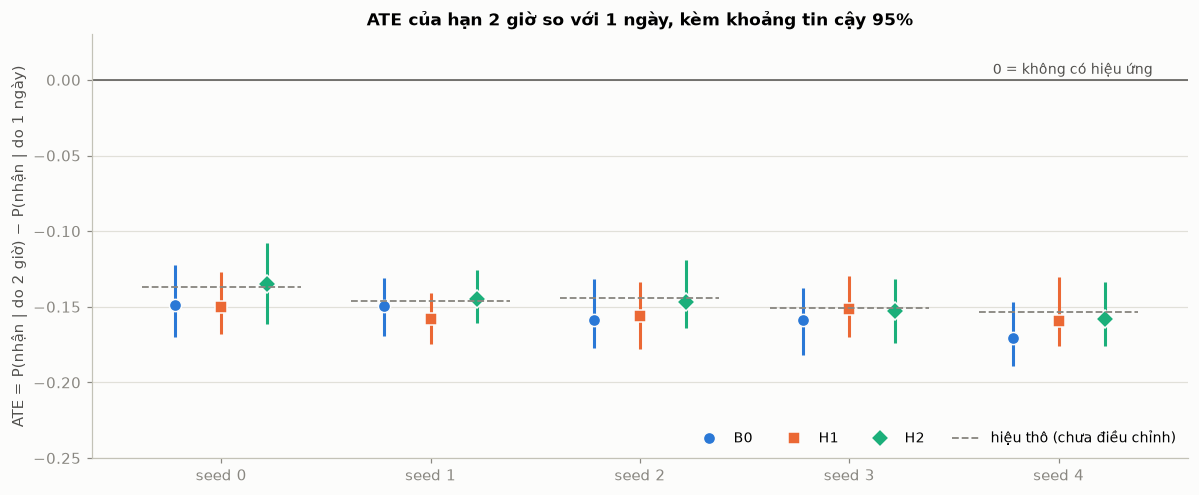

In [34]:
def plot_ate(runs: pd.DataFrame) -> None:
    """Vẽ ATE của ba mô hình ở từng seed, kèm khoảng tin cậy 95%; đường xám là hiệu thô chưa điều chỉnh.

    Tham số: runs — bảng kết quả thô.
    """
    seeds = sorted(runs["seed"].unique())
    offsets = {"B0": -0.22, "H1": 0.0, "H2": 0.22}            # đặt ba mô hình lệch nhau một chút để không đè lên nhau
    fig, ax = plt.subplots(figsize=(11, 4.6))
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name].set_index("seed").loc[seeds]
        x = np.arange(len(seeds)) + offsets[name]
        ax.vlines(x, part["ci_low"], part["ci_high"], color=COLOR[name], linewidth=2)            # thanh dọc = CI 95%
        ax.plot(x, part["ate"], MARKER[name], color=COLOR[name], markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=1, label=name)
    naive = runs.groupby("seed")["naive_train"].first().loc[seeds].to_numpy()
    ax.hlines(naive, np.arange(len(seeds)) - 0.38, np.arange(len(seeds)) + 0.38, color=MUTED, linewidth=1.2, linestyle="--", label="hiệu thô (chưa điều chỉnh)")
    ax.axhline(0, color=INK_SOFT, linewidth=1)
    ax.text(len(seeds) - 0.55, 0.004, "0 = không có hiệu ứng", color=INK_SOFT, ha="right", fontsize=9)
    ax.set_xticks(np.arange(len(seeds)))
    ax.set_xticklabels([f"seed {s}" for s in seeds])
    ax.set_ylabel("ATE = P(nhận | do 2 giờ) − P(nhận | do 1 ngày)")
    ax.set_title("ATE của hạn 2 giờ so với 1 ngày, kèm khoảng tin cậy 95%")
    ax.set_ylim(min(-0.25, float(runs["ci_low"].min()) - 0.02), 0.03)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower right", ncol=4, fontsize=9)
    fig.tight_layout()
    fig.savefig(OUT / "ate_by_seed.png")


plot_ate(RUNS)


- Mỗi chấm là ATE của một mô hình ở một seed; thanh dọc là CI 95%. Thanh **không chạm vạch 0** nghĩa là khoảng tin cậy không chứa 0.
- Ba chấm của cùng một seed nằm gần nhau và các thanh chồng lên nhau nghĩa là ba mô hình cho kết quả nhất quán.
- Vạch xám đứt là hiệu thô trên TRAIN.
- `ate_dowhy` là một ước lượng độc lập (hồi quy tuyến tính thay cho Bayesian Network), dùng để đối chiếu.

**Kết quả của lần chạy này.**

- Nếu mọi coupon có hạn 1 ngày, khoảng **64%** được chấp nhận. Nếu mọi coupon có hạn 2 giờ, chỉ còn khoảng **49%**. ATE trung bình là −0,157 (B0), −0,155 (H1) và −0,148 (H2).
- **Cả 15 CI 95% đều nằm hẳn dưới 0.** Với B0, đầu mút CI trung bình qua 5 seed là −0,177 và −0,134, tức rộng khoảng ±0,02 quanh ước lượng.
- **Ba mô hình gần nhau:** hiệu ATE theo cặp là +0,002 (H1 − B0) và +0,010 (H2 − B0), nhỏ so với độ rộng ±0,02 của CI. Riêng H2 lệch **cùng một chiều** ở cả 5/5 seed: ATE của nó gần 0 hơn B0 từ 0,005 đến 0,014. Lý do nhiều khả năng là ô trống: ở cả 5 seed, 13,5–15,3% dòng TEST của H2 phải dùng một ô TRAIN trống (B0: không quá 2,9%), và ô trống cho 0,5 ở cả hai loại hạn nên kéo hiệu về 0.
- **Hiệu thô** trên TRAIN là −0,146, còn ATE đã điều chỉnh là khoảng −0,15 đến −0,16. Chiều lệch giống phép tính tay ở mục 5.3.
- **Ước lượng độc lập của DoWhy** (hồi quy tuyến tính) cho −0,164 trên DAG của B0 và −0,165 trên DAG của H2, cùng cỡ với ba mô hình.
- **Adjustment set:** ở cả 10 DAG, tập của DoWhy **không chứa `CoffeeHouse`**. Trên DAG của B0, nó dùng `has_children` thay cho `CoffeeHouse` ở seed 0, 1, 3 và dùng `weather` thay cho `CoffeeHouse` ở seed 2, 4. Trên DAG của H2, tập của DoWhy là tập của mô hình bỏ `CoffeeHouse` ở seed 0, 1 và thay `CoffeeHouse` bằng `has_children` ở seed 2, 3, 4. Tất cả các tập này đều thoả tiêu chí backdoor trên DAG tương ứng (đã kiểm lại bằng d-separation). Điều này khớp với bộ luật: thói quen chỉ có thể nối với T qua cạnh `has_children → passenger`, nên chặn ở `has_children` (hoặc ở một biến kịch bản trên đường đó) là đủ. Khi một DAG có nhiều tập hợp lệ, DoWhy có thể trả về tập khác giữa hai lần chạy, nên `ate_dowhy` có thể lệch ở chữ số thứ ba (mục 15.3).

**Giới hạn khi đọc.** CI từng seed là bootstrap có điều kiện trên DAG, VALIDATION và cohort TEST cố định. Không bao gồm sai DAG, thiếu overlap hay bất định của quần thể TEST. Trung bình các đầu mút CI chỉ là mô tả, không phải CI 95% cho ATE tổng hợp. So sánh các mô hình là mô tả trên cùng split; không coi năm seed là năm nghiên cứu độc lập.

Hiệu thô trên TRAIN và ATE chuẩn hóa trên TEST có thể khác cả do thành phần mẫu và cách ước lượng; không quy toàn bộ chênh lệch cho confounding đã sửa.

<a id="14"></a>
## 14. Bảng C: độ tin cậy và chi phí

**Mục tiêu.** Trả lời ba câu hỏi phụ:
 - kết quả có **ổn định** qua các lần chạy không
 - ước lượng có **qua được các phép thử phá** không
 - mỗi mô hình **tốn bao nhiêu thời gian**.

In [35]:
def stability_table(runs: pd.DataFrame) -> pd.DataFrame:
    """C.1: độ ổn định của cấu trúc và của ATE qua các seed, cho từng mô hình.

    Tham số: runs — bảng kết quả thô.
    Trả về: bảng 3 dòng (B0, H1, H2).
    """
    rows = []
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name]
        common = part["y_parents"].value_counts()
        rows.append({"mô hình": name, "số cạnh (ít nhất – nhiều nhất)": f"{part['n_edges'].min()} – {part['n_edges'].max()}",
                     "số bộ cha của Y khác nhau": part["y_parents"].nunique(),
                     "bộ cha của Y hay gặp nhất": f"{common.index[0]} ({common.iloc[0]}/{len(part)} seed)",
                     "ATE trung bình": part["ate"].mean(), "ATE độ lệch chuẩn": part["ate"].std(ddof=1),
                     "ATE nhỏ nhất": part["ate"].min(), "ATE lớn nhất": part["ate"].max(),
                     "số seed ATE < 0": f"{int((part['ate'] < 0).sum())}/{len(part)}",
                     "số seed CI không chứa 0": f"{int(((part['ci_high'] < 0) | (part['ci_low'] > 0)).sum())}/{len(part)}"})
    return pd.DataFrame(rows).set_index("mô hình")


def refuter_table(runs: pd.DataFrame) -> pd.DataFrame:
    """C.2: kết quả hai refuter của DoWhy cho từng DAG ở từng seed (H1 dùng chung DAG với B0 nên không lặp lại).

    Tham số: runs — bảng kết quả thô.
    Trả về: bảng mỗi dòng là một (seed, DAG), kèm cột đạt hay không đạt cho từng phép thử.
    """
    part = runs[runs["model"] != "H1"]
    out = pd.DataFrame({"seed": part["seed"], "DAG của": part["model"], "tập điều chỉnh DoWhy": part["adjust_dowhy"],
                        "ATE DoWhy": part["ate_dowhy"], "placebo: hiệu ứng mới": part["dowhy_placebo"], "placebo: p-value": part["dowhy_placebo_p"],
                        "subset: hiệu ứng mới": part["dowhy_subset"], "subset: p-value": part["dowhy_subset_p"]})
    # Đạt placebo: hiệu ứng giả nhỏ hơn 10% hiệu ứng thật. Đạt subset: hiệu ứng mới lệch dưới 10% so với hiệu ứng thật.
    out["placebo đạt"] = out["placebo: hiệu ứng mới"].abs() < 0.1 * out["ATE DoWhy"].abs()
    out["subset đạt"] = (out["subset: hiệu ứng mới"] - out["ATE DoWhy"]).abs() < 0.1 * out["ATE DoWhy"].abs()
    return out.reset_index(drop=True)


def cost_table(runs: pd.DataFrame) -> pd.DataFrame:
    """C.3 và C.4: placebo trên chính mô hình, thời gian học và thời gian truy vấn, trung bình qua các seed.

    Tham số: runs — bảng kết quả thô.
    Trả về: bảng 3 dòng (B0, H1, H2).
    """
    rows = []
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name]
        rows.append({"mô hình": name, "ATE thật (trung bình)": part["ate"].mean(),
                     "ATE placebo (trung bình)": part["bn_placebo_mean"].mean(), "|ATE placebo| lớn nhất": part["bn_placebo_max_abs"].max(),
                     "thời gian học (giây)": part["fit_seconds"].mean(), "thời gian truy vấn do() trên TEST (ms)": part["query_ms"].mean()})
    return pd.DataFrame(rows).set_index("mô hình")


TABLE_C1, TABLE_C2, TABLE_C34 = stability_table(RUNS), refuter_table(RUNS), cost_table(RUNS)
TABLE_C1.to_csv(OUT / "table_C1_stability.csv")
TABLE_C2.to_csv(OUT / "table_C2_dowhy_refuters.csv", index=False)
TABLE_C34.to_csv(OUT / "table_C3_C4_placebo_cost.csv")
print("Bảng C.1: độ ổn định qua các lần chạy")
with pd.option_context("display.max_colwidth", 90):
    display(TABLE_C1.round(4))
print(f"Bảng C.2: hai refuter của DoWhy ({CFG.n_refute} lần mô phỏng mỗi phép thử)")
with pd.option_context("display.max_colwidth", 60):
    display(TABLE_C2.round(4))
print(f"Bảng C.3 và C.4: placebo trên chính mô hình ({CFG.n_placebo} lần xáo trộn T mỗi seed) và chi phí")
display(TABLE_C34.round(4))
print(f"Phần cứng: {ENV['máy']}, {ENV['số lõi CPU']} lõi CPU, GPU: {ENV['GPU (cuda)']}. Thời gian học của B0 gồm cả 6 lần Hill Climbing và bước chọn;"
      f" của H1 chỉ gồm huấn luyện MLP (DAG lấy từ B0); của H2 gồm NOTEARS và bước chọn ngưỡng.")

Bảng C.1: độ ổn định qua các lần chạy


,số cạnh (ít nhất – nhiều nhất),số bộ cha của Y khác nhau,bộ cha của Y hay gặp nhất,ATE trung bình,ATE độ lệch chuẩn,ATE nhỏ nhất,ATE lớn nhất,số seed ATE < 0,số seed CI không chứa 0
mô hình,,,,,,,,,
B0,47 – 62,3,"CoffeeHouse, T, coupon, destination, direction_same (2/5 seed)",-0.1573,0.0089,-0.1709,-0.1488,5/5,5/5
H1,47 – 62,3,"CoffeeHouse, T, coupon, destination, direction_same (2/5 seed)",-0.1550,0.0040,-0.1593,-0.1503,5/5,5/5
H2,37 – 45,1,"CoffeeHouse, T, coupon, destination, weather (5/5 seed)",-0.1475,0.0089,-0.1583,-0.1348,5/5,5/5


Bảng C.2: hai refuter của DoWhy (100 lần mô phỏng mỗi phép thử)


,seed,DAG của,tập điều chỉnh DoWhy,ATE DoWhy,placebo: hiệu ứng mới,placebo: p-value,subset: hiệu ứng mới,subset: p-value,placebo đạt,subset đạt
0,0,B0,"coupon, destination, direction_same, has_children",-0.1578,-0.0009,0.96,-0.1581,0.94,True,True
1,0,H2,"coupon, destination, weather",-0.1594,-0.0009,0.98,-0.1597,0.92,True,True
2,1,B0,"coupon, destination, direction_same, has_children",-0.1657,0.0001,0.92,-0.1654,0.92,True,True
3,1,H2,"coupon, destination, weather",-0.1664,0.0003,0.96,-0.1660,0.88,True,True
4,2,B0,"coupon, destination, weather",-0.1623,0.0020,0.84,-0.1629,0.84,True,True
5,2,H2,"coupon, destination, has_children, weather",-0.1613,0.0020,0.86,-0.1618,0.82,True,True
6,3,B0,"coupon, has_children",-0.1624,0.0006,0.88,-0.1629,0.94,True,True
7,3,H2,"coupon, destination, has_children, weather",-0.1678,0.0004,0.94,-0.1684,0.94,True,True
8,4,B0,"coupon, destination, weather",-0.1723,0.0014,0.88,-0.1722,1.00,True,True
9,4,H2,"coupon, destination, has_children, weather",-0.1715,0.0014,0.86,-0.1714,0.96,True,True


Bảng C.3 và C.4: placebo trên chính mô hình (20 lần xáo trộn T mỗi seed) và chi phí


,ATE thật (trung bình),ATE placebo (trung bình),|ATE placebo| lớn nhất,thời gian học (giây),thời gian truy vấn do() trên TEST (ms)
mô hình,,,,,
B0,-0.1573,-0.0010,0.0347,3.1004,2.8421
H1,-0.1550,-0.0005,0.0228,0.4299,2.8186
H2,-0.1475,-0.0011,0.0353,29.2725,3.1290


Phần cứng: macOS-27.0.1-arm64-arm-64bit-Mach-O, 8 lõi CPU, GPU: False. Thời gian học của B0 gồm cả 6 lần Hill Climbing và bước chọn; của H1 chỉ gồm huấn luyện MLP (DAG lấy từ B0); của H2 gồm NOTEARS và bước chọn ngưỡng.


**Cách đọc bảng.**

- *C.1:* `số bộ cha của Y khác nhau` = 1 nghĩa là seed nào cũng chọn cùng một parent set cho Y. `ATE độ lệch chuẩn` nhỏ và mọi seed cùng dấu thì kết quả ổn định trong các split đã thử.
- *C.2:* phép thử placebo **đạt** khi hiệu ứng mới xấp xỉ 0 (ở đây: nhỏ hơn 10% hiệu ứng thật). Phép thử subset **đạt** khi hiệu ứng mới gần hiệu ứng thật (lệch dưới 10%). Về `p-value` của DoWhy: nó trả lời câu hỏi "kết quả có khớp với điều kỳ vọng không", nên p-value **lớn** chỉ có nghĩa chưa phát hiện bất thường trong phép thử, không xác nhận mô hình đúng.
- *C.3:* cũng là phép thử placebo, nhưng làm trực tiếp trên bảng Y của từng mô hình. `ATE placebo` phải nhỏ hơn hẳn `ATE thật`.
- *C.4:* thời gian truy vấn rất nhỏ vì intervention chỉ là tra bảng.

**Kết quả của lần chạy này.**

- **C.1 Ổn định:** với cả ba mô hình, ATE âm ở 5/5 seed và CI không chứa 0 ở 5/5 seed. Độ lệch chuẩn của ATE qua các seed là 0,009 (B0), 0,004 (H1), 0,009 (H2), nhỏ so với độ lớn 0,15–0,16 của hiệu ứng. Về cấu trúc: qua 5 seed, B0 cho 3 parent set của Y khác nhau, còn H2 chỉ cho **một** (ở notebook 05 là 4). ATE của B0 vẫn gần như không đổi vì `coupon` và `CoffeeHouse` luôn có mặt, và `destination` có ở 4/5 seed. Điều này khớp với mục 5.3, nơi riêng `coupon` đã sửa phần lớn độ lệch của so sánh thô.
- **C.2 Refuter của DoWhy:** đạt ở cả 10 trường hợp (5 seed × 2 DAG). Với T bị xáo trộn, hiệu ứng rơi về trong khoảng ±0,002 (hiệu ứng thật khoảng −0,16). Khi bỏ 20% dữ liệu, hiệu ứng lệch không quá 0,001. Mọi p-value đều từ 0,82 trở lên.
- **C.3 Placebo trên mô hình:** ATE placebo trung bình xấp xỉ 0 (khoảng −0,001). Giá trị xa 0 nhất trong các lần xáo trộn là 0,035 (B0), 0,023 (H1), 0,035 (H2), vẫn nhỏ hơn ATE thật hơn 4 lần.
- **C.4 Chi phí:** học B0 mất khoảng 3 giây mỗi seed, H1 cần thêm khoảng 0,4 giây để huấn luyện MLP, H2 mất khoảng 29 giây (gấp khoảng 9 lần B0). Intervention query trên cả nhóm TEST mất khoảng 3 mili giây. Toàn bộ notebook chạy trong khoảng 10 phút rưỡi trên CPU 8 lõi, không cần GPU. Máy còn chạy việc khác trong lúc đo, nên các con số thời gian chỉ nên đọc theo cỡ độ lớn; không dùng chúng để so tốc độ với notebook 05 hay 06.

Cần nhớ giới hạn của các phép thử này: chúng phát hiện lỗi của **phương pháp ước lượng** (bịa ra hiệu ứng, phụ thuộc vào vài dòng cá biệt), nhưng **không** phát hiện được confounder bị bỏ sót (giả định G2).


<a id="15"></a>
## 15. Kết luận

Ô dưới đây gom các con số chính từ ba bảng để phần kết luận luôn khớp với lần chạy hiện tại.

In [36]:
def final_summary(runs: pd.DataFrame) -> pd.DataFrame:
    """Gom các con số chính của ba mô hình (trung bình qua các seed) thành một bảng để viết kết luận.

    Tham số: runs — bảng kết quả thô.
    Trả về: bảng 3 dòng (B0, H1, H2).
    """
    rows = []
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name]
        rows.append({"mô hình": name, "AUROC": part["auroc"].mean(), "log loss": part["log_loss"].mean(),
                     "P(nhận | do 1 ngày)": part["risk_1d"].mean(), "P(nhận | do 2 giờ)": part["risk_2h"].mean(),
                     "ATE": part["ate"].mean(), "Trung bình cận dưới (mô tả)": part["ci_low"].mean(), "Trung bình cận trên (mô tả)": part["ci_high"].mean(),
                     "thời gian học (giây)": part["fit_seconds"].mean()})
    return pd.DataFrame(rows).set_index("mô hình")


SUMMARY = final_summary(RUNS)
SUMMARY.to_csv(OUT / "summary.csv")
print(f"Hiệu thô trên TRAIN (trung bình các seed): {RUNS.groupby('seed')['naive_train'].first().mean():+.4f} | "
      f"ATE DoWhy trên DAG của B0: {RUNS[RUNS['model'] == 'B0']['ate_dowhy'].mean():+.4f} | trên DAG của H2: {RUNS[RUNS['model'] == 'H2']['ate_dowhy'].mean():+.4f}")
SUMMARY.round(4)
print("Tỉ lệ dòng TEST cần ít nhất một ô TRAIN trống khi can thiệp:")
display(runs_overlap := RUNS.pivot(index="seed", columns="model", values="unsupported_test_fraction").round(4))
runs_overlap.to_csv(OUT / "overlap_by_seed.csv")
display(SUMMARY.round(4))


Hiệu thô trên TRAIN (trung bình các seed): -0.1464 | ATE DoWhy trên DAG của B0: -0.1641 | trên DAG của H2: -0.1653
Tỉ lệ dòng TEST cần ít nhất một ô TRAIN trống khi can thiệp:


model,B0,H1,H2
seed,,,
0,0.0286,0.0286,0.1353
1,0.0276,0.0276,0.1486
2,0.0000,0.0000,0.1373
3,0.0000,0.0000,0.1412
4,0.0065,0.0065,0.1533


,AUROC,log loss,P(nhận | do 1 ngày),P(nhận | do 2 giờ),ATE,Trung bình cận dưới (mô tả),Trung bình cận trên (mô tả),thời gian học (giây)
mô hình,,,,,,,,
B0,0.7257,0.6084,0.6443,0.4870,-0.1573,-0.1774,-0.1340,3.1004
H1,0.7309,0.5981,0.6453,0.4903,-0.1550,-0.1735,-0.1323,0.4299
H2,0.7333,0.6166,0.6392,0.4917,-0.1475,-0.1674,-0.1236,29.2725


**Đặt hạn coupon 2 giờ thay cho 1 ngày đi kèm xác suất chấp nhận coupon thấp hơn khoảng 15–16 điểm phần trăm: từ khoảng 64% xuống khoảng 49%.**

### 15.1 Kết quả chính

| Bằng chứng | Kết quả | Xem ở |
|---|---|---|
| Ba mô hình cho cùng câu trả lời | ATE = −0,157 (B0), −0,155 (H1), −0,148 (H2) | Bảng B |
| Hiệu ứng khác 0 một cách rõ ràng | cả 15 CI 95% nằm dưới 0 | Bảng B |
| Ổn định qua 5 cách chia dữ liệu | ATE âm ở 5/5 seed, độ lệch chuẩn qua các seed từ 0,004 đến 0,009 | Bảng C.1 |
| Cách tính khác cho kết quả cùng cỡ | DoWhy: −0,164 và −0,165; phép tính tay: −0,152 (seed 0) | Bảng B, mục 5.3 |
| Phương pháp không "bịa" ra hiệu ứng | xáo trộn T thì hiệu ứng về xấp xỉ 0; bỏ 20% dữ liệu thì hiệu ứng gần như không đổi | Bảng C.2, C.3 |
| Mọi DAG tuân thủ bộ luật | cả 15 DAG qua `check_dag`; 212 trên 306 mũi tên bị cấm từ đầu | mục 6, mục 11 |

Con số này chỉ là **hiệu ứng nhân quả** khi các giả định ở mục 2.3 đúng, quan trọng nhất là G2 (không bỏ sót nguyên nhân chung nào của T và Y). Các kết quả gần nhau cho thấy các cách ước lượng nhất quán với nhau.

### 15.2 So sánh ba mô hình

| | B0 | H1 | H2 |
|---|---|---|---|
| Khác B0 ở đâu | (mốc so sánh) | bảng Y tính bằng MLP | DAG học bằng NOTEARS-MLP |
| AUROC | 0,726 | 0,731 | 0,733 |
| ATE | −0,157 | −0,155 | −0,148 |
| Dòng TEST cần ô TRAIN trống khi can thiệp | 1,3% | 1,3% | 14,3% |
| Thời gian học mỗi seed | khoảng 3 giây | khoảng 0,4 giây (cộng DAG của B0) | khoảng 29 giây |

- **H1:** dự đoán nhỉnh hơn B0 một chút, ATE gần như trùng B0.
- **H2:** tự tìm ra cạnh T → Y và cho Y cùng một parent set ở cả 5 seed. Parent set đó có thêm `weather` nên nhiều dòng TEST phải dùng ô trống; ATE vì thế gần 0 hơn B0 và cần đọc thận trọng hơn.
- **Kết luận:** thay thành phần truyền thống bằng neural network không làm đổi câu trả lời. H1 và H2 đóng vai trò kiểm tra chéo; nếu chỉ chọn một mô hình thì B0 là đủ.

### 15.3 Hạn chế

1. **Không kiểm chứng được G2.** Nếu bảng hỏi gán hạn coupon theo một yếu tố ảnh hưởng Y mà 16 biến không ghi lại, ATE sẽ chệch; các refuter không phát hiện được điều này.
2. **Y là ý định khai trong tình huống giả định,** không phải hành vi thật.
3. **Bộ luật là hiểu biết đưa vào, không phải kết quả học được.** Nếu một luật sai, DAG và adjustment set sai theo mà `check_dag` không phát hiện được. Chiều của các cạnh trong cùng một nhóm (giữa hai thói quen, giữa `time_bin` và `destination`) không phải quan hệ nhân quả đã xác nhận.
4. **Dữ liệu nhỏ, bảng Y thưa.** Chỉ có 587 người trả lời; ở seed 0, 71/240 ô của bảng Y của B0 không có dòng TRAIN nào. CI giữ cố định DAG nên chưa gồm phần bất định của việc tìm DAG.
5. **H2 có hai tham số chưa dò lại trên bộ dữ liệu này:** mức giảm phạt L1 cho các cạnh đi vào T và ngưỡng dừng `h2_h_tol` (mục 10).
6. **Mới có 5 seed và một lượt chạy đầy đủ.** So sánh giữa ba mô hình là mô tả, không phải kiểm định thống kê; H2 và DoWhy chưa được kiểm tra tái lập qua hai lượt chạy.

**Tài liệu tham khảo.**

- Wang, T., Rudin, C., Doshi-Velez, F., Liu, Y., Klampfl, E., MacNeille, P. (2017). *A Bayesian framework for learning rule sets for interpretable classification.* JMLR 18. (nguồn dữ liệu UCI 603)
- Pearl, J. (2009). *Causality*, 2nd ed. Cambridge University Press. (do(), tiêu chí backdoor)
- Koller, D., Friedman, N. (2009). *Probabilistic Graphical Models: Principles and Techniques.* MIT Press. (Bayesian Network, học cấu trúc và tham số)
- Heckerman, D., Geiger, D., Chickering, D. (1995). *Learning Bayesian networks: the combination of knowledge and statistical data.* Machine Learning 20. (BDeu)
- Zheng, X., Aragam, B., Ravikumar, P., Xing, E. (2018). *DAGs with NO TEARS: continuous optimization for structure learning.* NeurIPS. (hàm phạt vòng kín)
- Zheng, X., Dan, C., Aragam, B., Ravikumar, P., Xing, E. (2020). *Learning sparse nonparametric DAGs.* AISTATS. (NOTEARS-MLP)
- Sharma, A., Kiciman, E. (2020). *DoWhy: an end-to-end library for causal inference.* arXiv:2011.04216.
- Ankan, A., Textor, J. (2024). *pgmpy: a Python toolkit for Bayesian networks.* JMLR 25.